<a href="https://colab.research.google.com/github/NathaliaVega01/TrabajoIntegrador-MercadoMotocicletasColombia/blob/main/TrabajoIntegrador_ModeloMercadoMotocicletas_V3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Modelación y pronóstico del mercado de motocicletas en Colombia con base en variables macroeconómicas**

Nathalia Vega Aguirre

##Entendimiento del Problema



El mercado de motocicletas en Colombia es dinámico y sensible a variables macroeconómicas (PIB, inflación, tasa de cambio) según la ANDI. Históricamente, la proyección de la demanda total para la planeación de ventas de empresas líderes se ha apoyado en modelos predictivos más simples como promedio móvil y en la experiencia de expertos de negocio.

La situación problemática actual surge de un desajuste entre la complejidad del entorno y las herramientas utilizadas. El mercado exige una capacidad de pronóstico que capture interacciones complejas, estacionalidades y la no linealidad introducida por múltiples variables económicas. Si bien los modelos tradicionales proveen interpretabilidad y sirven como punto de partida, presentan limitaciones en su desempeño predictivo en escenarios volátiles, lo que impide alcanzar la precisión necesaria para una óptima gestión operativa. Esta dependencia de modelos que no alcanzan la rigurosidad requerida para el contexto económico actual genera una imprecisión persistente en el pronóstico del volumen de mercado que se materializa en dificultades en la planeación y gestión de la cadena de suministro.

El reto principal del proyecto radica en disminuir el error predictivo (imprecisión) en la estimación de la demanda total del mercado de motocicletas mediante la integración y comparación formal de metodologías de modelación. Un desafío metodológico significativo reside en la selección y el tratamiento de las variables predictoras. Esto se debe a que dichas variables macroeconómicas deben ser proyectadas a futuro, lo que implica construir un modelo predictivo basado en variables rezagadas.

El proyecto aborda la raíz del problema de negocio, que es la limitación analítica de los métodos actuales. Al resolver este reto técnico, se busca proveer la información necesaria para mitigar ineficiencias operativas y financieras que puede experimentar la compañía por una estimación imprecisa del mercado.


##Entendimiento de los Datos



Para predecir el mercado de motocicletas con base en variables macroeconómicas es necesario la construcción del conjunto de datos que integre las series temporales de dichas variables con la cantidad de registros de motocicletas nuevas en el RUNT. En este caso, el horizonte temporal de análisis comprende desde enero de 2005 hasta julio de 2026, lo que permite observar el comportamiento del mercado a lo largo de distintos ciclos económicos, incluyendo la crisis financiera internacional de 2008-2009, la devaluación del peso a partir de 2015, la pandemia del COVID-19 y el ciclo inflacionario y de tasas de interés de 2022-2023.

Dada la naturaleza y la frecuencia de reporte de las variables macroeconómicas, se elaboraron dos conjuntos de datos: uno con temporalidad mensual y otro trimestral. En este último, la variable objetivo se agrega como la suma de los registros de los tres meses de cada trimestre.


**Dataset Mensual:** las variables que lo componen son las siguientes:


***Tabla. Variables mensuales***

| Variable | Fuente |
| :--- | :--- |
| Registros (unidades de motocicletas) | Fuente propia (Base paga del RUNT) |
| Población Total (en miles) | DANE |
| Población Ocupada (en miles) | DANE |
| Población Desocupada (en miles) | DANE |
| Tasa de Ocupación | DANE |
| Tasa de Desocupación | DANE |
| Tasa de cambio (TRM) | Banco de la República |
| Var. TRM | Calculado |
| Tasa de interés de política monetaria | Banco de la República |
| DTF | Banco de la República |
| Inflación mensual | Banco de la República |
| Inflación Interanual | Banco de la República |
| Días Hábiles | Calculado |
| SMMLV (COP) | Banco de la República |
| Índice de Confianza del Consumidor | Fundación para la Educación Superior y el Desarrollo (Fedesarrollo) |
| Índice de de Expectativas del Consumidor | Fundación para la Educación Superior y el Desarrollo (Fedesarrollo) |
| Índice de Condiciones Económicas | Fundación para la Educación Superior y el Desarrollo (Fedesarrollo) |


El dataset mensual tiene 259 observaciones desde enero del 2005 a julio del 2026.


**Dataset Trimestral:** las variables que se reportan únicamente trimestralmente son las siguientes:


***Tabla. Variables trimestrales***
| Variable | Fuente | Observaciones |
| :--- | :--- | :--- |
| PIB (MMCOP) | Banco de la República | Base 2015 - Constante - Desestacionalizado (MM COP) |
| Exportaciones (MMCOP) | Banco de la República | Base 2015 - Constante - Desestacionalizado (MM COP) |
| Importaciones (MMCOP) | Banco de la República | Base 2015 - Constante - Desestacionalizado (MM COP) |
| Remesas (millones de USD) | Banco de la República | |



El dataset trimestral tiene 86 observaciones desde el primer trimestre del 2005 al segundo semestre del 2026.



In [1]:
# ==========================================
# 0. IMPORTACIÓN DE LIBRERÍAS
# ==========================================

# Configuración general
import warnings
import datetime
import math

warnings.filterwarnings("ignore")

# Manipulación y análisis de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Machine Learning - Scikit-learn
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# Machine Learning - XGBoost
from xgboost import XGBRegressor

# Modelos estadísticos - Statsmodels
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose

# Análisis estadístico
from scipy import stats

# Modelos de series de tiempo
from prophet import Prophet

# Guardado y carga de modelos
#import joblib

In [2]:
#Se cargan los datasets

#Dataset Trimestral
df_datamarket_trim = pd.read_excel("Data - Mercado.xlsx", sheet_name="DataTrimestral")

#Dataset Mensual
df_datamarket_men = pd.read_excel("Data - Mercado.xlsx", sheet_name="DataMensual")

In [3]:
#Validación de la carga de los datasets

df_datamarket_trim.head()

,Periodo,FechaInicio,FechaFin,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,PIB,...,TasaInteres,DTF,InflacionAnual,InflacionTrimestral,DiasHabiles,Remesas,SMMLV,ICC,IEC,ICE
0,2005 - Trim 1,2005-01-01,2005-03-01,37999,40356.925000,16083.864000,2497.111000,0.569730,0.134391,126088.657004,...,0.065000,0.074733,0.0503,0.026326,72,731.13,426000,0.142667,0.194333,0.065333
1,2005 - Trim 2,2005-04-01,2005-06-01,46544,40472.751667,16344.090000,2233.020667,0.576303,0.120203,128906.474678,...,0.065000,0.072167,0.0483,0.012552,75,803.26,426000,0.153667,0.175667,0.120000
2,2005 - Trim 3,2005-07-01,2005-09-01,62445,40590.071000,16573.203667,2196.234667,0.581704,0.117011,128717.054381,...,0.063333,0.069767,0.0502,0.004802,76,851.47,426000,0.229333,0.273667,0.162333
3,2005 - Trim 4,2005-10-01,2005-12-01,65080,40711.004667,17130.671000,1935.233000,0.598455,0.101502,131260.139968,...,0.060000,0.063900,0.0485,0.004105,75,927.86,426000,0.200333,0.224000,0.164000
4,2006 - Trim 1,2006-01-01,2006-03-01,86446,40831.239333,16551.336333,2386.386667,0.575535,0.126012,134044.350100,...,0.060000,0.060400,0.0411,0.019120,75,855.89,455700,0.272667,0.306667,0.222000


In [4]:
#Validación de la carga de los datasets

df_datamarket_men.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,DTF,InflacionAnual,InflacionMensual,DiasHabiles,SMMLV,ICC,IEC,ICE
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,0.0767,0.0543,0.0082,24,426000,0.193,0.266,0.083
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,0.0741,0.0525,0.0102,24,426000,0.139,0.189,0.065
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,0.0734,0.0503,0.0077,24,426000,0.096,0.128,0.048
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,0.0729,0.0501,0.0044,26,426000,0.133,0.169,0.080
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,0.0718,0.0504,0.0041,24,426000,0.141,0.147,0.130


In [5]:
#Validación de la calidad y tipo de datos

df_datamarket_trim.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86 entries, 0 to 85
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Periodo              86 non-null     object        
 1   FechaInicio          86 non-null     datetime64[ns]
 2   FechaFin             86 non-null     datetime64[ns]
 3   Registros            86 non-null     int64         
 4   PoblacionTotal       86 non-null     float64       
 5   PoblacionOcupada     86 non-null     float64       
 6   PoblacionDesocupada  86 non-null     float64       
 7   TasaOcupacion        86 non-null     float64       
 8   TasaDesocupacion     86 non-null     float64       
 9   PIB                  86 non-null     float64       
 10  Var.PIB              85 non-null     float64       
 11  Exportaciones        86 non-null     float64       
 12  Importaciones        86 non-null     float64       
 13  TRM                  86 non-null     

In [6]:
#Validación de la calidad y tipo de datos

df_datamarket_men.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 259 entries, 0 to 258
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Fecha                259 non-null    datetime64[ns]
 1   Registros            259 non-null    int64         
 2   PoblacionTotal       259 non-null    float64       
 3   PoblacionOcupada     259 non-null    float64       
 4   PoblacionDesocupada  259 non-null    float64       
 5   TasaOcupacion        259 non-null    float64       
 6   TasaDesocupacion     259 non-null    float64       
 7   TRM                  259 non-null    float64       
 8   Var.TRM              258 non-null    float64       
 9   TasaInteres          259 non-null    float64       
 10  DTF                  259 non-null    float64       
 11  InflacionAnual       259 non-null    float64       
 12  InflacionMensual     259 non-null    float64       
 13  DiasHabiles          259 non-null  

In [7]:
#Métricas estadísticas generales

df_datamarket_trim.describe()

,FechaInicio,FechaFin,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,PIB,Var.PIB,...,TasaInteres,DTF,InflacionAnual,InflacionTrimestral,DiasHabiles,Remesas,SMMLV,ICC,IEC,ICE
count,86,86,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,85.000000,...,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,8.600000e+01,86.000000,86.000000,86.000000
mean,2015-08-16 15:20:55.813953536,2015-10-16 10:19:32.093023232,147814.290698,46050.282643,20057.032176,2459.795443,0.582132,0.109970,195860.249919,0.008961,...,0.062452,0.063464,0.049278,0.012294,74.046512,1596.101628,8.463711e+05,0.053163,0.099310,-0.016140
min,2005-01-01 00:00:00,2005-03-01 00:00:00,37999.000000,40356.925000,16018.596000,1896.889333,0.445454,0.077353,126088.657004,-0.161649,...,0.017500,0.018300,0.015100,-0.005399,71.000000,731.130000,4.260000e+05,-0.361333,-0.221667,-0.666667
25%,2010-04-23 18:00:00,2010-06-24 00:00:00,110789.250000,42852.866417,18501.452000,2162.569667,0.568585,0.095849,159262.015271,0.003524,...,0.041250,0.043667,0.032000,0.004829,73.000000,1012.065000,5.765000e+05,-0.097583,-0.050250,-0.173500
50%,2015-08-16 00:00:00,2015-10-16 12:00:00,144852.000000,45463.270000,20440.724000,2389.613803,0.583342,0.108060,200982.445123,0.008429,...,0.052917,0.054233,0.044500,0.010534,74.000000,1280.355000,7.183500e+05,0.057167,0.105833,-0.004833
75%,2020-12-09 00:00:00,2021-02-06 12:00:00,168117.000000,49670.540083,21423.044667,2581.138750,0.601005,0.118152,221924.415912,0.014502,...,0.087917,0.087033,0.058025,0.016639,75.000000,1941.225000,1.006399e+06,0.226750,0.245000,0.165750
max,2026-04-01 00:00:00,2026-06-01 00:00:00,332084.000000,52505.805000,24439.674599,4446.712000,0.628518,0.209399,262061.541560,0.098772,...,0.132500,0.138700,0.133400,0.045560,77.000000,3354.000000,2.000000e+06,0.345333,0.425667,0.368667
std,NaN,NaN,57452.787958,3755.446772,2272.149409,456.913499,0.029608,0.020973,38848.960867,0.024685,...,0.030739,0.028272,0.025981,0.010360,1.396693,746.823424,3.691941e+05,0.184324,0.161864,0.238429


In [8]:
#Métricas estadísticas generales

df_datamarket_men.describe()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,DTF,InflacionAnual,InflacionMensual,DiasHabiles,SMMLV,ICC,IEC,ICE
count,259,259.000000,259.000000,259.000000,259.000000,259.000000,259.000000,259.000000,258.000000,259.000000,259.000000,259.000000,259.000000,259.000000,2.590000e+02,259.000000,259.000000,259.000000
mean,2015-10-01 08:48:11.119691008,49591.223938,46075.511853,20074.367501,2458.656754,0.582181,0.109875,2850.731004,0.001809,0.062674,0.063613,0.049357,0.004062,24.675676,8.508252e+05,0.053757,0.100097,-0.015830
min,2005-01-01 00:00:00,202.000000,40318.940000,15572.558000,1763.467000,0.424971,0.070249,1712.280000,-0.071816,0.017500,0.017600,0.014900,-0.003800,22.000000,4.260000e+05,-0.413000,-0.283000,-0.730000
25%,2010-05-16 12:00:00,37747.500000,42844.232500,18363.613000,2142.199131,0.568686,0.094752,1979.395000,-0.016732,0.041250,0.044050,0.031750,0.001350,24.000000,5.765000e+05,-0.105000,-0.048000,-0.172000
50%,2015-10-01 00:00:00,47251.000000,45482.981000,20384.009000,2349.787000,0.585916,0.107484,2860.000000,-0.002518,0.052500,0.054500,0.044200,0.003200,25.000000,7.183500e+05,0.067000,0.112000,0.007000
75%,2021-02-15 00:00:00,56877.500000,49739.386000,21535.027000,2632.811500,0.601032,0.119876,3693.000000,0.018021,0.092500,0.086650,0.058650,0.006050,25.000000,1.014980e+06,0.221000,0.252000,0.176000
max,2026-07-01 00:00:00,132098.000000,52584.648000,24598.644740,4695.063000,0.640080,0.219720,4922.300000,0.135486,0.132500,0.143900,0.133400,0.017800,27.000000,2.000000e+06,0.388000,0.488000,0.408000
std,NaN,20168.983131,3755.770311,2289.872066,473.955877,0.030279,0.021839,887.069221,0.033475,0.030890,0.028307,0.025801,0.003844,0.970009,3.739757e+05,0.187433,0.167623,0.240276


###Análisis Exploratorio de Datos

Con el fin de tener una mejor comprensión de cada una de las variables de manera independiente y, posteriormente, su relación con el mercado, el análisis exploratorio de datos se llevó a cabo en tres etapas: la variable objetivo, las variables predictoras, mensuales y trimestrales, y la relación entre la variable objetivo y las predictoras, incluyendo el análisis de rezagos.

####Variable Objetivo: Registros (Unidades de Motocicletas - Mercado)

La variable objetivo corresponde al número mensual de motocicletas nuevas registradas en el RUNT. Su análisis busca identificar la tendencia de largo plazo, los patrones estacionales y los eventos atípicos que deberán ser considerados en la fase de modelación.


In [9]:
objetivo = df_datamarket_men[["Fecha", "Registros"]].copy()

# Resumen de calidad
print("Total de observaciones:", len(objetivo))
print("Valores faltantes:", objetivo["Registros"].isna().sum())
print("Valores iguales a cero:", (objetivo["Registros"] == 0).sum())
print("Valores negativos:", (objetivo["Registros"] < 0).sum())

# Identificar posibles meses faltantes
calendario = pd.date_range(
    start=objetivo["Fecha"].min().to_period("M").to_timestamp(),
    end=objetivo["Fecha"].max().to_period("M").to_timestamp(),
    freq="MS"
)

fechas_observadas = pd.DatetimeIndex(
    objetivo["Fecha"].dt.to_period("M").drop_duplicates()
                       .dt.to_timestamp()
)

meses_faltantes = calendario.difference(fechas_observadas)

Total de observaciones: 259
Valores faltantes: 0
Valores iguales a cero: 0
Valores negativos: 0


In [10]:
estadisticos = objetivo["Registros"].describe().to_frame().T

estadisticos["mediana"] = objetivo["Registros"].median()
estadisticos["asimetria"] = objetivo["Registros"].skew()
estadisticos["curtosis"] = objetivo["Registros"].kurtosis()
estadisticos["coef_variacion_pct"] = (
    objetivo["Registros"].std()
    / objetivo["Registros"].mean()
) * 100

display(estadisticos.round(2))

,count,mean,std,min,25%,50%,75%,max,mediana,asimetria,curtosis,coef_variacion_pct
Registros,259.0,49591.22,20168.98,202.0,37747.5,47251.0,56877.5,132098.0,47251.0,1.09,2.44,40.67


La gráfica evidencia una serie con tendencia creciente de largo plazo, pero no lineal, en la que se distinguen varias etapas. Entre 2005 y 2008 el mercado pasa de cerca de 12 mil a alrededor de 40 mil registros mensuales; en 2009 se observa una contracción asociada a la desaceleración económica. Además, con una caída puntual en el mes de noviembre cercana a 5 mil unidades, debido a la implementación obligatoria del RUNT que presentó fallas en el sistema e impidió el registro de las motocicletas. Entre 2010 y 2015 el mercado se expande de forma sostenida hasta niveles de 55 a 60 mil unidades, para luego contraerse entre 2016 y 2017 y estabilizarse alrededor de 45 a 50 mil unidades hasta 2019. En abril de 2020 la serie cae como consecuencia de las medidas de confinamiento por el COVID-19, seguida de una rápida recuperación en 2021-2022. Finalmente, tras un leve retroceso en 2023 debido a la problemática para expedición de SOAT, a partir de 2024 se presenta una aceleración pronunciada que lleva el mercado a superar los 130 mil registros en un solo mes en 2026. Este comportamiento indica que la serie no es estacionaria.

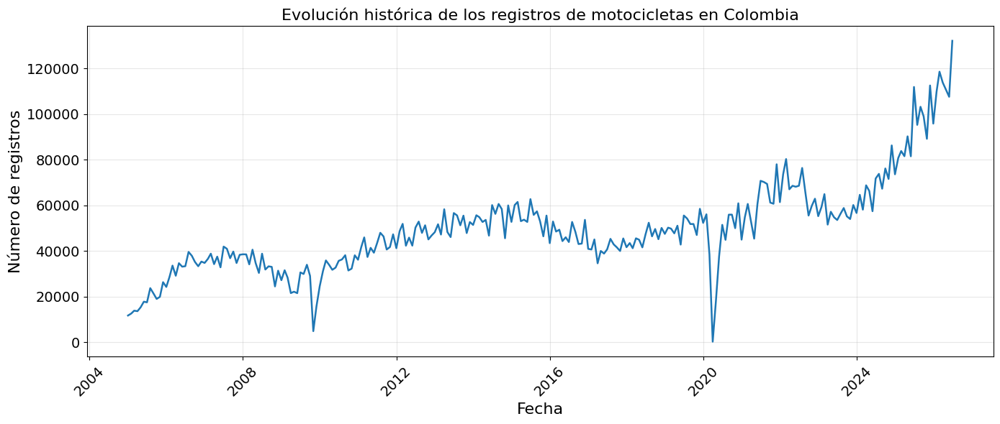

In [11]:
plt.figure(figsize=(14, 6))

plt.plot(
    objetivo["Fecha"],
    objetivo["Registros"],
    linewidth=1.8
)

# Título
plt.title(
    "Evolución histórica de los registros de motocicletas en Colombia",
    fontsize=16
)

# Etiquetas de los ejes
plt.xlabel("Fecha", fontsize=16)
plt.ylabel("Número de registros", fontsize=16)

# Tamaño de los valores de los ejes
plt.xticks(fontsize=14, rotation=45)
plt.yticks(fontsize=14)

# Cuadrícula
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

La gráfica resume la distribución mensual de los registros dentro de cada año. La mediana anual confirma los ciclos descritos: crecimiento hasta 2007, retroceso en 2009, expansión entre 2011 y 2015, contracción en 2016-2017 y un nuevo ciclo expansivo desde 2021. Se destaca la alta dispersión de 2020, cuyo rango va desde valores cercanos a cero hasta niveles similares a los de 2019, reflejando el decrecimiento y la posterior recuperación dentro del mismo año. De igual forma, 2025 presenta una caja amplia que evidencia un crecimiento acelerado mes a mes, y 2026 se ubica en un nivel superior, con una mediana cercana a 110 mil unidades.

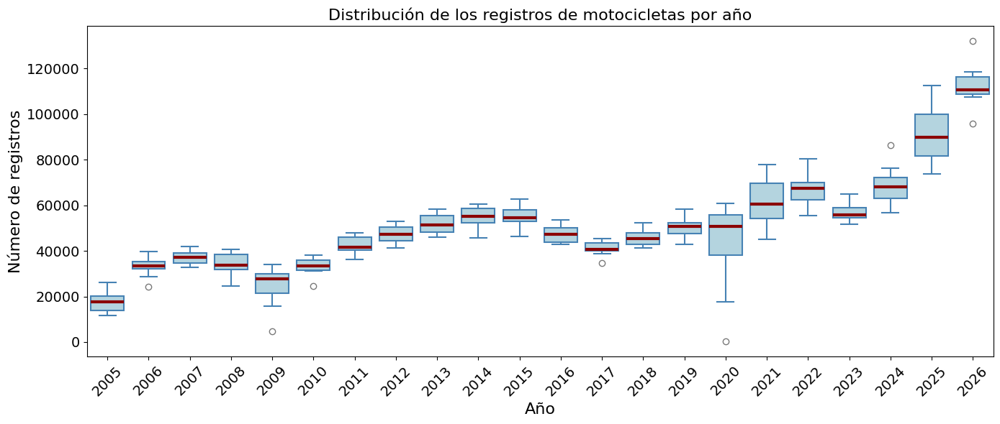

In [12]:
# Extraer el año de la fecha
objetivo["Año"] = objetivo["Fecha"].dt.year

# Distribución de registros por año
plt.figure(figsize=(14, 6))

#sns.boxplot(
    #data=objetivo,
    #x="Año",
    #y="Registros"
#)


sns.boxplot(
    data=objetivo,
    x="Año",
    y="Registros",
    color="lightblue",
    medianprops=dict(color="darkred", linewidth=3),
    boxprops=dict(edgecolor="steelblue", linewidth=1.5),
    whiskerprops=dict(color="steelblue", linewidth=1.5),
    capprops=dict(color="steelblue", linewidth=1.5)
)

plt.title("Distribución de los registros de motocicletas por año", fontsize=16)

# Etiquetas de los ejes
plt.xlabel("Año", fontsize=16)
plt.ylabel("Número de registros", fontsize=16)

# Tamaño de los valores de los ejes
plt.xticks(fontsize=14, rotation=45)
plt.yticks(fontsize=14)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

La gráfica muestra un patrón estacional intra-anual consistente. Julio es el mes con mayor promedio histórico (55.351 unidades), seguido de diciembre (53.101) y agosto (51.980); mientras que noviembre (44.573) y enero (45.612) registran los promedios más bajos. Los picos de julio y diciembre podrían estar asociados al pago de las primas de servicios a mitad y final de año, que incrementa la capacidad de compra de los hogares, mientras que la caída de enero coincide con el cierre de temporada y vacaciones. Asimismo, abril también presenta bajos registros en promedio (46.768) debido a vacaciones de semana santa. Es importante tener en cuenta que los meses de enero a julio incluyen las observaciones de 2026, año de niveles récord, lo cual eleva ligeramente su promedio frente a los meses de agosto a diciembre.

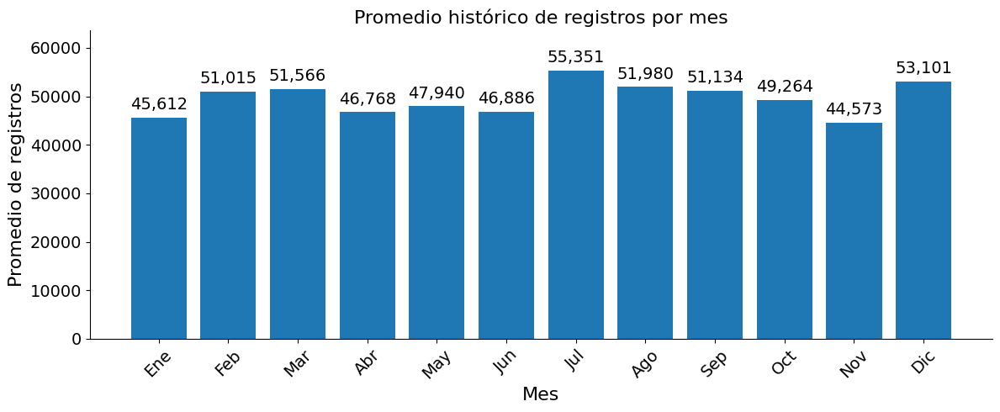

In [13]:
objetivo["Mes"] = objetivo["Fecha"].dt.month

nombres_meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

promedio_mensual = (
    objetivo.groupby("Mes")["Registros"]
    .mean()
    .reindex(range(1, 13))
)

plt.figure(figsize=(12, 5))

barras = plt.bar(nombres_meses, promedio_mensual.values)

# Mostrar etiquetas en cada barra
plt.bar_label(
    barras,
    labels=[f"{valor:,.0f}" for valor in promedio_mensual.values],
    padding=4,
    fontsize=14
)

plt.title("Promedio histórico de registros por mes", fontsize = 16)
plt.xlabel("Mes", fontsize = 16)
plt.ylabel("Promedio de registros", fontsize = 16)

# Tamaño de los valores de los ejes
plt.xticks(fontsize=14, rotation=45)
plt.yticks(fontsize=14)

# Quitar bordes superior y derecho
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Dar espacio adicional en la parte superior
plt.margins(y=0.15)

plt.tight_layout()
plt.show()

La gráfica complementa el análisis anterior mostrando la variabilidad de los registros en cada mes calendario. Las medianas mensuales presentan poca variación y se mantienen dentro de un intervalo comprendido entre 43 y 53 mil unidades. No obstante, la amplitud de las cajas evidencia una mayor dispersión de los registros entre años que entre meses, lo que indica que la variabilidad entre años (efecto tendencia) es mayor que la variabilidad entre meses (efecto estacional). Los valores atípicos superiores, presentes en todos los meses, corresponden a los años 2025 y 2026, mientras que los atípicos inferiores se concentran en enero (inicio de la serie en 2005), abril (confinamiento de 2020) y noviembre (caída puntual de 2009).

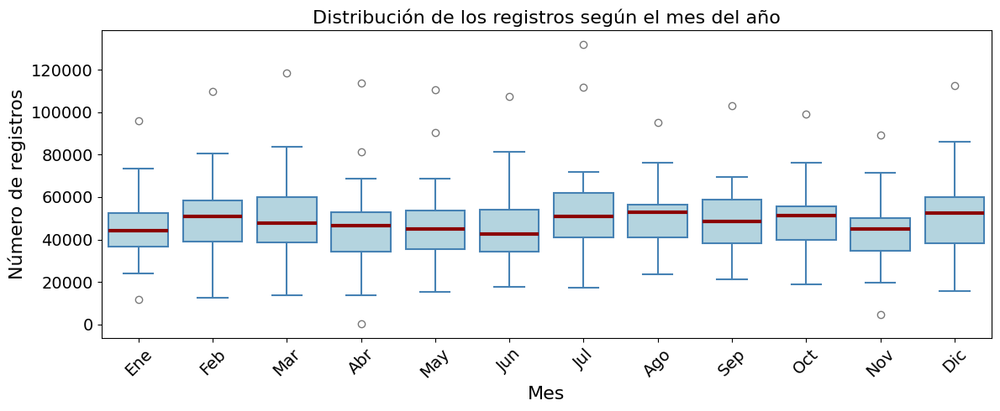

In [14]:

# Distribución de registros por mes calendario
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=objetivo,
    x="Mes",
    y="Registros",
    color="lightblue",
    medianprops=dict(color="darkred", linewidth=3),
    boxprops=dict(edgecolor="steelblue", linewidth=1.5),
    whiskerprops=dict(color="steelblue", linewidth=1.5),
    capprops=dict(color="steelblue", linewidth=1.5)
)


plt.xticks(range(12), nombres_meses)
plt.title("Distribución de los registros según el mes del año", fontsize= 16)
plt.xlabel("Mes", fontsize= 16)
plt.ylabel("Número de registros", fontsize= 16)


# Tamaño de los valores de los ejes
plt.xticks(fontsize=14, rotation=45)
plt.yticks(fontsize=14)

plt.tight_layout()
plt.show()

In [15]:
#Posibles Valores Atípicos

serie = objetivo["Registros"].dropna()

q1 = serie.quantile(0.25)
q3 = serie.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos = objetivo[
    (objetivo["Registros"] < limite_inferior) |
    (objetivo["Registros"] > limite_superior)
]

display(atipicos[["Fecha", "Registros"]])

print("Cantidad de posibles valores atípicos:", len(atipicos))

,Fecha,Registros
58,2009-11-01,4813
183,2020-04-01,202
239,2024-12-01,86239
244,2025-05-01,90212
246,2025-07-01,111861
247,2025-08-01,95242
248,2025-09-01,103166
249,2025-10-01,98990
250,2025-11-01,89130
251,2025-12-01,112509


Cantidad de posibles valores atípicos: 17


La descomposición de la serie separa sus componentes de tendencia, estacionalidad y residuo. La tendencia reproduce los ciclos del mercado y evidencia la fuerte pendiente positiva desde 2024. El componente estacional presenta un patrón regular y estable, con una amplitud aproximada de ±5.000 unidades, esto evidencia un patrón cíclico que se repite de manera regular a lo largo del período analizado, lo que confirma la presencia de estacionalidad anual en los registros de motocicletas. Las oscilaciones alrededor de cero reflejan el efecto sistemático de cada mes sobre el comportamiento de la serie, indicando períodos en los que los registros tienden a situarse por encima o por debajo de la tendencia. Asimismo, la magnitud relativamente constante de estas fluctuaciones sugiere que el efecto estacional se mantiene estable en el tiempo. El residuo se mantiene cercano a cero en la mayor parte del periodo, con excepción de choques negativos marcados en 2009 y 2020 y de una mayor dispersión a partir de 2020.

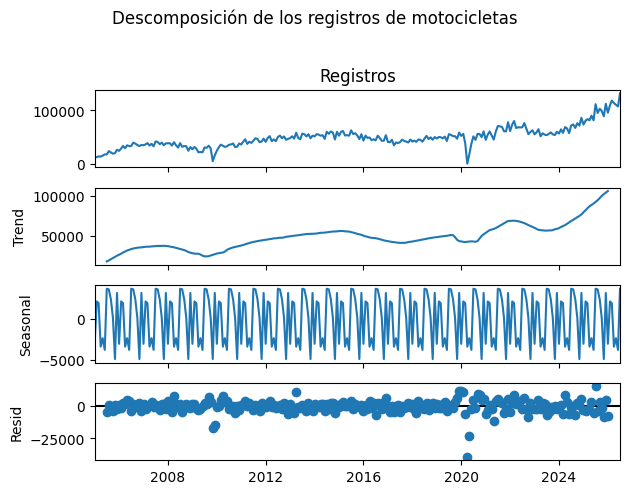

In [16]:
# La descomposición requiere una serie mensual regular y sin faltantes.
serie_mensual = (
    df_datamarket_men.set_index("Fecha")["Registros"]
      .groupby(lambda x: x.to_period("M"))
      .sum(min_count=1)
)

serie_mensual.index = serie_mensual.index.to_timestamp()

# Comprobar continuidad y valores faltantes antes de continuar
serie_mensual = serie_mensual.asfreq("MS")

if serie_mensual.isna().any():
    print("Hay meses faltantes. Investiga y resuelve esos faltantes antes de descomponer.")
elif len(serie_mensual) < 24:
    print("Se recomienda contar con al menos dos ciclos anuales completos.")
else:
    descomposicion = seasonal_decompose(
        serie_mensual,
        model="additive",
        period=12
    )

    descomposicion.plot()
    plt.suptitle("Descomposición de los registros de motocicletas", y=1.02)
    plt.tight_layout()
    plt.show()

####Variables Predictoras: Variables Macroeconómicas

#####Variables: Periodicidad Mensual

Las variables predictoras mensuales recogen información del mercado laboral, la tasa de cambio, las condiciones monetarias, la inflación, el ingreso mínimo, la percepción de los consumidores y el calendario. A continuación, se analiza su evolución histórica y su distribución.



In [17]:
#Calidad de la data

variables_predictoras = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

# Conservar únicamente las columnas que existan en la base
variables_predictoras = [
    col for col in variables_predictoras
    if col in df_datamarket_men.columns
]

predictores = df_datamarket_men[variables_predictoras].copy()

for col in variables_predictoras:
    predictores[col] = pd.to_numeric(
        predictores[col], errors="coerce"
    )

inventario = pd.DataFrame({
    "No_nulos": predictores.notna().sum(),
    "Faltantes": predictores.isna().sum(),
    "Porcentaje_faltantes": predictores.isna().mean() * 100,
    "Valores_unicos": predictores.nunique()
})

display(inventario.round(2))

,No_nulos,Faltantes,Porcentaje_faltantes,Valores_unicos
PoblacionTotal,259,0,0.00,259
PoblacionOcupada,259,0,0.00,259
PoblacionDesocupada,259,0,0.00,259
TasaOcupacion,259,0,0.00,259
TasaDesocupacion,259,0,0.00,257
TRM,259,0,0.00,257
Var.TRM,258,1,0.39,258
TasaInteres,259,0,0.00,43
DTF,259,0,0.00,213
InflacionAnual,259,0,0.00,218


In [18]:
#Métricas Estadísticas

display(predictores.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
PoblacionTotal,259.0,46075.512,3755.770,40318.940,42844.232,45482.981,49739.386,52584.648
PoblacionOcupada,259.0,20074.368,2289.872,15572.558,18363.613,20384.009,21535.027,24598.645
PoblacionDesocupada,259.0,2458.657,473.956,1763.467,2142.199,2349.787,2632.812,4695.063
TasaOcupacion,259.0,0.582,0.030,0.425,0.569,0.586,0.601,0.640
TasaDesocupacion,259.0,0.110,0.022,0.070,0.095,0.107,0.120,0.220
TRM,259.0,2850.731,887.069,1712.280,1979.395,2860.000,3693.000,4922.300
Var.TRM,258.0,0.002,0.033,-0.072,-0.017,-0.003,0.018,0.135
TasaInteres,259.0,0.063,0.031,0.018,0.041,0.052,0.092,0.132
DTF,259.0,0.064,0.028,0.018,0.044,0.054,0.087,0.144
InflacionAnual,259.0,0.049,0.026,0.015,0.032,0.044,0.059,0.133


La gráfica permite agrupar las variables mensuales según su comportamiento:

**•	Variables demográficas y laborales:** La población total crece de forma continua y casi lineal, con un salto alrededor de 2014 y una aceleración entre 2017 y 2020, debido al flujo migratorio de ese periodo. La población ocupada también presenta tendencia creciente con estacionalidad, una caída abrupta en 2020 y una recuperación que la lleva a máximos históricos. La población desocupada y la tasa de desocupación oscilan alrededor de niveles estables, registran un pico en 2020 (la tasa de desocupación supera el 20%) y descienden posteriormente hasta niveles cercanos al 8%, los más bajos del periodo. La tasa de ocupación muestra el comportamiento inverso.

**•	Tasa de cambio:** La TRM se mantiene entre 1.800 y 2.500 pesos hasta 2014, se devalúa fuertemente a partir de 2015, alcanza su máximo cercano a 4.900 pesos en 2022 y luego desciende. Su variación mensual (Var. TRM) oscila alrededor de cero sin tendencia, lo que sugiere un comportamiento estacionario.

**•	Variables monetarias e inflación:** La tasa de interés de política monetaria y la DTF presentan ciclos prácticamente idénticos, con máximos en 2008, 2016 y 2023 y mínimos históricos en 2020-2021. La inflación anual sigue un ciclo similar, con picos en 2008, 2016 y cerca del 13% en 2023, lo cual evidencia la reacción de la política monetaria frente a la inflación. La inflación mensual es más volátil y no muestra tendencia.

**•	Salario mínimo y días hábiles:** El SMMLV crece de forma escalonada, con incrementos una vez al año, y se acelera en los últimos años. Los días hábiles oscilan entre 22 y 27 sin tendencia, por ser una variable puramente de calendario.

**•	Índices de confianza:** ICC, IEC e ICE se mueven de forma casi paralela: niveles altos entre 2005 y 2014, deterioro desde 2015, mínimos en 2020, nuevo deterioro en 2022-2023 y recuperación en 2025-2026. Este movimiento conjunto anticipa una alta correlación entre ellos.

En conjunto, varias de las predictoras (población, población ocupada, TRM y SMMLV) comparten con los registros una tendencia creciente, mientras que otras son cíclicas o estacionarias. Esta diferencia es relevante, ya que la correlación entre series con tendencia puede ser en parte espuria.



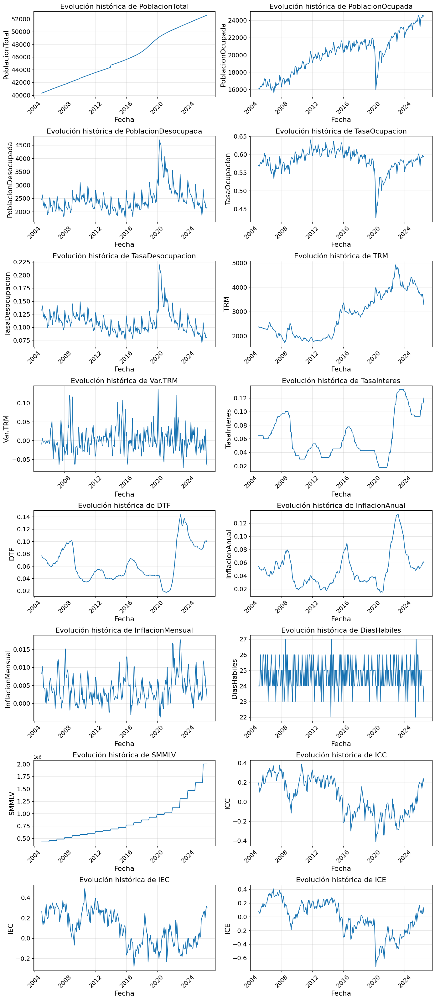

In [19]:
n_variables = len(variables_predictoras)

ncols = 2
nrows = math.ceil(n_variables / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(14, 4 * nrows)
)

# Convertir los ejes en una lista, incluso si hay una sola fila
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i, col in enumerate(variables_predictoras):

    datos = (
        df_datamarket_men[["Fecha", col]]
        .dropna()
        .sort_values("Fecha")
    )

    ax = axes[i]

    if datos.empty:
        ax.set_visible(False)
        continue

    ax.plot(datos["Fecha"], datos[col], linewidth=1.5)

    ax.set_title(f"Evolución histórica de {col}", fontsize = 16)

    # Etiquetas de los ejes
    ax.set_xlabel("Fecha", fontsize=16)
    ax.set_ylabel(col, fontsize=16)

    # Tamaño de los números y fechas de los ejes
    ax.tick_params(axis="both", labelsize=14)

    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, alpha=0.3)

# Ocultar espacios sobrantes en la cuadrícula
for j in range(n_variables, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

La siguiente gráfica presenta el histograma y el diagrama de caja de cada variable mensual. Se identifican tres tipos de comportamiento:

**•	Distribuciones multimodales o aplanadas:** (población total, población ocupada, TRM, tasa de interés, DTF, ICC e IEC), que reflejan los distintos regímenes o niveles que ha tenido la variable en el tiempo más que una dispersión aleatoria. No presentan valores atípicos.

**•	Distribuciones con asimetría positiva y valores atípicos superiores:** (población desocupada, tasa de desocupación, inflación anual, inflación mensual, SMMLV y Var.TRM). Los atípicos se concentran en episodios específicos: la pandemia de 2020 para el desempleo, el ciclo inflacionario de 2022-2023 para la inflación y el último año para el SMMLV.

**•	Distribuciones con asimetría negativa:** (tasa de ocupación e ICE), cuyos valores atípicos inferiores corresponden también a 2020. Los días hábiles tienen una distribución discreta concentrada en 24 y 25 días.

Estos resultados indican que las variables tienen escalas muy diferentes, por lo que será necesario estandarizarlas para los modelos de Machine Learning. Los valores atípicos corresponden a eventos económicos reales, por lo que se recomienda conservarlos y controlarlos mediante variables indicadoras.


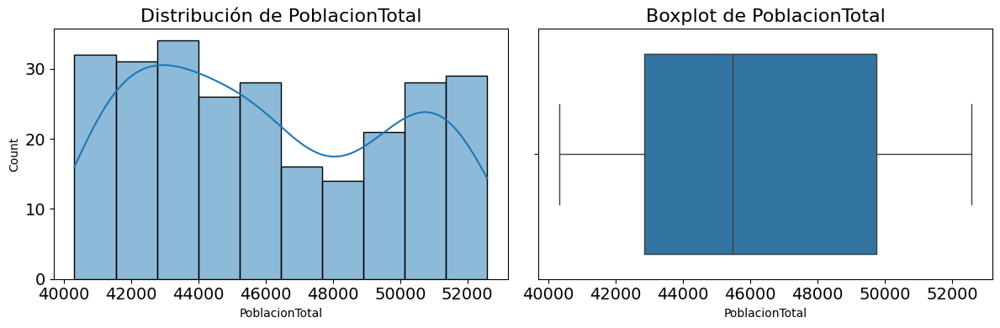

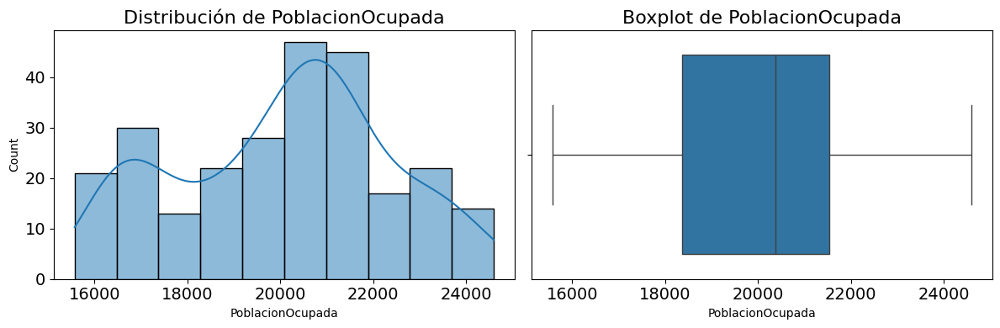

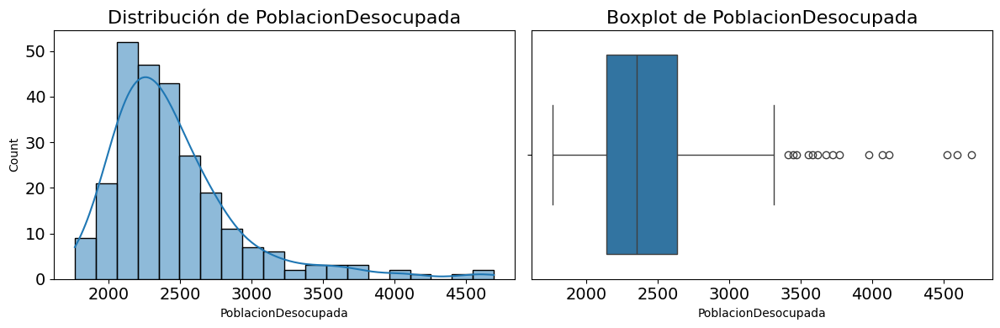

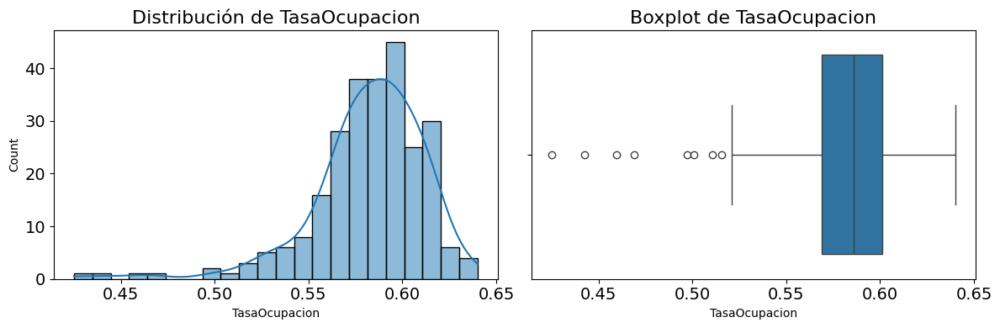

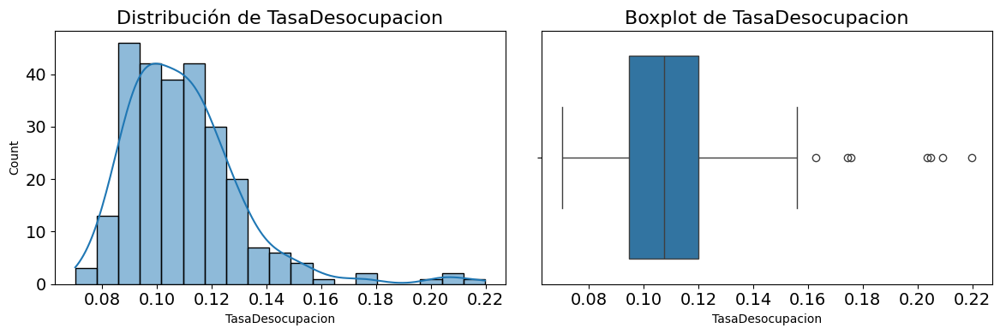

...

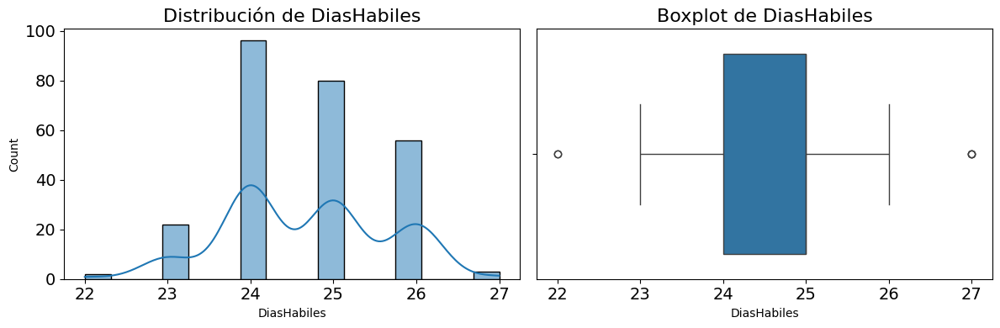

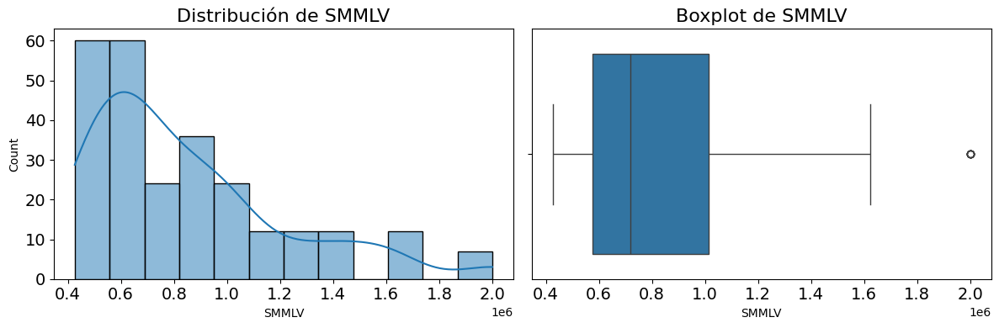

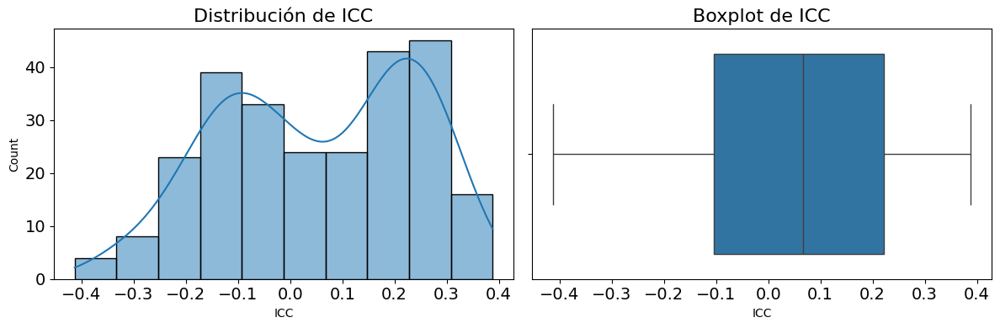

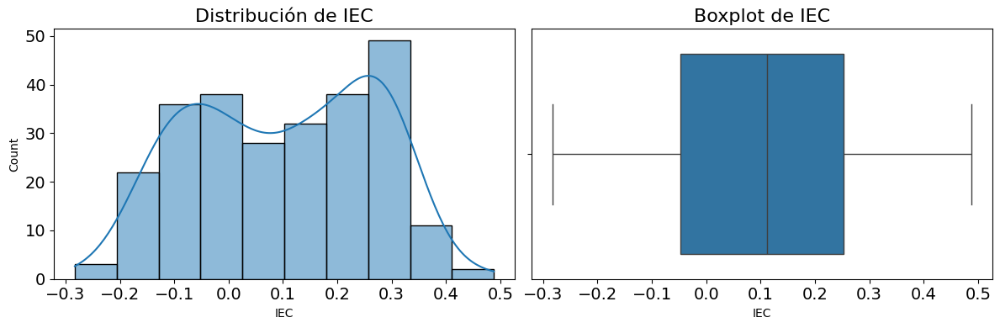

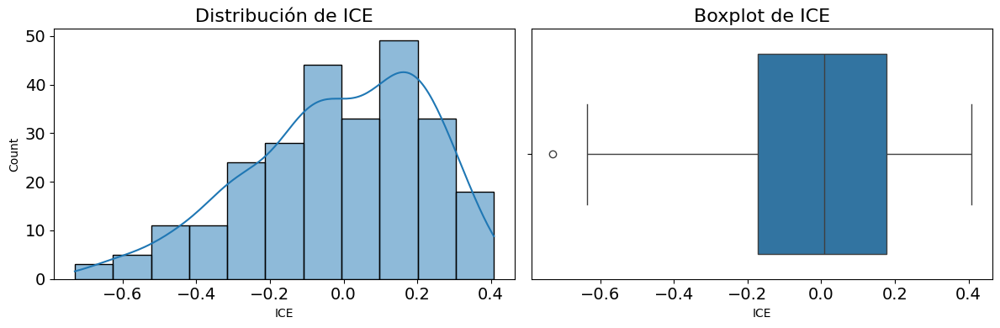

In [20]:
for col in variables_predictoras:

    datos = predictores[col].dropna()

    if datos.empty:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(datos, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribución de {col}", fontsize=16)

    sns.boxplot(x=datos, ax=axes[1])
    axes[1].set_title(f"Boxplot de {col}", fontsize=16)

    # Tamaño de los números de los ejes en ambos gráficos
    for ax in axes:
        ax.tick_params(axis="both", labelsize=14)

    plt.tight_layout()
    plt.show()

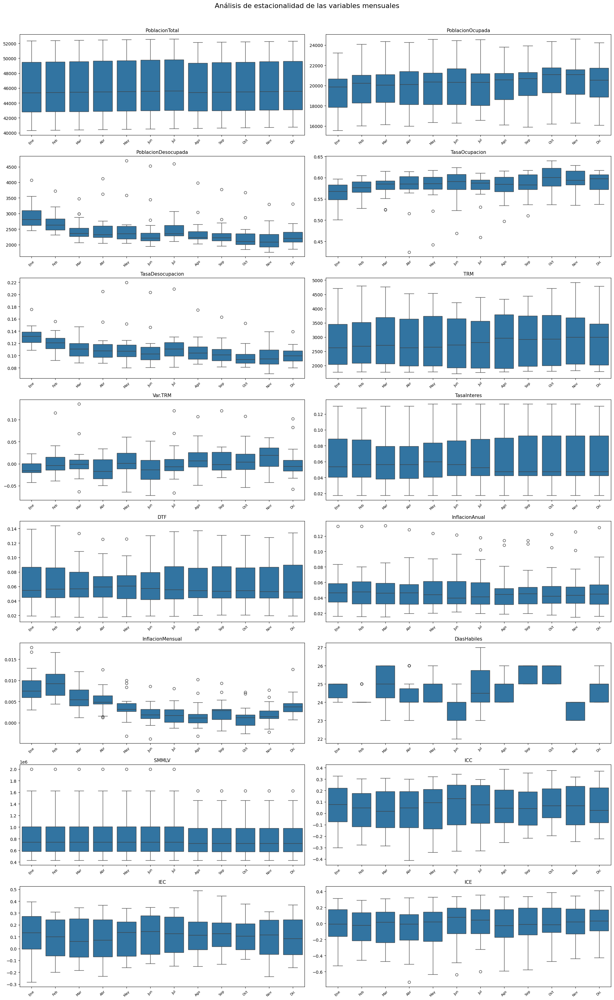

In [21]:
nombres_meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

variables_mensuales = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

# Filtrar variables disponibles
variables_disponibles = [
    col for col in variables_mensuales
    if col in df_datamarket_men.columns
]

# Definir cuadrícula
ncols = 2
nrows = math.ceil(len(variables_disponibles) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(20, 4 * nrows)
)

axes = axes.flatten()

for i, col in enumerate(variables_disponibles):

    temporal = df_datamarket_men[
        ["Fecha", col]
    ].dropna().copy()

    temporal["Mes"] = temporal["Fecha"].dt.month

    sns.boxplot(
        data=temporal,
        x="Mes",
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    axes[i].set_xticks(range(12))
    axes[i].set_xticklabels(nombres_meses, rotation=45, fontsize=8)

# Eliminar ejes vacíos
for j in range(len(variables_disponibles), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Análisis de estacionalidad de las variables mensuales",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

#####Variables: Periodicidad Trimestral

Las variables trimestrales describen la actividad económica agregada y el sector externo del país.

In [22]:
#Calidad de la data

variables_predictoras = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas"
]

# Conservar únicamente las columnas que existan en la base
variables_predictoras = [
    col for col in variables_predictoras
    if col in df_datamarket_trim.columns
]

predictores = df_datamarket_trim[variables_predictoras].copy()

for col in variables_predictoras:
    predictores[col] = pd.to_numeric(
        predictores[col], errors="coerce"
    )

inventario = pd.DataFrame({
    "No_nulos": predictores.notna().sum(),
    "Faltantes": predictores.isna().sum(),
    "Porcentaje_faltantes": predictores.isna().mean() * 100,
    "Valores_unicos": predictores.nunique()
})

display(inventario.round(2))

,No_nulos,Faltantes,Porcentaje_faltantes,Valores_unicos
PIB,86,0,0.00,86
Var.PIB,85,1,1.16,85
Exportaciones,86,0,0.00,86
Importaciones,86,0,0.00,86
Remesas,86,0,0.00,86


In [23]:
#Métricas Estadísticas

display(predictores.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
PIB,86.0,195860.250,38848.961,126088.657,159262.015,200982.445,221924.416,262061.542
Var.PIB,85.0,0.009,0.025,-0.162,0.004,0.008,0.015,0.099
Exportaciones,86.0,29760.482,4022.718,21334.353,25944.901,30801.073,32907.607,36079.445
Importaciones,86.0,42705.260,13024.832,18667.178,30688.300,44290.312,50785.145,67264.113
Remesas,86.0,1596.102,746.823,731.130,1012.065,1280.355,1941.225,3354.000


La gráfica muestra que el PIB crece de manera sostenida durante todo el periodo, con una desaceleración en 2009, una caída abrupta en el segundo trimestre de 2020 y una recuperación que supera el nivel previo a la pandemia desde 2021. Este cambio se observa con claridad en la variación trimestral del PIB, que se mantiene cerca de cero en condiciones normales, cae alrededor de 16% en 2020 y rebota cerca de 10% en el trimestre siguiente. Las exportaciones crecen hasta 2013, se estabilizan y presentan la misma caída en 2020. Las importaciones muestran un crecimiento más pronunciado, con caídas en 2009 y 2020, un máximo en 2022, un ajuste en 2023 y una nueva recuperación hasta máximos en 2026; esta variable es especialmente relevante para el sector, dado que la producción local depende de la importación de kits CKD. Las remesas permanecen estables entre 2008 y 2015 y, desde 2016, crecen de forma acelerada hasta triplicar su nivel, comportamiento similar al de los registros en los últimos años. Finalmente, el PIB per cápita replica la trayectoria del PIB, pero con un crecimiento más moderado desde 2022 debido al aumento de la población.

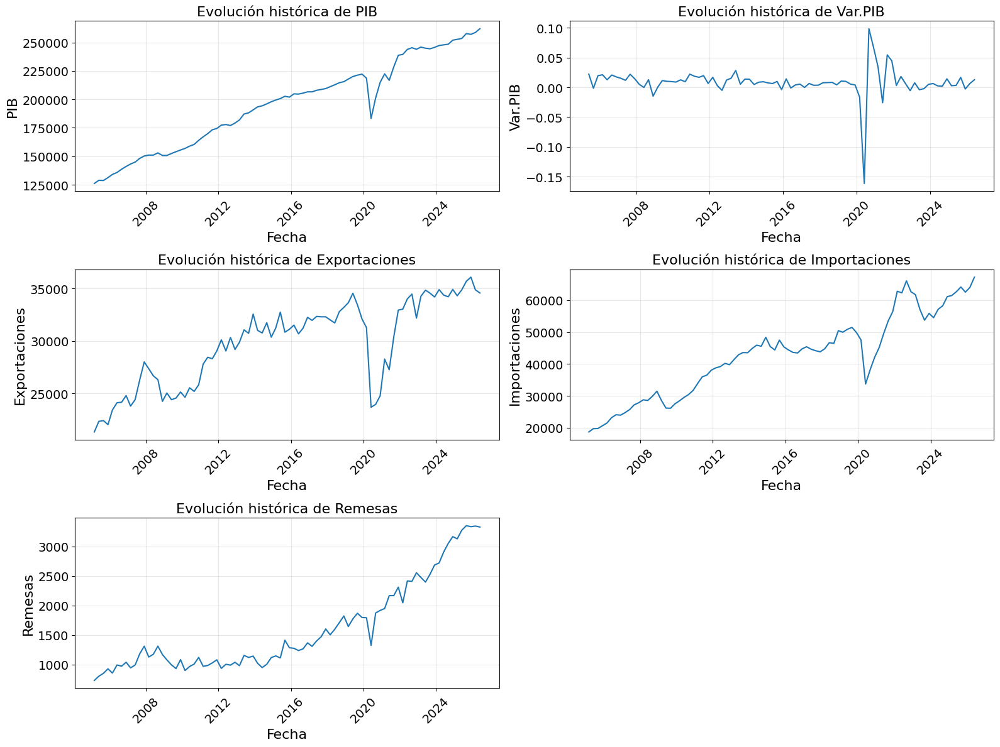

In [24]:

n_variables = len(variables_predictoras)

ncols = 2
nrows = math.ceil(n_variables / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(16, 4 * nrows)
)

# Convertir los ejes en una lista, incluso si hay una sola fila
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i, col in enumerate(variables_predictoras):

    datos = (
        df_datamarket_trim[["FechaFin", col]]
        .dropna()
        .sort_values("FechaFin")
    )

    ax = axes[i]

    if datos.empty:
        ax.set_visible(False)
        continue

    ax.plot(datos["FechaFin"], datos[col], linewidth=1.5)

    ax.set_title(f"Evolución histórica de {col}", fontsize = 16)

    # Etiquetas de los ejes
    ax.set_xlabel("Fecha", fontsize=16)
    ax.set_ylabel(col, fontsize=16)

    # Tamaño de los números y fechas de los ejes
    ax.tick_params(axis="both", labelsize=14)

    # Rotación de las fechas
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, alpha=0.3)

# Ocultar espacios sobrantes en la cuadrícula
for j in range(n_variables, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

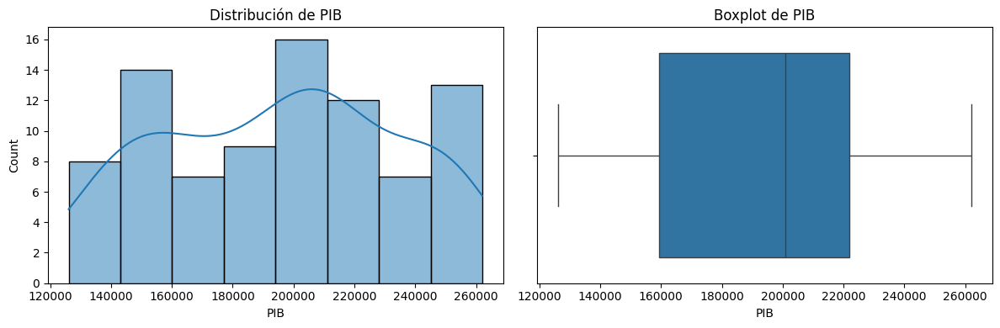

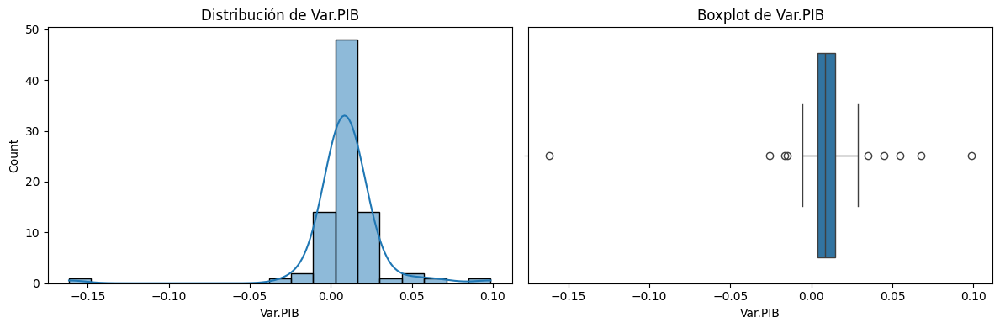

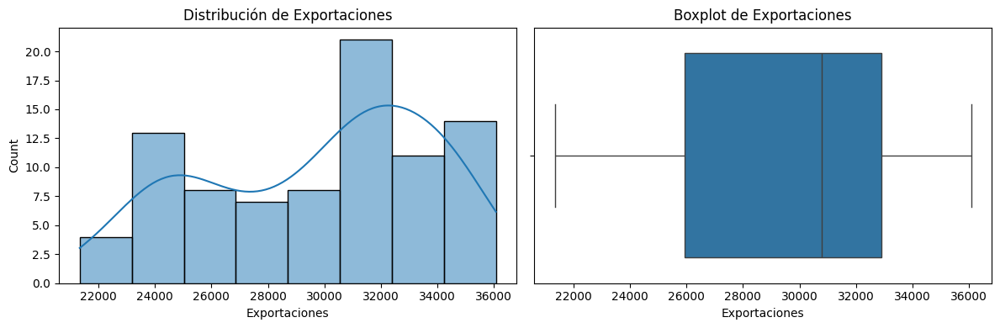

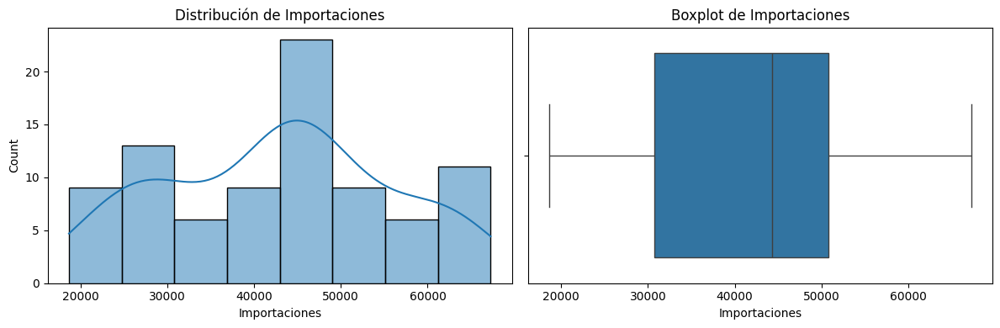

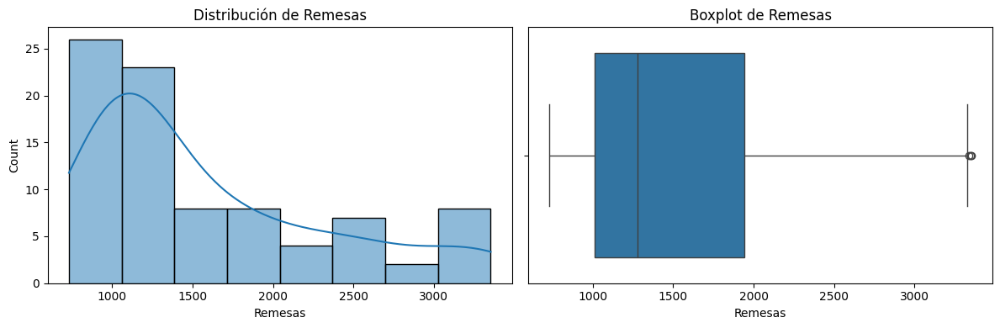

In [25]:
for col in variables_predictoras:

    datos = predictores[col].dropna()

    if datos.empty:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(datos, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribución de {col}")

    sns.boxplot(x=datos, ax=axes[1])
    axes[1].set_title(f"Boxplot de {col}")

    plt.tight_layout()
    plt.show()

La gráfica compara la distribución de cada variable trimestral según el trimestre del año. Las cajas de PIB, exportaciones e importaciones son prácticamente iguales entre T1 y T4, lo cual confirma la ausencia de estacionalidad esperada por tratarse de series desestacionalizadas; en consecuencia, la estacionalidad del modelo deberá provenir de la variable objetivo. Las remesas muestran una mediana ligeramente mayor en el segundo semestre, aunque la diferencia es pequeña. La variación del PIB concentra sus valores cerca de cero y sus atípicos corresponden a la caída de 2020 (T2) y a las recuperaciones posteriores (T3 y T4).

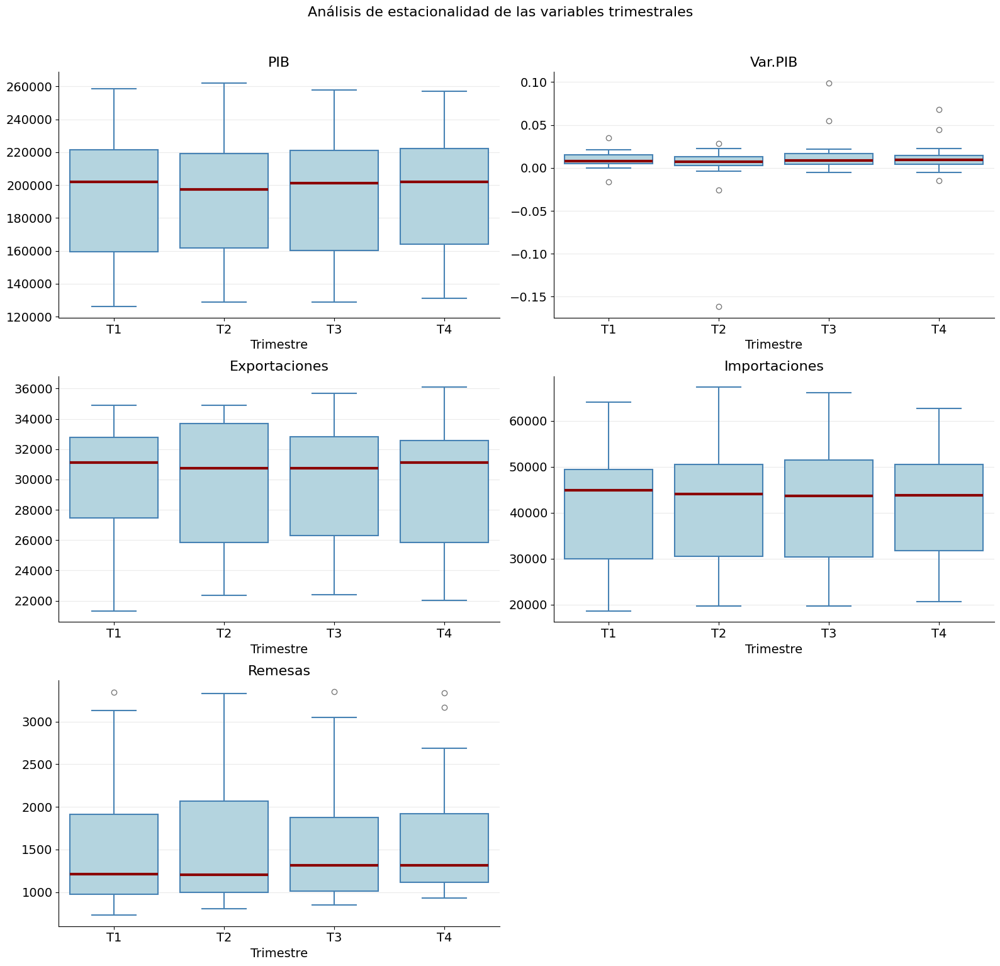

In [26]:
nombres_trimestres = ["T1", "T2", "T3", "T4"]

variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas"
]

# Conservar únicamente las variables que existen en el DataFrame
variables_disponibles = [
    col for col in variables_trimestrales
    if col in df_datamarket_trim.columns
]

ncols = 2
nrows = math.ceil(len(variables_disponibles) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(16, 5 * nrows)
)

axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i, col in enumerate(variables_disponibles):

    temporal = df_datamarket_trim[["FechaFin", col]].dropna().copy()

    temporal["Trimestre"] = temporal["FechaFin"].dt.quarter

    sns.boxplot(
        data=temporal,
        x="Trimestre",
        y=col,
        ax=axes[i],
        color="lightblue",
        medianprops=dict(color="darkred", linewidth=3),
        boxprops=dict(edgecolor="steelblue", linewidth=1.5),
        whiskerprops=dict(color="steelblue", linewidth=1.5),
        capprops=dict(color="steelblue", linewidth=1.5)
    )

    # Título y etiquetas
    axes[i].set_title(col, fontsize=16)
    axes[i].set_xlabel("Trimestre", fontsize=14)
    axes[i].set_ylabel("", fontsize=14)

    # Etiquetas de los trimestres
    axes[i].set_xticks(range(4))
    axes[i].set_xticklabels(nombres_trimestres)

    # Tamaño de los valores de los ejes
    axes[i].tick_params(axis="both", labelsize=14)

    # Eliminar bordes superior y derecho
    axes[i].spines["top"].set_visible(False)
    axes[i].spines["right"].set_visible(False)

    # Cuadrícula horizontal tenue
    axes[i].grid(axis="y", alpha=0.25)

# Eliminar espacios de gráficos que no se utilicen
for j in range(len(variables_disponibles), len(axes)):
    fig.delaxes(axes[j])

# Título general
fig.suptitle(
    "Análisis de estacionalidad de las variables trimestrales",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

####Relación entre las Variables

En esta etapa se analiza la relación entre los registros y cada variable predictora mediante gráficos de dispersión, matrices de correlación y correlaciones con rezagos, con el fin de identificar las variables con mayor potencial predictivo, detectar redundancias entre ellas y definir los rezagos a utilizar.

In [27]:
# Lista de predictores mensuales
variables_mensuales = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

# Conservar las variables disponibles
predictores_mensuales = [
    col for col in variables_mensuales
    if col in df_datamarket_men.columns
]


# Preparar las fechas sin modificar las bases originales
datos_objetivo = objetivo[["Fecha", "Registros"]].copy()
datos_predictores = df_datamarket_men[
    ["Fecha"] + predictores_mensuales
].copy()

datos_objetivo["Fecha"] = pd.to_datetime(datos_objetivo["Fecha"])
datos_predictores["Fecha"] = pd.to_datetime(datos_predictores["Fecha"])


# Integrar ambas bases
base_analisis = datos_objetivo.merge(
    datos_predictores,
    on="Fecha",
    how="inner",
    validate="one_to_one"
)

base_analisis = base_analisis.sort_values("Fecha").reset_index(drop=True)


columnas_correlacion = ["Registros"] + predictores_mensuales

corr_pearson = base_analisis[
    columnas_correlacion
].corr(method="pearson", numeric_only=True)

corr_spearman = base_analisis[
    columnas_correlacion
].corr(method="spearman", numeric_only=True)


La gráfica muestra que las relaciones más claras con los registros son positivas y aproximadamente lineales con el SMMLV, la población ocupada y la población total; en estas dos últimas, los puntos más recientes se ubican por encima de la recta, lo que sugiere una relación no lineal en el periodo de mayor crecimiento. En el caso del SMMLV, los puntos se agrupan en columnas verticales porque el salario se mantiene constante durante cada año. La TRM presenta una relación positiva moderada con dos nubes de puntos que corresponden al periodo previo y posterior a la devaluación de 2015. La tasa de desocupación muestra una relación negativa, coherente con la teoría económica. La tasa de interés, la DTF y la inflación presentan relaciones positivas débiles y muy dispersas, contrarias a lo esperado, lo que sugiere que su efecto no es contemporáneo o está mezclado con la tendencia general. Los índices de confianza (ICC, IEC e ICE) muestran una relación negativa débil, explicada en buena medida por el deterioro de la confianza en los mismos años en que el mercado creció. La población desocupada, la tasa de ocupación, la Var.TRM y los días hábiles no muestran una relación clara.

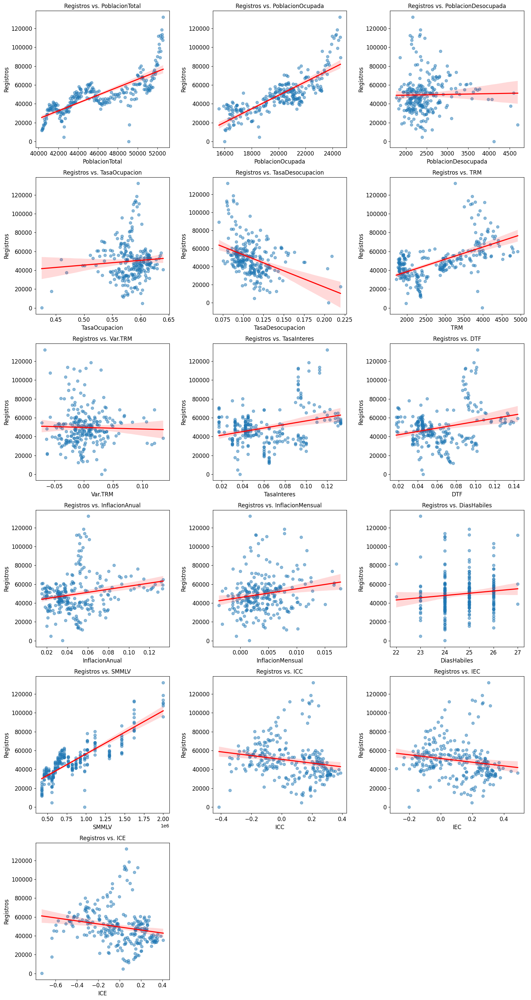

In [93]:
variables_graficos = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

variables_graficos = [
    col for col in variables_graficos
    if col in base_analisis.columns
]

ncols = 3
nrows = math.ceil(len(variables_graficos) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(16, 5 * nrows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(variables_graficos):

    temporal = base_analisis[
        ["Registros", col]
    ].dropna()

    sns.regplot(
        data=temporal,
        x=col,
        y="Registros",
        scatter_kws={"alpha": 0.5},
        line_kws={"color": "red"},
        ax=axes[i]
    )

    axes[i].set_title(f"Registros vs. {col}", fontsize = 12)

    # Tamaño de los nombres de los ejes
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel("Registros", fontsize=12)

    # Tamaño de los valores de los ejes
    axes[i].tick_params(axis="both", labelsize=12)


for j in range(len(variables_graficos), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Los registros trimestrales presentan una relación positiva, fuerte y lineal con el PIB, las exportaciones, las importaciones, las remesas y el PIB per cápita, lo cual es consistente con la literatura que vincula la demanda de motocicletas con la capacidad adquisitiva de los hogares. Sin embargo, los trimestres más recientes, con más de 250 mil registros, se ubican por encima de la recta, indicando que el crecimiento reciente del mercado es mayor al que explican estas variables por sí solas. La variación del PIB no muestra relación con los registros: la nube de puntos se concentra cerca de cero y la pendiente depende casi por completo del dato atípico de 2020.


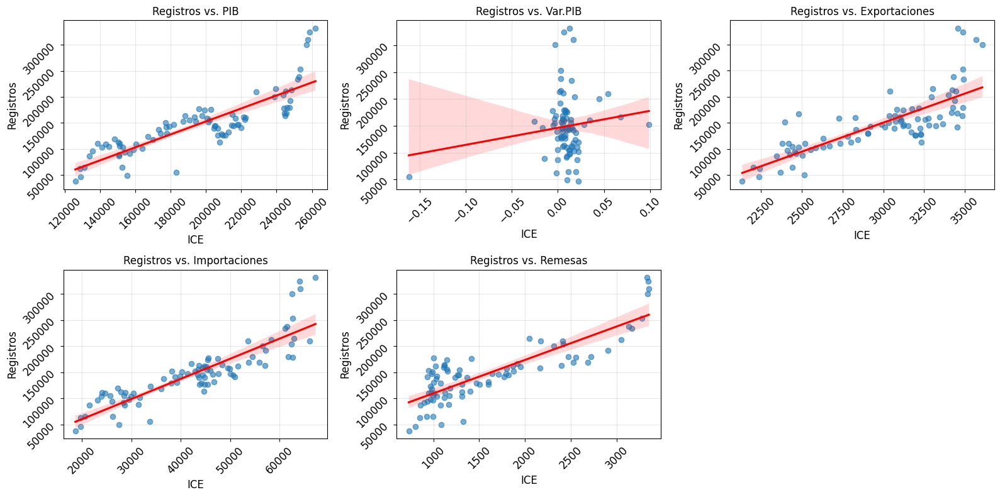

In [97]:
df = df_datamarket_trim.copy()

variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas"
]

ncols = 3
nrows = math.ceil(len(variables_trimestrales) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 4 * nrows)
)

axes = axes.flatten()

for i, variable in enumerate(variables_trimestrales):
    sns.regplot(
        data=df,
        x=variable,
        y="Registros",
        ax=axes[i],
        scatter_kws={"alpha": 0.6},
        line_kws={"color": "red"}
    )

    axes[i].set_title(f"Registros vs. {variable}", fontsize=12)
    axes[i].grid(True, alpha=0.3)


    # Tamaño de los nombres de los ejes
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel("Registros", fontsize=12)

    # Tamaño de los valores de los ejes
    axes[i].tick_params(axis="both", labelsize=12, labelrotation=45)

for j in range(len(variables_trimestrales), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

La matriz de correlación de Spearman permite explorar cómo se relacionan los registros de motocicletas con las dinámicas demográficas, laborales y económicas del país, proporcionando indicios sobre los factores que podrían estar asociados al comportamiento de la demanda. Los resultados sugieren que el crecimiento del mercado presenta una relación importante con la evolución de la población y del ingreso nominal, representado por variables como la población total (0,83), la población ocupada (0,82) y el salario mínimo (0,83). Estas asociaciones podrían reflejar el efecto conjunto del crecimiento demográfico y de la capacidad adquisitiva sobre la demanda potencial de motocicletas. Por otra parte, la correlación positiva observada con la TRM (0,59) y la relación negativa con la tasa de desocupación (-0,42) sugieren que las condiciones macroeconómicas y laborales también podrían estar vinculadas con la evolución del mercado.

Sin embargo, estas relaciones deben interpretarse considerando que las series presentan tendencias temporales y que la correlación no permite establecer efectos causales. Un aspecto relevante es la elevada correlación entre algunos predictores, como entre la tasa de interés y la DTF, así como entre los indicadores de confianza del consumidor, estas asociaciones evidencian la presencia de multicolinealidad potencial entre los mismos, aspecto que deberá considerarse durante la selección de variables.


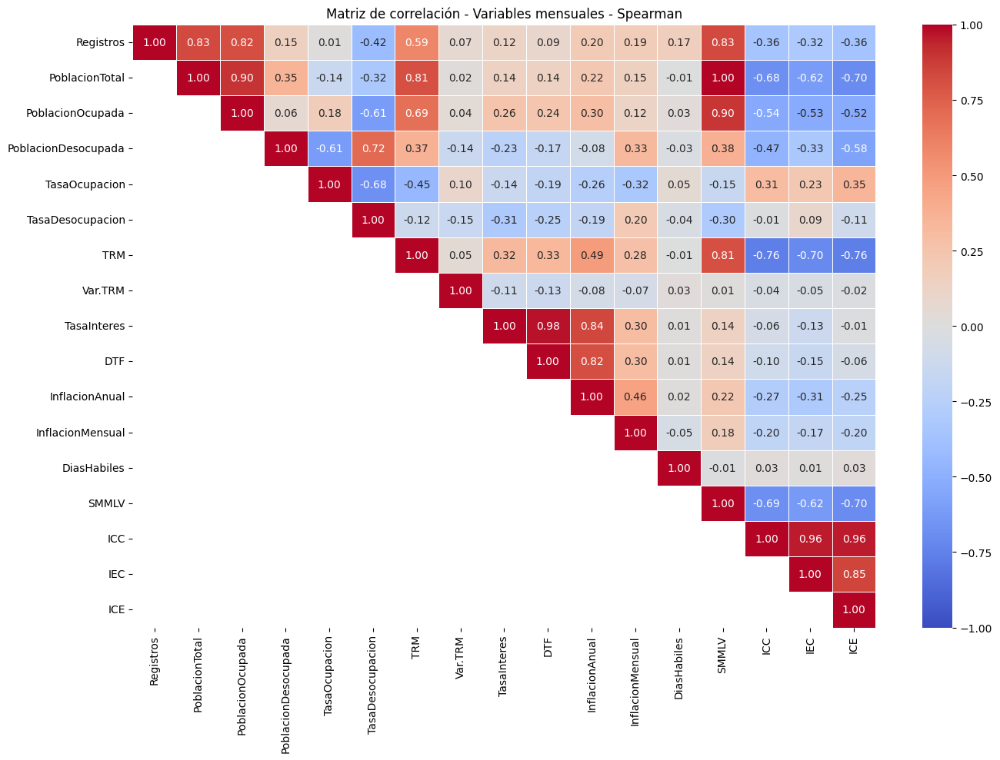

In [30]:
# Seleccionar variables numéricas
variables = df_datamarket_men.select_dtypes(include="number")

# Calcular la matriz de correlación de Spearman
matriz_corr = variables.corr(method="spearman")

# Crear máscara para ocultar el triángulo inferior
mascara = np.tril(np.ones_like(matriz_corr, dtype=bool), k=-1)

# Visualizar la matriz
plt.figure(figsize=(14, 10))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación - Variables mensuales - Spearman")
plt.tight_layout()
plt.show()


La matriz de Spearman trimestral muestra altas correlaciones entre los registros y todas las variables en niveles: importaciones (0,91), PIB (0,87), PIB per cápita (0,86), exportaciones (0,81) y remesas (0,76). La variación del PIB, en cambio, presenta una correlación ligeramente negativa (-0,13) y correlaciones negativas con las demás variables, lo que confirma que, a diferencia de las series en niveles, no comparte la tendencia de largo plazo. Entre predictoras, la multicolinealidad es muy alta: PIB, importaciones y PIB per cápita se correlacionan en 0,96 y 0,98 entre sí, y las exportaciones superan 0,91 con estas variables.


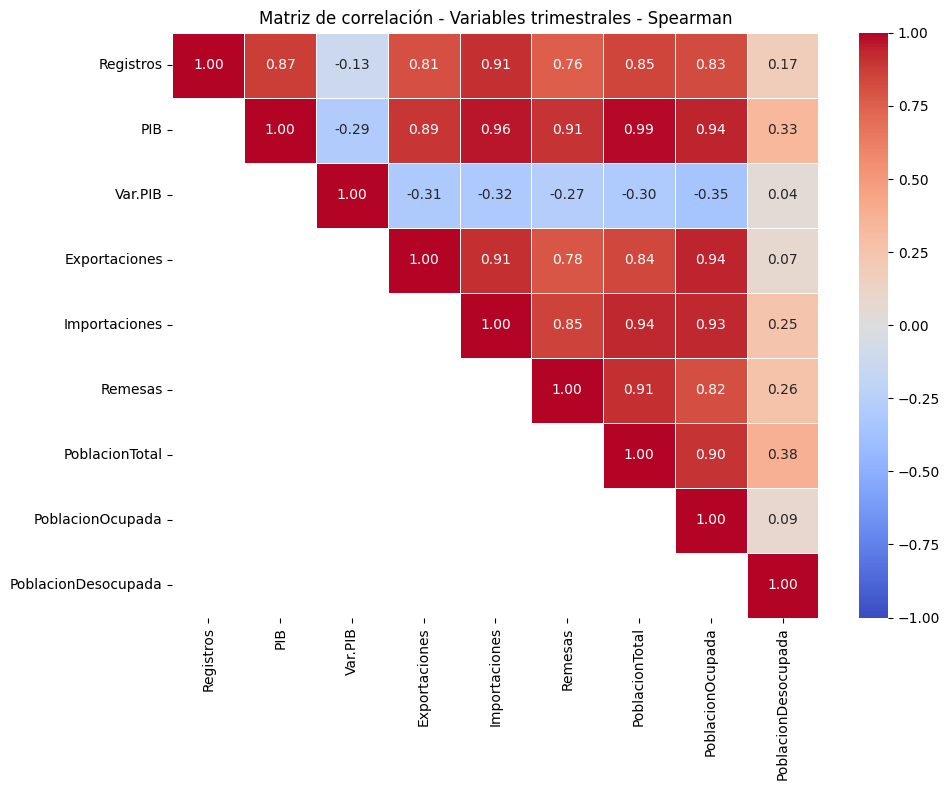

In [31]:
variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada"
]

# Seleccionar variables trimestrales + variable objetivo
variables_corr = ["Registros"] + variables_trimestrales

# Seleccionar únicamente las columnas de interés
datos_corr = df_datamarket_trim[variables_corr]

# Calcular la matriz de correlación de Pearson
matriz_corr = datos_corr.corr(method="spearman")

# Crear máscara para ocultar el triángulo inferior
mascara = np.tril(
    np.ones_like(matriz_corr, dtype=bool),
    k=-1
)

# Visualizar la matriz
plt.figure(figsize=(10, 8))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación - Variables trimestrales - Spearman")
plt.tight_layout()
plt.show()

In [32]:
resultados_rezagos = []

for col in predictores_mensuales:

    for lag in range(0, 13):

        temporal = base_analisis[
            ["Fecha", "Registros", col]
        ].copy()

        # Predictor observado lag meses antes
        temporal["Predictor_rezagado"] = temporal[col].shift(lag)

        temporal = temporal[
            ["Registros", "Predictor_rezagado"]
        ].dropna()

        if len(temporal) < 12:
            continue

        correlacion = temporal["Registros"].corr(
            temporal["Predictor_rezagado"],
            method="spearman"
        )

        resultados_rezagos.append({
            "Variable": col,
            "Rezago_meses": lag,
            "Correlacion_Spearman": correlacion,
            "Observaciones": len(temporal)
        })

tabla_rezagos = pd.DataFrame(resultados_rezagos)
display(tabla_rezagos)

,Variable,Rezago_meses,Correlacion_Spearman,Observaciones
0,PoblacionTotal,0,0.832766,259
1,PoblacionTotal,1,0.831013,258
2,PoblacionTotal,2,0.829202,257
3,PoblacionTotal,3,0.827363,256
4,PoblacionTotal,4,0.825476,255
...,...,...,...,...
203,ICE,8,-0.440433,251
204,ICE,9,-0.445332,250
205,ICE,10,-0.474486,249
206,ICE,11,-0.486811,248


In [33]:
mejores_rezagos = (
    tabla_rezagos
    .assign(
        Abs_Correlacion=lambda df:
            df["Correlacion_Spearman"].abs()
    )
    .sort_values(
        ["Variable", "Abs_Correlacion"],
        ascending=[True, False]
    )
    .groupby("Variable")
    .head(3)
    .sort_values("Variable")
)

display(mejores_rezagos)

,Variable,Rezago_meses,Correlacion_Spearman,Observaciones,Abs_Correlacion
116,DTF,12,-0.135083,247,0.135083
115,DTF,11,-0.124611,248,0.124611
114,DTF,10,-0.113592,249,0.113592
143,DiasHabiles,0,0.167785,259,0.167785
144,DiasHabiles,1,-0.101707,258,0.101707
154,DiasHabiles,11,0.078573,248,0.078573
181,ICC,12,-0.472618,247,0.472618
180,ICC,11,-0.470460,248,0.470460
179,ICC,10,-0.458942,249,0.458942
205,ICE,10,-0.474486,249,0.474486


In [34]:
variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas"
]

predictores_trim_disponibles = [
    col for col in variables_trimestrales
    if col in df_datamarket_trim.columns
]

# Registros mensuales agrupados por trimestre
datos_registros = objetivo[["Fecha", "Registros"]].copy()

datos_registros["Trimestre"] = (
    datos_registros["Fecha"].dt.to_period("Q")
)

registros_trim = (
    datos_registros
    .groupby("Trimestre", as_index=False)
    .agg(Registros=("Registros", "sum"))
)

# Preparar predictores trimestrales
datos_trim = df_datamarket_trim[
    ["FechaFin"] + predictores_trim_disponibles
].copy()

datos_trim["Trimestre"] = (
    datos_trim["FechaFin"].dt.to_period("Q")
)

# Verificar que exista un único registro por trimestre
print(
    "Trimestres duplicados en predictores:",
    datos_trim["Trimestre"].duplicated().sum()
)

# Integrar ambas bases por trimestre
base_trimestral = registros_trim.merge(
    datos_trim[["Trimestre"] + predictores_trim_disponibles],
    on="Trimestre",
    how="inner",
    validate="one_to_one"
)

display(base_trimestral.head())

Trimestres duplicados en predictores: 0


,Trimestre,Registros,PIB,Var.PIB,Exportaciones,Importaciones,Remesas
0,2005Q1,37999,126088.657004,NaN,21334.353184,18667.177575,731.13
1,2005Q2,46544,128906.474678,0.022348,22346.501950,19696.555294,803.26
2,2005Q3,62445,128717.054381,-0.001469,22416.208758,19760.125657,851.47
3,2005Q4,65080,131260.139968,0.019757,22034.764695,20628.289335,927.86
4,2006Q1,86446,134044.350100,0.021211,23431.599497,21467.411899,855.89


In [35]:
# Ordenar por fecha
df_datamercado = df_datamarket_men.sort_values("Fecha").copy()

# Identificar variables explicativas numéricas
variables_explicativas = [
    c for c in df_datamercado.select_dtypes(include="number").columns
    if c != "Registros"
]

# Evaluar rezagos trimestrales
rezagos = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

resultados = []

for variable in variables_explicativas:
    for rezago in rezagos:

        correlacion = df_datamercado["Registros"].corr(
            df_datamercado[variable].shift(rezago)
        )

        resultados.append({
            "Variable": variable,
            "Rezago_mensuales": rezago,
            "Correlacion": correlacion
        })

tabla_rezagos = pd.DataFrame(resultados)

print(
    tabla_rezagos.sort_values(
        "Correlacion",
        key=lambda x: x.abs(),
        ascending=False
    ).to_string(index=False)
)

           Variable  Rezago_mensuales  Correlacion
              SMMLV                 1     0.851407
              SMMLV                 2     0.848491
              SMMLV                 0     0.848283
              SMMLV                 6     0.845897
              SMMLV                 4     0.843916
              SMMLV                 3     0.843764
              SMMLV                 5     0.843362
              SMMLV                11     0.839600
              SMMLV                 7     0.836394
              SMMLV                12     0.836335
              SMMLV                 8     0.834937
              SMMLV                10     0.834908
              SMMLV                 9     0.834158
   PoblacionOcupada                 0     0.812779
   PoblacionOcupada                 1     0.784972
     PoblacionTotal                 0     0.777352
     PoblacionTotal                 1     0.776039
     PoblacionTotal                 2     0.774562
     PoblacionTotal            

Dado que las variables macroeconómicas deben proyectarse a futuro, la gráfica evalúa la correlación de los registros con cada variable mensual rezagada entre 0 y 12 meses. El SMMLV (0,83 a 0,85) y la población total (0,76 a 0,78) mantienen correlaciones altas y estables en todos los rezagos. La población ocupada pierde fuerza gradualmente (de 0,81 a 0,70), mientras que la TRM la aumenta levemente (de 0,57 a 0,62), lo que sugiere un efecto retardado de la tasa de cambio sobre el precio y la demanda. Los índices de confianza fortalecen su correlación negativa con el rezago (de cerca de 0,19 a -0,40 en el rezago de 12 meses). En contraste, la tasa de desocupación (de -0,39 a -0,09), la tasa de interés, la DTF y la inflación pierden correlación a medida que aumenta el rezago. Los días hábiles solo tienen relación en el mes contemporáneo (0,11), lo que es coherente con su naturaleza de calendario; al ser conocidos con anticipación, pueden incluirse sin rezago. La Var. TRM no presenta correlación en ningún rezago.

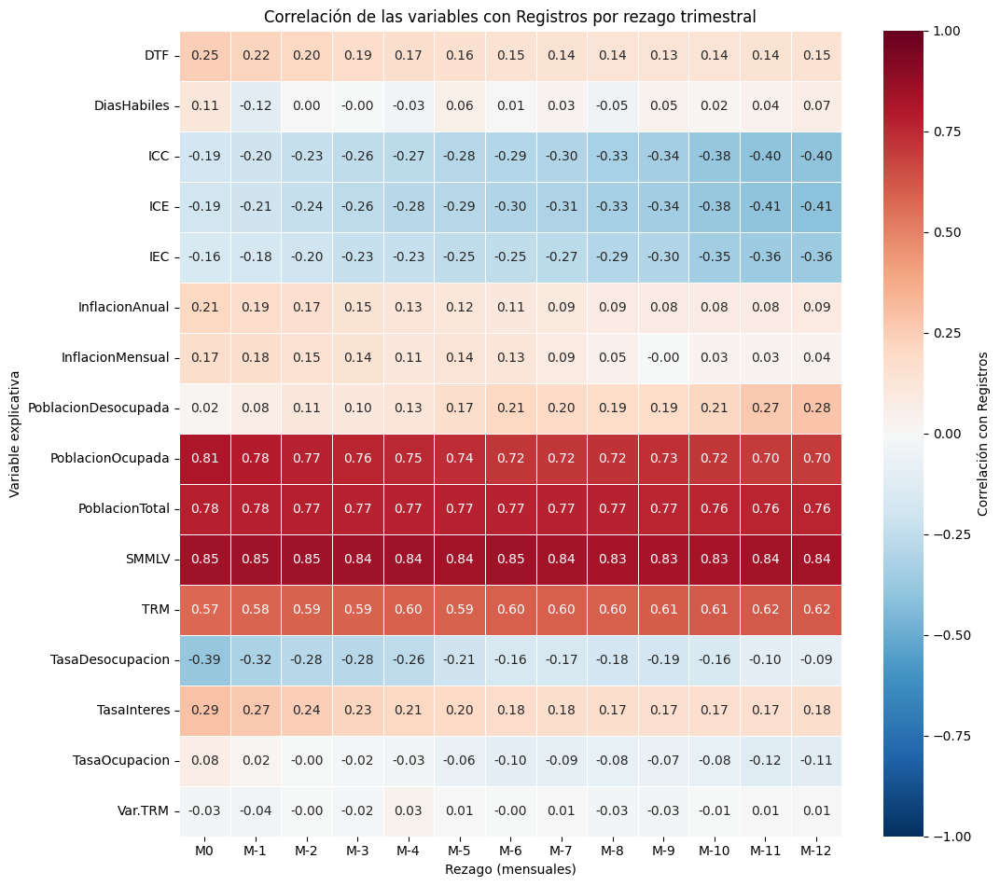

In [36]:
# Organizar los resultados en una matriz
mapa_rezagos = tabla_rezagos.pivot(
    index="Variable",
    columns="Rezago_mensuales",
    values="Correlacion"
)

# Ordenar columnas de 0 a 4 trimestres
mapa_rezagos = mapa_rezagos.reindex(
    columns=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
)

# Graficar
plt.figure(figsize=(11, max(5, len(mapa_rezagos) * 0.6)))

sns.heatmap(
    mapa_rezagos,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlación con Registros"}
)

plt.title("Correlación de las variables con Registros por rezago trimestral")
plt.xlabel("Rezago (mensuales)")
plt.ylabel("Variable explicativa")
plt.xticks(
    ticks=[i + 0.5 for i in range(13)],
    labels=["M0", "M-1", "M-2", "M-3", "M-4", "M-5", "M-6", "M-7", "M-8", "M-9", "M-10", "M-11", "M-12"],
    rotation=0
)

plt.tight_layout()
plt.show()

In [37]:
# Ordenar por fecha
df_datamercado = df_datamarket_trim.sort_values("FechaFin").copy()

# Identificar variables explicativas numéricas
variables_explicativas = [
    c for c in df_datamercado.select_dtypes(include="number").columns
    if c != "Registros"
]

# Evaluar rezagos trimestrales
rezagos = [0, 1, 2, 3, 4]

resultados = []

for variable in variables_explicativas:
    for rezago in rezagos:

        correlacion = df_datamercado["Registros"].corr(
            df_datamercado[variable].shift(rezago)
        )

        resultados.append({
            "Variable": variable,
            "Rezago_trimestrales": rezago,
            "Correlacion": correlacion
        })

tabla_rezagos = pd.DataFrame(resultados)

print(
    tabla_rezagos.sort_values(
        "Correlacion",
        key=lambda x: x.abs(),
        ascending=False
    ).to_string(index=False)
)

           Variable  Rezago_trimestrales  Correlacion
      Importaciones                    0     0.874650
              SMMLV                    0     0.862802
              SMMLV                    2     0.859101
              SMMLV                    1     0.857495
              SMMLV                    4     0.855872
              SMMLV                    3     0.854075
                PIB                    0     0.841536
            Remesas                    0     0.832503
   PoblacionOcupada                    0     0.830264
            Remesas                    1     0.824898
      Importaciones                    1     0.823356
            Remesas                    3     0.813263
            Remesas                    2     0.812139
                PIB                    1     0.805513
            Remesas                    4     0.803619
     PoblacionTotal                    0     0.798461
     PoblacionTotal                    1     0.794924
     PoblacionTotal         

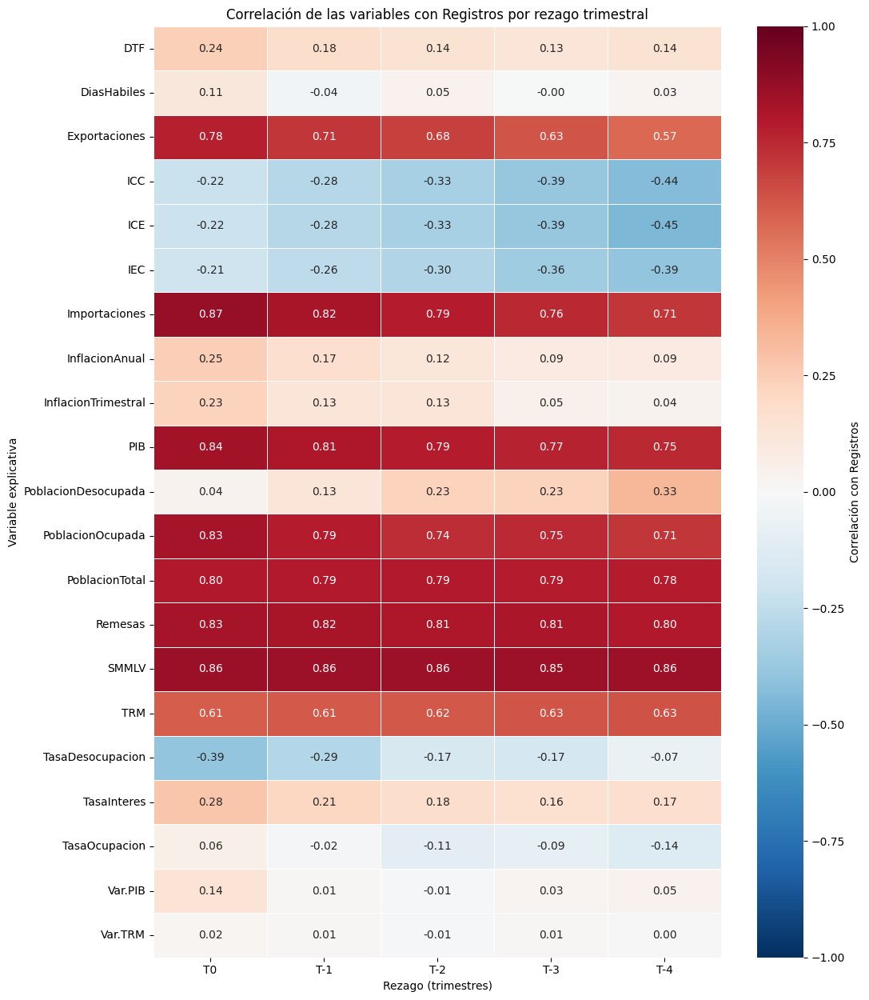

In [38]:
# Organizar los resultados en una matriz
mapa_rezagos = tabla_rezagos.pivot(
    index="Variable",
    columns="Rezago_trimestrales",
    values="Correlacion"
)

# Ordenar columnas de 0 a 4 trimestres
mapa_rezagos = mapa_rezagos.reindex(
    columns=[0, 1, 2, 3, 4]
)

# Graficar
plt.figure(figsize=(11, max(5, len(mapa_rezagos) * 0.6)))

sns.heatmap(
    mapa_rezagos,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlación con Registros"}
)

plt.title("Correlación de las variables con Registros por rezago trimestral")
plt.xlabel("Rezago (trimestres)")
plt.ylabel("Variable explicativa")
plt.xticks(
    ticks=[i + 0.5 for i in range(5)],
    labels=["T0", "T-1", "T-2", "T-3", "T-4"],
    rotation=0
)

plt.tight_layout()
plt.show()

La gráfica presenta el mismo análisis para las variables trimestrales con rezagos de 0 a 4 trimestres. Todas las variables en niveles conservan correlaciones altas, aunque decrecientes con el rezago: las importaciones pasan de 0,87 a 0,71, el PIB de 0,84 a 0,75, el PIB per cápita de 0,82 a 0,68 y las exportaciones de 0,78 a 0,57. Las remesas son la variable más estable, con correlaciones entre 0,83 y 0,80 en todos los rezagos, lo que las convierte en una candidata robusta para un modelo con predictoras rezagadas. La variación del PIB no muestra relación en ningún rezago.

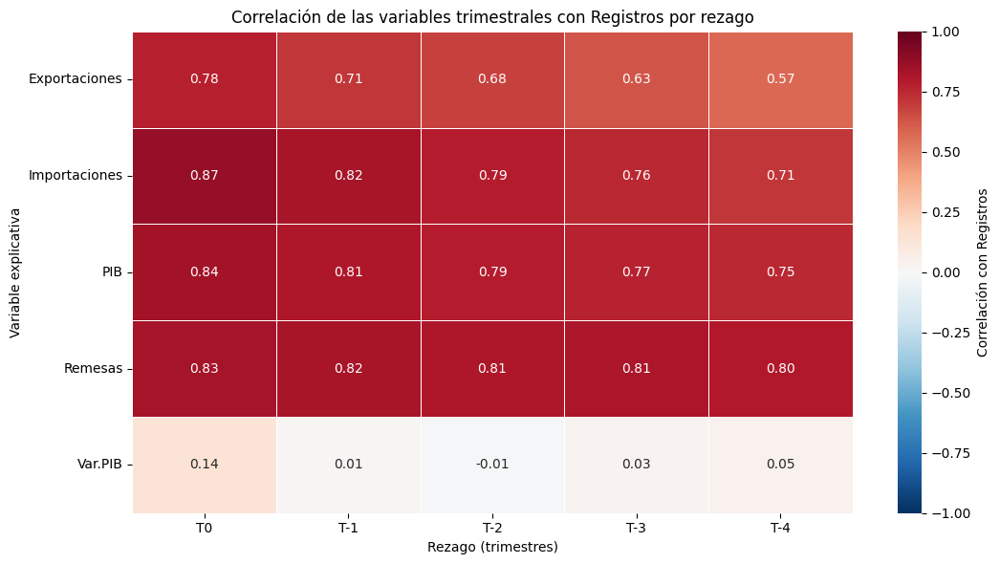

In [39]:
# Ordenar por fecha
df_datamercado = df_datamarket_trim.sort_values("FechaFin").copy()

# Seleccionar únicamente las variables trimestrales explicativas
variables_explicativas = variables_trimestrales

# Evaluar rezagos trimestrales
rezagos = [0, 1, 2, 3, 4]

resultados = []

for variable in variables_explicativas:
    for rezago in rezagos:

        correlacion = df_datamercado["Registros"].corr(
            df_datamercado[variable].shift(rezago)
        )

        resultados.append({
            "Variable": variable,
            "Rezago_trimestrales": rezago,
            "Correlacion": correlacion
        })

tabla_rezagos = pd.DataFrame(resultados)

# Mostrar resultados ordenados por correlación absoluta
#print(
#    tabla_rezagos.sort_values(
#       "Correlacion",
#       key=lambda x: x.abs(),
#        ascending=False
#    ).to_string(index=False)
#)

# Organizar los resultados en una matriz
mapa_rezagos = tabla_rezagos.pivot(
    index="Variable",
    columns="Rezago_trimestrales",
    values="Correlacion"
)

# Ordenar columnas de 0 a 4 trimestres
mapa_rezagos = mapa_rezagos.reindex(
    columns=[0, 1, 2, 3, 4]
)

# Graficar
plt.figure(figsize=(11, 6))

sns.heatmap(
    mapa_rezagos,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlación con Registros"}
)

plt.title("Correlación de las variables trimestrales con Registros por rezago")
plt.xlabel("Rezago (trimestres)")
plt.ylabel("Variable explicativa")

plt.xticks(
    ticks=[i + 0.5 for i in range(5)],
    labels=["T0", "T-1", "T-2", "T-3", "T-4"],
    rotation=0
)

plt.tight_layout()
plt.show()


El análisis exploratorio permite concluir que:

•	La serie de registros es no estacionaria, con tendencia creciente, estacionalidad moderada (picos en julio y diciembre) y choques atípicos en 2009 y 2020 que deberán controlarse con variables indicadoras.

•	Las variables con mayor relación con el mercado son el SMMLV, la población total y ocupada y la TRM en el dataset mensual, y las importaciones, el PIB y las remesas en el dataset trimestral.

•	Existe alta multicolinealidad entre predictoras, que exige seleccionar un representante por grupo; y parte de las correlaciones observadas puede deberse a la tendencia común de las series.


##Preparación de los Datos

Se combinan los dos datasets mensual y trimestral expandiendo las variables trimestrales a nivel de mes, repitiendo su valor.

In [40]:
# Variables trimestrales que se replicarán
variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas"
]

# Crear una copia del dataset trimestral
trim_expandido = df_datamarket_trim[
    ["FechaInicio", "FechaFin"] + variables_trimestrales
].copy()

# Generar los tres meses de cada trimestre
trim_expandido["Fecha"] = trim_expandido.apply(
    lambda fila: pd.date_range(
        start=fila["FechaInicio"],
        end=fila["FechaFin"],
        freq="MS"          # Inicio de cada mes
    ),
    axis=1
)

# Expandir una fila por cada mes
trim_expandido = trim_expandido.explode("Fecha")

# Conservar solo la fecha mensual y las variables trimestrales
trim_expandido = trim_expandido[
    ["Fecha"] + variables_trimestrales
].reset_index(drop=True)

# Unir con el dataset mensual
df_datamarket = df_datamarket_men.merge(
    trim_expandido,
    on="Fecha",
    how="left"
)

In [41]:
df_datamarket.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,...,DiasHabiles,SMMLV,ICC,IEC,ICE,PIB,Var.PIB,Exportaciones,Importaciones,Remesas
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,...,24,426000,0.193,0.266,0.083,126088.657004,NaN,21334.353184,18667.177575,731.13
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,...,24,426000,0.139,0.189,0.065,126088.657004,NaN,21334.353184,18667.177575,731.13
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,...,24,426000,0.096,0.128,0.048,126088.657004,NaN,21334.353184,18667.177575,731.13
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,...,26,426000,0.133,0.169,0.080,128906.474678,0.022348,22346.501950,19696.555294,803.26
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,...,24,426000,0.141,0.147,0.130,128906.474678,0.022348,22346.501950,19696.555294,803.26


Deflactación de las variables para eliminar el efecto de crecimiento natural por demografía

In [42]:
# PIB per cápita (pesos por persona)
df_datamarket["PIB_PC"] = (
    (df_datamarket["PIB"]  /
    df_datamarket["PoblacionTotal"]) * 1000000
)

# Importaciones per cápita (pesos por persona)
df_datamarket["Importaciones_PC"] = (
    (df_datamarket["Importaciones"]  /
    df_datamarket["PoblacionTotal"]) * 1000000
)

# Exportaciones per cápita (pesos por persona)
df_datamarket["Exportaciones_PC"] = (
    (df_datamarket["Exportaciones"]  /
    df_datamarket["PoblacionTotal"]) * 1000000
)


In [43]:
# Registros por cada 100.000 habitantes
df_datamarket["Registros_PC"] = (
    df_datamarket["Registros"] /
    (df_datamarket["PoblacionTotal"] * 1000)
) * 100000

df_datamarket.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,...,ICE,PIB,Var.PIB,Exportaciones,Importaciones,Remesas,PIB_PC,Importaciones_PC,Exportaciones_PC,Registros_PC
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,...,0.083,126088.657004,NaN,21334.353184,18667.177575,731.13,3.127281e+06,462987.806100,529139.733942,28.934292
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,...,0.065,126088.657004,NaN,21334.353184,18667.177575,731.13,3.124247e+06,462538.585810,528626.328833,31.079264
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,...,0.048,126088.657004,NaN,21334.353184,18667.177575,731.13,3.121490e+06,462130.492529,528159.926981,34.138956
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,...,0.080,128906.474678,0.022348,22346.501950,19696.555294,803.26,3.188122e+06,487136.308478,552674.937550,33.558927
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,...,0.130,128906.474678,0.022348,22346.501950,19696.555294,803.26,3.185057e+06,486668.012133,552143.637278,37.657890


Dado que el salario mínimo va creciendo por la inflación, el objetivo es poder mostrarlo en términos que signifiquen poder adquisitivo. Para esto se hará uso del IPC para calcular el salario real con base en el salario nominal.

In [44]:
#Dataset Mensual
df_IPC = pd.read_excel("Data - Mercado.xlsx", sheet_name="IPC")

In [45]:
# Preparar dataset IPC
df_IPC["Fecha"] = pd.to_datetime(df_IPC["Fecha"])
df_datamarket["Fecha"] = pd.to_datetime(df_datamarket["Fecha"])

# Unir IPC al dataset principal
df_datamarket = df_datamarket.merge(
    df_IPC[["Fecha", "IPC"]],
    on="Fecha",
    how="left"
)
df_datamarket.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,...,PIB,Var.PIB,Exportaciones,Importaciones,Remesas,PIB_PC,Importaciones_PC,Exportaciones_PC,Registros_PC,IPC
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,...,126088.657004,NaN,21334.353184,18667.177575,731.13,3.127281e+06,462987.806100,529139.733942,28.934292,56.45
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,...,126088.657004,NaN,21334.353184,18667.177575,731.13,3.124247e+06,462538.585810,528626.328833,31.079264,57.02
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,...,126088.657004,NaN,21334.353184,18667.177575,731.13,3.121490e+06,462130.492529,528159.926981,34.138956,57.46
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,...,128906.474678,0.022348,22346.501950,19696.555294,803.26,3.188122e+06,487136.308478,552674.937550,33.558927,57.72
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,...,128906.474678,0.022348,22346.501950,19696.555294,803.26,3.185057e+06,486668.012133,552143.637278,37.657890,57.95


In [46]:
# Salario mostrando poder adquisitivo
df_datamarket["SMMLV_PA"] = (
    df_datamarket["SMMLV"] /
    (df_datamarket["IPC"])
) * 100


df_datamarket["Remesas_PC"] = (
    (df_datamarket["Remesas"] * df_datamarket["TRM"] * 1000) /
    (df_datamarket["PoblacionTotal"] * (df_datamarket["IPC"] / 100))
)


df_datamarket.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,...,Exportaciones,Importaciones,Remesas,PIB_PC,Importaciones_PC,Exportaciones_PC,Registros_PC,IPC,SMMLV_PA,Remesas_PC
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,...,21334.353184,18667.177575,731.13,3.127281e+06,462987.806100,529139.733942,28.934292,56.45,754650.132861,75906.317435
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,...,21334.353184,18667.177575,731.13,3.124247e+06,462538.585810,528626.328833,31.079264,57.02,747106.278499,74360.703658
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,...,21334.353184,18667.177575,731.13,3.121490e+06,462130.492529,528159.926981,34.138956,57.46,741385.311521,74142.615388
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,...,22346.501950,19696.555294,803.26,3.188122e+06,487136.308478,552674.937550,33.558927,57.72,738045.738046,80883.465381
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,...,22346.501950,19696.555294,803.26,3.185057e+06,486668.012133,552143.637278,37.657890,57.95,735116.479724,80115.452729


In [47]:
# Guarda este respaldo ANTES de eliminar Registros y PoblacionTotal de df_datamarket
aux_real = df_datamarket[["Fecha", "PoblacionTotal", "Registros"]].copy()

In [48]:
# Columnas a eliminar
columnas_eliminar = [
    "Registros",
    "PIB",
    "Exportaciones",
    "Importaciones",
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "DTF",
    "SMMLV",
    "IEC",
    "ICE",
    "IPC",
    "Remesas"
]

# Eliminar columnas
df_datamarket = df_datamarket.drop(columns=columnas_eliminar)

# Verificar resultado
display(df_datamarket.head())

,Fecha,TasaDesocupacion,TRM,Var.TRM,TasaInteres,InflacionAnual,InflacionMensual,DiasHabiles,ICC,Var.PIB,PIB_PC,Importaciones_PC,Exportaciones_PC,Registros_PC,SMMLV_PA,Remesas_PC
0,2005-01-01,0.132626,2362.96,NaN,0.065,0.0543,0.0082,24,0.193,NaN,3.127281e+06,462987.806100,529139.733942,28.934292,754650.132861,75906.317435
1,2005-02-01,0.140969,2340.49,-0.009509,0.065,0.0525,0.0102,24,0.139,NaN,3.124247e+06,462538.585810,528626.328833,31.079264,747106.278499,74360.703658
2,2005-03-01,0.129543,2353.71,0.005648,0.065,0.0503,0.0077,24,0.096,NaN,3.121490e+06,462130.492529,528159.926981,34.138956,741385.311521,74142.615388
3,2005-04-01,0.120205,2350.01,-0.001572,0.065,0.0501,0.0044,26,0.133,0.022348,3.188122e+06,487136.308478,552674.937550,33.558927,738045.738046,80883.465381
4,2005-05-01,0.124907,2339.22,-0.004591,0.065,0.0504,0.0041,24,0.141,0.022348,3.185057e+06,486668.012133,552143.637278,37.657890,735116.479724,80115.452729


Se crean dos variables para señalar los periodos que presentan atipicos.

In [49]:
#Dataset Mensual
df_atipicos = pd.read_excel("Data - Mercado.xlsx", sheet_name="Atipicos")

In [50]:
# Preparar dataset IPC
df_atipicos["Fecha"] = pd.to_datetime(df_atipicos["Fecha"])
df_datamarket["Fecha"] = pd.to_datetime(df_datamarket["Fecha"])

# Unir IPC al dataset principal
df_datamarket = df_datamarket.merge(
    df_atipicos[["Fecha", "COVID", "DificultadesRUNT"]],
    on="Fecha",
    how="left"
)
df_datamarket.head()

,Fecha,TasaDesocupacion,TRM,Var.TRM,TasaInteres,InflacionAnual,InflacionMensual,DiasHabiles,ICC,Var.PIB,PIB_PC,Importaciones_PC,Exportaciones_PC,Registros_PC,SMMLV_PA,Remesas_PC,COVID,DificultadesRUNT
0,2005-01-01,0.132626,2362.96,NaN,0.065,0.0543,0.0082,24,0.193,NaN,3.127281e+06,462987.806100,529139.733942,28.934292,754650.132861,75906.317435,0,0
1,2005-02-01,0.140969,2340.49,-0.009509,0.065,0.0525,0.0102,24,0.139,NaN,3.124247e+06,462538.585810,528626.328833,31.079264,747106.278499,74360.703658,0,0
2,2005-03-01,0.129543,2353.71,0.005648,0.065,0.0503,0.0077,24,0.096,NaN,3.121490e+06,462130.492529,528159.926981,34.138956,741385.311521,74142.615388,0,0
3,2005-04-01,0.120205,2350.01,-0.001572,0.065,0.0501,0.0044,26,0.133,0.022348,3.188122e+06,487136.308478,552674.937550,33.558927,738045.738046,80883.465381,0,0
4,2005-05-01,0.124907,2339.22,-0.004591,0.065,0.0504,0.0041,24,0.141,0.022348,3.185057e+06,486668.012133,552143.637278,37.657890,735116.479724,80115.452729,0,0


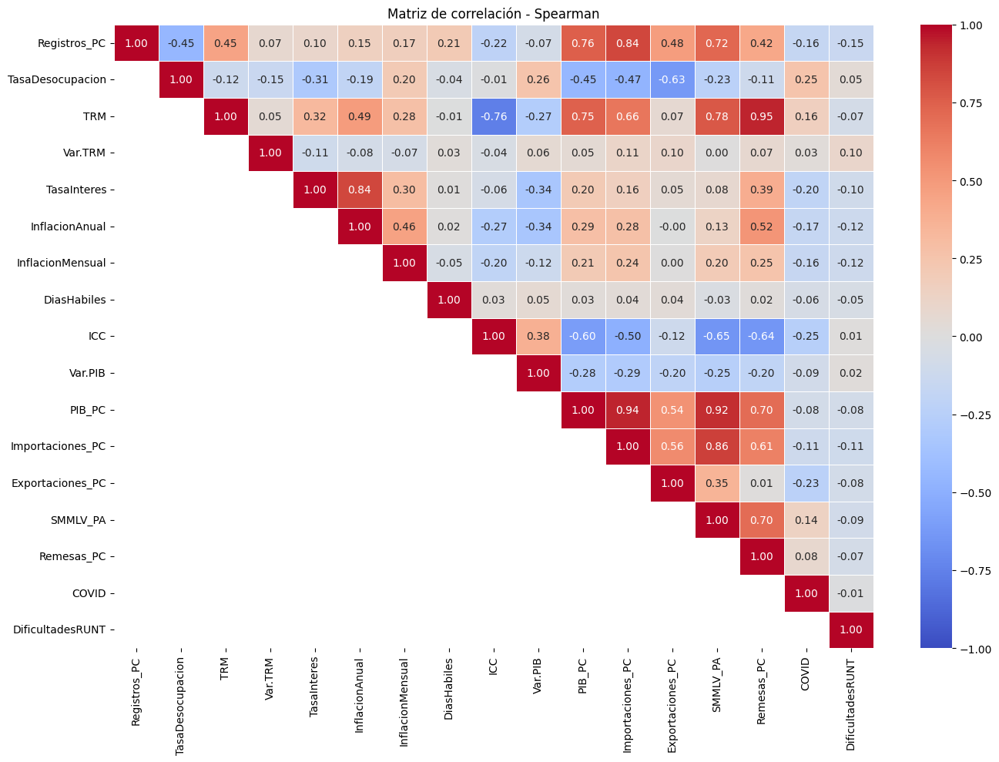

In [51]:
# Seleccionar variables numéricas
variables = df_datamarket.select_dtypes(include="number")

# Calcular matriz de correlación de Pearson
matriz_corr = variables.corr(method="spearman")

# Colocar Registros_PC de primero, conservando el orden de las demás
orden = ["Registros_PC"] + [
    col for col in matriz_corr.columns
    if col != "Registros_PC"
]

matriz_corr = matriz_corr.loc[orden, orden]

# Crear máscara para ocultar el triángulo inferior
mascara = np.tril(
    np.ones_like(matriz_corr, dtype=bool),
    k=-1
)

# Visualizar la matriz
plt.figure(figsize=(14, 10))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación - Spearman")
plt.tight_layout()
plt.show()

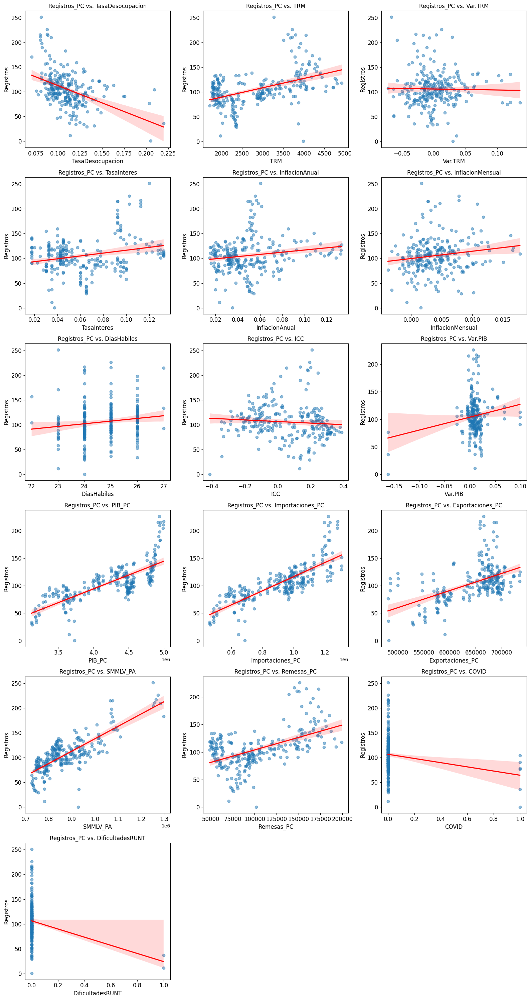

In [98]:
# Identificar variables numéricas, excluyendo fecha y variable objetivo
variables_graficos = [
    col for col in df_datamarket.select_dtypes(include="number").columns
    if col != "Registros_PC"
]

# Definir número de columnas y filas
ncols = 3
nrows = math.ceil(len(variables_graficos) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(16, 5 * nrows)
)

axes = np.array(axes).flatten()

# Generar gráficos de dispersión con línea de regresión
for i, col in enumerate(variables_graficos):

    temporal = df_datamarket[
        ["Registros_PC", col]
    ].dropna()

    sns.regplot(
        data=temporal,
        x=col,
        y="Registros_PC",
        scatter_kws={"alpha": 0.5},
        line_kws={"color": "red"},
        ax=axes[i]
    )

    axes[i].set_title(f"Registros_PC vs. {col}", fontsize=12)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Registros por cada 100.000 habitantes")

    # Tamaño de los nombres de los ejes
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel("Registros", fontsize=12)

    # Tamaño de los valores de los ejes
    axes[i].tick_params(axis="both", labelsize=12)

# Eliminar espacios sobrantes
for j in range(len(variables_graficos), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

##Modelación

### 1 MES - SIN DIFERENCIAR

Dataset listo para modelado: 246 meses (2006-01 a 2026-06)


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



=== TABLA COMPARATIVA DE MODELOS (4 VENTANAS DE 12 MESES | R2 GLOBAL OOS) ===
                          MAPE (%)        MAE       RMSE           MSE  \
SARIMAX                      9.704   7286.597   8193.207  7.634426e+07   
Prophet                     10.722   7622.640   8811.517  8.301235e+07   
Regresión Lineal (Ridge)    15.164  10838.372  12200.395  1.634567e+08   
SARIMA (Baseline)           16.779  12639.563  14042.562  2.140648e+08   
Random Forest               17.416  13228.390  14765.083  2.394192e+08   
XGBoost                     18.054  14190.533  15404.339  2.727656e+08   

                          R2_Global_OOS  
SARIMAX                           0.806  
Prophet                           0.789  
Regresión Lineal (Ridge)          0.585  
SARIMA (Baseline)                 0.457  
Random Forest                     0.393  
XGBoost                           0.308  


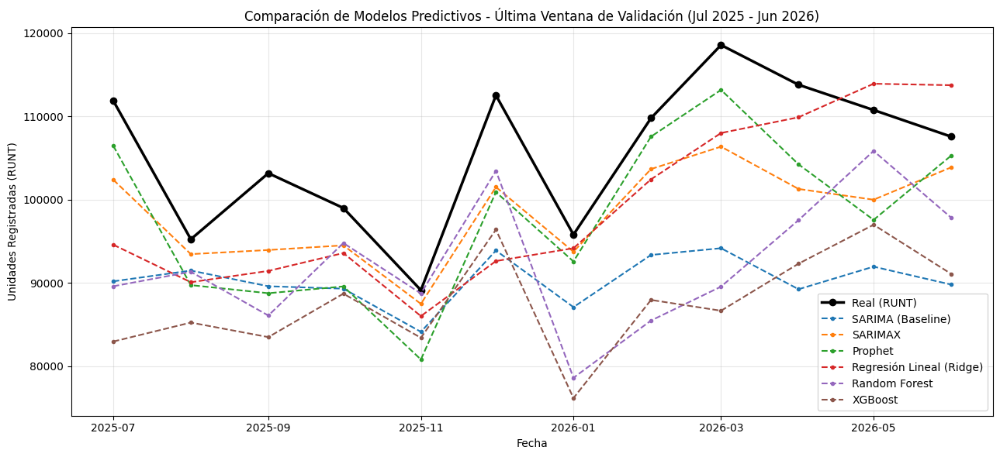

In [53]:
# ==============================================================================
# 1. PREPARACIÓN Y CONSTRUCCIÓN DE REZAGOS SOBRE df_datamarket
# ==============================================================================
# Asegúrate de tener definida la tabla auxiliar 'aux_real' con ["Fecha", "PoblacionTotal", "Registros"]
# recortada hasta junio de 2026 (258 meses).

df_work = (
    df_datamarket
    .merge(aux_real, on="Fecha", how="inner")
    .sort_values("Fecha")
    .reset_index(drop=True)
)

# Imputar el primer valor nulo (enero 2005) en variaciones
df_work["Var.TRM"] = df_work["Var.TRM"].fillna(0)
df_work["Var.PIB"] = df_work["Var.PIB"].fillna(0)

# Variables de calendario y tendencia determinística
df_work["Mes"] = df_work["Fecha"].dt.month
df_work["Mes_sin"] = np.sin(2 * np.pi * df_work["Mes"] / 12)
df_work["Mes_cos"] = np.cos(2 * np.pi * df_work["Mes"] / 12)
df_work["Tendencia"] = np.arange(len(df_work))

# Rezagos autorregresivos de Registros_PC
for lag in [1, 2, 3, 6, 12]:
    df_work[f"Registros_PC_lag{lag}"] = df_work["Registros_PC"].shift(lag)

# Rezagos de variables macroeconómicas (1, 3, 6 y 12 meses)
macro_cols = [
    "TasaDesocupacion", "TRM", "Var.TRM", "TasaInteres",
    "InflacionAnual", "InflacionMensual", "ICC",
    "PIB_PC", "Var.PIB", "Exportaciones_PC", "Importaciones_PC",
    "Remesas_PC", "SMMLV_PA"
]

for col in macro_cols:
    for lag in [1, 3, 6, 12]:
        df_work[f"{col}_lag{lag}"] = df_work[col].shift(lag)

# Objetivo estacionario (variación interanual) para modelos basados en árboles
df_work["Delta12_Registros_PC"] = df_work["Registros_PC"] - df_work["Registros_PC_lag12"]

# Eliminar los primeros 12 meses con NaN por los rezagos (2006-01 a 2026-06: 246 meses)
df_model = df_work.dropna().reset_index(drop=True)
print(f"Dataset listo para modelado: {df_model.shape[0]} meses ({df_model['Fecha'].min().strftime('%Y-%m')} a {df_model['Fecha'].max().strftime('%Y-%m')})")

# ==============================================================================
# 2. DEFINICIÓN DE CONJUNTOS DE VARIABLES POR FAMILIA DE MODELOS
# ==============================================================================
# A. Subconjunto parsimonioso para modelos estadísticos (SARIMAX y Prophet)
exog_estadisticos = [
    "DiasHabiles", "COVID", "DificultadesRUNT",
    "TasaInteres_lag3", "Var.TRM_lag3", "ICC_lag1",
    "SMMLV_PA_lag1", "Var.PIB_lag3", "TasaDesocupacion_lag3"
]

# B. Variables base comunes para Machine Learning
vars_comunes_ml = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "TasaInteres_lag1", "TasaInteres_lag3", "TasaInteres_lag6", "TasaInteres_lag12",
    "TasaDesocupacion_lag1", "TasaDesocupacion_lag3", "TasaDesocupacion_lag12",
    "ICC_lag1", "ICC_lag3", "ICC_lag12",
    "SMMLV_PA_lag1", "SMMLV_PA_lag3", "SMMLV_PA_lag12",
    "InflacionAnual_lag1", "InflacionAnual_lag3", "InflacionAnual_lag12",
    "Registros_PC_lag1", "Registros_PC_lag2", "Registros_PC_lag3", "Registros_PC_lag12"
]

# C. Subconjunto estacionario para Random Forest y XGBoost
features_arboles = vars_comunes_ml + [
    "Var.TRM_lag1", "Var.TRM_lag3", "Var.TRM_lag6", "Var.TRM_lag12",
    "Var.PIB_lag3", "Var.PIB_lag6", "Var.PIB_lag12",
    "Remesas_PC_lag3", "Remesas_PC_lag12", "Tendencia"
]

# D. Subconjunto completo (niveles + variaciones) para Regresión Lineal Regularizada (Ridge)
features_lineal = features_arboles + [
    "TRM_lag1", "TRM_lag3", "TRM_lag6",
    "PIB_PC_lag3", "PIB_PC_lag6",
    "Exportaciones_PC_lag3", "Importaciones_PC_lag3", "InflacionMensual_lag1"
]

# ==============================================================================
# 3. FUNCIONES AUXILIARES DE EVALUACIÓN Y PREDICCIÓN RECURSIVA
# ==============================================================================
def calcular_metricas_fold(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    return {"MAPE (%)": mape, "MAE": mae, "RMSE": rmse, "MSE": mse}

def predecir_recursivo_ml(modelo, train_df, test_df, cols_modelo, es_delta12=False):
    """
    Simula un horizonte real de 12 meses actualizando dinámicamente los rezagos
    de Registros_PC con las predicciones previas (sin fuga de información).
    """
    historia_pc = list(train_df["Registros_PC"].values)
    preds_pc = []

    for i in range(len(test_df)):
        fila = test_df.iloc[[i]][cols_modelo].copy()
        for lag in [1, 2, 3, 6, 12]:
            col_lag = f"Registros_PC_lag{lag}"
            if col_lag in fila.columns:
                fila[col_lag] = historia_pc[-lag]

        pred_raw = modelo.predict(fila)[0]
        pred_pc = (historia_pc[-12] + pred_raw) if es_delta12 else pred_raw

        preds_pc.append(pred_pc)
        historia_pc.append(pred_pc)

    return np.array(preds_pc)

# ==============================================================================
# 4. VALIDACIÓN CRUZADA CRONOLÓGICA (TIME SERIES SPLIT - 4 CORTES DE 12 MESES)
# ==============================================================================
tscv = TimeSeriesSplit(n_splits=4, test_size=12)

nombres_modelos = [
    "SARIMA (Baseline)",
    "SARIMAX",
    "Prophet",
    "Regresión Lineal (Ridge)",
    "Random Forest",
    "XGBoost"
]

resultados_folds = {m: [] for m in nombres_modelos}
y_true_global = []
preds_globales = {m: [] for m in nombres_modelos}
predicciones_ultimo_fold = {}

for fold, (train_idx, test_idx) in enumerate(tscv.split(df_model)):
    tr = df_model.iloc[train_idx].copy()
    te = df_model.iloc[test_idx].copy()

    # Factor para reconvertir Registros_PC (motos/100k hab) a unidades reales RUNT
    factor_real = (te["PoblacionTotal"].values * 1000) / 100000
    y_true_abs = te["Registros"].values
    y_true_global.extend(y_true_abs)

    # --------------------------------------------------------------------------
    # 1. SARIMA (Modelo Base Univariado con deriva trend="c")
    # --------------------------------------------------------------------------
    m_sarima = SARIMAX(
        tr["Registros_PC"],
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        trend="c"
    ).fit(disp=False)
    pred_sarima = m_sarima.forecast(steps=12).values * factor_real
    resultados_folds["SARIMA (Baseline)"].append(calcular_metricas_fold(y_true_abs, pred_sarima))
    preds_globales["SARIMA (Baseline)"].extend(pred_sarima)

    # --------------------------------------------------------------------------
    # 2. SARIMAX (Con variables macroeconómicas rezagadas y deriva trend="c")
    # --------------------------------------------------------------------------
    m_sarimax = SARIMAX(
        tr["Registros_PC"],
        exog=tr[exog_estadisticos],
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        trend="c"
    ).fit(disp=False)
    pred_sarimax = m_sarimax.forecast(steps=12, exog=te[exog_estadisticos]).values * factor_real
    resultados_folds["SARIMAX"].append(calcular_metricas_fold(y_true_abs, pred_sarimax))
    preds_globales["SARIMAX"].extend(pred_sarimax)

    # --------------------------------------------------------------------------
    # 3. PROPHET (Con regresores macroeconómicos y mayor flexibilidad de tendencia)
    # --------------------------------------------------------------------------
    df_prophet_tr = tr[["Fecha", "Registros_PC"] + exog_estadisticos].rename(
        columns={"Fecha": "ds", "Registros_PC": "y"}
    )
    df_prophet_te = te[["Fecha"] + exog_estadisticos].rename(columns={"Fecha": "ds"})

    m_prophet = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        seasonality_mode="multiplicative",
        changepoint_prior_scale=0.15
    )
    for col in exog_estadisticos:
        m_prophet.add_regressor(col)

    m_prophet.fit(df_prophet_tr)
    pred_prophet = m_prophet.predict(df_prophet_te)["yhat"].values * factor_real
    resultados_folds["Prophet"].append(calcular_metricas_fold(y_true_abs, pred_prophet))
    preds_globales["Prophet"].extend(pred_prophet)

    # --------------------------------------------------------------------------
    # 4. REGRESIÓN LINEAL REGULARIZADA (Ridge)
    # --------------------------------------------------------------------------
    m_ridge = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=15.0))
    ])
    m_ridge.fit(tr[features_lineal], tr["Registros_PC"])
    pred_ridge = predecir_recursivo_ml(m_ridge, tr, te, features_lineal, es_delta12=False) * factor_real
    resultados_folds["Regresión Lineal (Ridge)"].append(calcular_metricas_fold(y_true_abs, pred_ridge))
    preds_globales["Regresión Lineal (Ridge)"].extend(pred_ridge)

    # --------------------------------------------------------------------------
    # 5. RANDOM FOREST (Entrenado sobre variación anual estacionaria Delta12)
    # --------------------------------------------------------------------------
    m_rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
    )
    m_rf.fit(tr[features_arboles], tr["Delta12_Registros_PC"])
    pred_rf = predecir_recursivo_ml(m_rf, tr, te, features_arboles, es_delta12=True) * factor_real
    resultados_folds["Random Forest"].append(calcular_metricas_fold(y_true_abs, pred_rf))
    preds_globales["Random Forest"].extend(pred_rf)

    # --------------------------------------------------------------------------
    # 6. XGBOOST (Entrenado sobre variación anual estacionaria Delta12)
    # --------------------------------------------------------------------------
    m_xgb = XGBRegressor(
        n_estimators=70,
        learning_rate=0.1,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda =5.0,
        random_state=42
    )
    m_xgb.fit(tr[features_arboles], tr["Delta12_Registros_PC"])
    pred_xgb = predecir_recursivo_ml(m_xgb, tr, te, features_arboles, es_delta12=True) * factor_real
    resultados_folds["XGBoost"].append(calcular_metricas_fold(y_true_abs, pred_xgb))
    preds_globales["XGBoost"].extend(pred_xgb)

    # Guardar predicciones del último fold (Jul 2025 - Jun 2026) para visualización
    if fold == 3:
        predicciones_ultimo_fold = {
            "Fecha": te["Fecha"].values,
            "Real": y_true_abs,
            "SARIMA (Baseline)": pred_sarima,
            "SARIMAX": pred_sarimax,
            "Prophet": pred_prophet,
            "Regresión Lineal (Ridge)": pred_ridge,
            "Random Forest": pred_rf,
            "XGBoost": pred_xgb
        }

# ==============================================================================
# 5. TABLA COMPARATIVA CON R2 GLOBAL FUERA DE MUESTRA Y GRÁFICO
# ==============================================================================
tabla_resultados = pd.DataFrame({
    modelo: pd.DataFrame(metricas).mean()
    for modelo, metricas in resultados_folds.items()
}).T

for modelo in nombres_modelos:
    tabla_resultados.loc[modelo, "R2_Global_OOS"] = r2_score(y_true_global, preds_globales[modelo])

tabla_resultados = tabla_resultados.sort_values("MAPE (%)")

print("\n=== TABLA COMPARATIVA DE MODELOS (4 VENTANAS DE 12 MESES | R2 GLOBAL OOS) ===")
print(tabla_resultados.round(3))

# Visualización del último corte de validación (Julio 2025 - Junio 2026)
df_plot = pd.DataFrame(predicciones_ultimo_fold)
plt.figure(figsize=(13, 6))
plt.plot(df_plot["Fecha"], df_plot["Real"], label="Real (RUNT)", color="black", linewidth=2.5, marker="o")

for col in nombres_modelos:
    plt.plot(df_plot["Fecha"], df_plot[col], label=col, linestyle="--", marker=".")

plt.title("Comparación de Modelos Predictivos - Última Ventana de Validación (Jul 2025 - Jun 2026)")
plt.xlabel("Fecha")
plt.ylabel("Unidades Registradas (RUNT)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 1 MES - MACHINE LEARNING DIFERENCIADO

Dataset listo para modelado: 234 meses (2007-01 a 2026-06)


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



=== TABLA COMPARATIVA DE MODELOS (4 VENTANAS DE 12 MESES | ML DIFERENCIADO) ===
                                 MAPE (%)        MAE       RMSE           MSE  \
Prophet                             9.980   7131.169   8317.819  7.507423e+07   
SARIMAX                            12.210   8810.512   9591.595  1.034258e+08   
Regresión Lineal (Ridge Diff12)    12.222   8991.332  10425.975  1.159681e+08   
XGBoost (Diff12)                   13.614  10508.955  12080.942  1.610301e+08   
Random Forest (Diff12)             15.831  11941.662  13371.255  1.849020e+08   
SARIMA (Baseline)                  16.794  12499.998  13871.755  2.092336e+08   

                                 R2_Global_OOS  
Prophet                                  0.810  
SARIMAX                                  0.738  
Regresión Lineal (Ridge Diff12)          0.706  
XGBoost (Diff12)                         0.592  
Random Forest (Diff12)                   0.531  
SARIMA (Baseline)                        0.469  


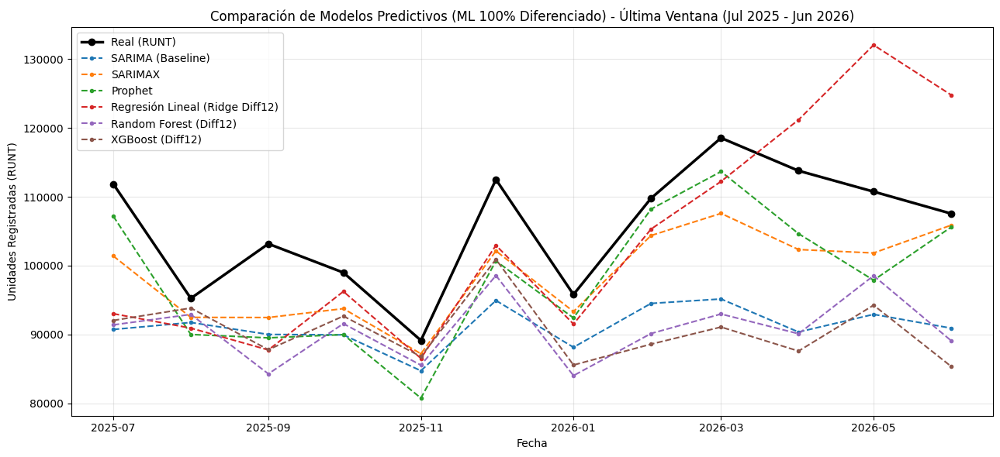

In [54]:
# ==============================================================================
# 1. PREPARACIÓN Y DIFERENCIACIÓN INTERANUAL (DELTA 12) SOBRE df_datamarket
# ==============================================================================
df_work = (
    df_datamarket
    .merge(aux_real, on="Fecha", how="inner")
    .sort_values("Fecha")
    .reset_index(drop=True)
)

# Imputar el primer valor nulo (enero 2005) en variaciones
df_work["Var.TRM"] = df_work["Var.TRM"].fillna(0)
df_work["Var.PIB"] = df_work["Var.PIB"].fillna(0)

# Variables de calendario cíclico
df_work["Mes"] = df_work["Fecha"].dt.month
df_work["Mes_sin"] = np.sin(2 * np.pi * df_work["Mes"] / 12)
df_work["Mes_cos"] = np.cos(2 * np.pi * df_work["Mes"] / 12)

# Rezagos en nivel (para reconstrucción y modelos estadísticos)
for lag in [1, 2, 3, 6, 12]:
    df_work[f"Registros_PC_lag{lag}"] = df_work["Registros_PC"].shift(lag)

# Objetivo estacionario: Diferenciación interanual (y_t - y_{t-12})
df_work["Delta12_Registros_PC"] = df_work["Registros_PC"] - df_work["Registros_PC_lag12"]

# Rezagos de la serie diferenciada para ML
for lag in [1, 2, 3, 6, 12]:
    df_work[f"Delta12_Reg_lag{lag}"] = df_work["Delta12_Registros_PC"].shift(lag)

# Rezagos en nivel y diferenciados (Delta12) de variables macroeconómicas
col_remesas = "Remesas_PC" if "Remesas_PC" in df_work.columns else "Remesas"
macro_cols = [
    "TasaDesocupacion", "TRM", "Var.TRM", "TasaInteres",
    "InflacionAnual", "InflacionMensual", "ICC",
    "PIB_PC", "Var.PIB", "Exportaciones_PC", "Importaciones_PC",
    col_remesas, "SMMLV_PA"
]

for col in macro_cols:
    df_work[f"Diff12_{col}"] = df_work[col] - df_work[col].shift(12)
    for lag in [1, 3, 6, 12]:
        df_work[f"{col}_lag{lag}"] = df_work[col].shift(lag)
        df_work[f"Diff12_{col}_lag{lag}"] = df_work[f"Diff12_{col}"].shift(lag)

# Eliminar los primeros 24 meses con NaN por la doble estructura de rezagos (2007-01 a 2026-06: 234 meses)
df_model = df_work.dropna().reset_index(drop=True)
print(f"Dataset listo para modelado: {df_model.shape[0]} meses ({df_model['Fecha'].min().strftime('%Y-%m')} a {df_model['Fecha'].max().strftime('%Y-%m')})")

# ==============================================================================
# 2. DEFINICIÓN DE CONJUNTOS DE VARIABLES POR FAMILIA DE MODELOS
# ==============================================================================
# A. Subconjunto parsimonioso para modelos estadísticos (SARIMAX y Prophet)
exog_estadisticos = [
    "DiasHabiles", "COVID", "DificultadesRUNT",
    "TasaInteres_lag3", "Var.TRM_lag3", "ICC_lag1",
    "SMMLV_PA_lag1", "Var.PIB_lag3", "TasaDesocupacion_lag3"
]

# B. Conjunto 100% diferenciado (estacionario) para Machine Learning (Ridge, RF y XGBoost)
features_ml_diff12 = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "Delta12_Reg_lag1", "Delta12_Reg_lag2", "Delta12_Reg_lag3", "Delta12_Reg_lag12",
    "Diff12_TasaInteres_lag1", "Diff12_TasaInteres_lag3", "Diff12_TasaInteres_lag6",
    "Diff12_TasaDesocupacion_lag1", "Diff12_TasaDesocupacion_lag3",
    "Diff12_ICC_lag1", "Diff12_ICC_lag3",
    "Diff12_SMMLV_PA_lag1", "Diff12_SMMLV_PA_lag3",
    "Diff12_InflacionAnual_lag1", "Diff12_InflacionAnual_lag3",
    "Diff12_PIB_PC_lag3", "Diff12_TRM_lag3", f"Diff12_{col_remesas}_lag3"
]

# ==============================================================================
# 3. FUNCIONES AUXILIARES DE EVALUACIÓN Y PREDICCIÓN RECURSIVA DIFERENCIADA
# ==============================================================================
def calcular_metricas_fold(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    return {"MAPE (%)": mape, "MAE": mae, "RMSE": rmse, "MSE": mse}

def predecir_recursivo_diff12(modelo, train_df, test_df, cols_modelo):
    """
    Predice recursivamente el crecimiento interanual (Delta12_Registros_PC)
    actualizando los rezagos diferenciados y reconstruyendo el nivel (y_{t-12} + Delta12).
    """
    historia_pc = list(train_df["Registros_PC"].values)
    historia_d12 = list(train_df["Delta12_Registros_PC"].values)
    preds_pc = []

    for i in range(len(test_df)):
        fila = test_df.iloc[[i]][cols_modelo].copy()
        for lag in [1, 2, 3, 12]:
            col_lag = f"Delta12_Reg_lag{lag}"
            if col_lag in fila.columns:
                fila[col_lag] = historia_d12[-lag]

        pred_d12 = modelo.predict(fila)[0]
        pred_pc = historia_pc[-12] + pred_d12

        preds_pc.append(pred_pc)
        historia_pc.append(pred_pc)
        historia_d12.append(pred_d12)

    return np.array(preds_pc)

# ==============================================================================
# 4. VALIDACIÓN CRUZADA CRONOLÓGICA (TIME SERIES SPLIT - 4 CORTES DE 12 MESES)
# ==============================================================================
tscv = TimeSeriesSplit(n_splits=4, test_size=12)

nombres_modelos = [
    "SARIMA (Baseline)",
    "SARIMAX",
    "Prophet",
    "Regresión Lineal (Ridge Diff12)",
    "Random Forest (Diff12)",
    "XGBoost (Diff12)"
]

resultados_folds = {m: [] for m in nombres_modelos}
y_true_global = []
preds_globales = {m: [] for m in nombres_modelos}
predicciones_ultimo_fold = {}

for fold, (train_idx, test_idx) in enumerate(tscv.split(df_model)):
    tr = df_model.iloc[train_idx].copy()
    te = df_model.iloc[test_idx].copy()

    factor_real = (te["PoblacionTotal"].values * 1000) / 100000
    y_true_abs = te["Registros"].values
    y_true_global.extend(y_true_abs)

    # 1. SARIMA (Baseline)
    m_sarima = SARIMAX(
        tr["Registros_PC"],
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        trend="c"
    ).fit(disp=False)
    pred_sarima = m_sarima.forecast(steps=12).values * factor_real
    resultados_folds["SARIMA (Baseline)"].append(calcular_metricas_fold(y_true_abs, pred_sarima))
    preds_globales["SARIMA (Baseline)"].extend(pred_sarima)

    # 2. SARIMAX
    m_sarimax = SARIMAX(
        tr["Registros_PC"],
        exog=tr[exog_estadisticos],
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        trend="c"
    ).fit(disp=False)
    pred_sarimax = m_sarimax.forecast(steps=12, exog=te[exog_estadisticos]).values * factor_real
    resultados_folds["SARIMAX"].append(calcular_metricas_fold(y_true_abs, pred_sarimax))
    preds_globales["SARIMAX"].extend(pred_sarimax)

    # 3. PROPHET
    df_prophet_tr = tr[["Fecha", "Registros_PC"] + exog_estadisticos].rename(
        columns={"Fecha": "ds", "Registros_PC": "y"}
    )
    df_prophet_te = te[["Fecha"] + exog_estadisticos].rename(columns={"Fecha": "ds"})

    m_prophet = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        seasonality_mode="multiplicative",
        changepoint_prior_scale=0.15
    )
    for col in exog_estadisticos:
        m_prophet.add_regressor(col)

    m_prophet.fit(df_prophet_tr)
    pred_prophet = m_prophet.predict(df_prophet_te)["yhat"].values * factor_real
    resultados_folds["Prophet"].append(calcular_metricas_fold(y_true_abs, pred_prophet))
    preds_globales["Prophet"].extend(pred_prophet)

    # 4. REGRESIÓN LINEAL REGULARIZADA (Ridge 100% Diferenciado)
    m_ridge = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=15.0))
    ])
    m_ridge.fit(tr[features_ml_diff12], tr["Delta12_Registros_PC"])
    pred_ridge = predecir_recursivo_diff12(m_ridge, tr, te, features_ml_diff12) * factor_real
    resultados_folds["Regresión Lineal (Ridge Diff12)"].append(calcular_metricas_fold(y_true_abs, pred_ridge))
    preds_globales["Regresión Lineal (Ridge Diff12)"].extend(pred_ridge)

    # 5. RANDOM FOREST (100% Diferenciado)
    m_rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
    )
    m_rf.fit(tr[features_ml_diff12], tr["Delta12_Registros_PC"])
    pred_rf = predecir_recursivo_diff12(m_rf, tr, te, features_ml_diff12) * factor_real
    resultados_folds["Random Forest (Diff12)"].append(calcular_metricas_fold(y_true_abs, pred_rf))
    preds_globales["Random Forest (Diff12)"].extend(pred_rf)

    # 6. XGBOOST (100% Diferenciado)
    m_xgb = XGBRegressor(
        n_estimators=70,
        learning_rate=0.1,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda =5.0,
        random_state=42
    )
    m_xgb.fit(tr[features_ml_diff12], tr["Delta12_Registros_PC"])
    pred_xgb = predecir_recursivo_diff12(m_xgb, tr, te, features_ml_diff12) * factor_real
    resultados_folds["XGBoost (Diff12)"].append(calcular_metricas_fold(y_true_abs, pred_xgb))
    preds_globales["XGBoost (Diff12)"].extend(pred_xgb)

    if fold == 3:
        predicciones_ultimo_fold = {
            "Fecha": te["Fecha"].values,
            "Real": y_true_abs,
            "SARIMA (Baseline)": pred_sarima,
            "SARIMAX": pred_sarimax,
            "Prophet": pred_prophet,
            "Regresión Lineal (Ridge Diff12)": pred_ridge,
            "Random Forest (Diff12)": pred_rf,
            "XGBoost (Diff12)": pred_xgb
        }

# ==============================================================================
# 5. TABLA COMPARATIVA CON R2 GLOBAL FUERA DE MUESTRA Y GRÁFICO
# ==============================================================================
tabla_1m_diff = pd.DataFrame({
    modelo: pd.DataFrame(metricas).mean()
    for modelo, metricas in resultados_folds.items()
}).T

for modelo in nombres_modelos:
    tabla_1m_diff.loc[modelo, "R2_Global_OOS"] = r2_score(y_true_global, preds_globales[modelo])

tabla_1m_diff = tabla_1m_diff.sort_values("MAPE (%)")

print("\n=== TABLA COMPARATIVA DE MODELOS (4 VENTANAS DE 12 MESES | ML DIFERENCIADO) ===")
print(tabla_1m_diff.round(3))

df_plot = pd.DataFrame(predicciones_ultimo_fold)
plt.figure(figsize=(13, 6))
plt.plot(df_plot["Fecha"], df_plot["Real"], label="Real (RUNT)", color="black", linewidth=2.5, marker="o")

for col in nombres_modelos:
    plt.plot(df_plot["Fecha"], df_plot[col], label=col, linestyle="--", marker=".")

plt.title("Comparación de Modelos Predictivos (ML 100% Diferenciado) - Última Ventana (Jul 2025 - Jun 2026)")
plt.xlabel("Fecha")
plt.ylabel("Unidades Registradas (RUNT)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3 MESES - DIFERENCIADO

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


=== VALIDACIÓN PLANEACIÓN TRIMESTRAL (k_min = 3 | 12 VENTANAS DE 3 MESES = 36 MESES) ===
                        MAPE (%)       MAE      RMSE  R2_Global_OOS
SARIMAX                    5.973  4780.763  5275.432          0.912
Prophet                    6.630  5343.780  5756.145          0.903
SARIMA (Baseline)          8.136  6407.907  7128.794          0.835
XGBoost (Diff12)           8.515  6935.934  8090.504          0.803
Ridge (Diff12)             8.601  7162.094  8217.370          0.795
Random Forest (Diff12)     9.048  7114.640  8347.520          0.796


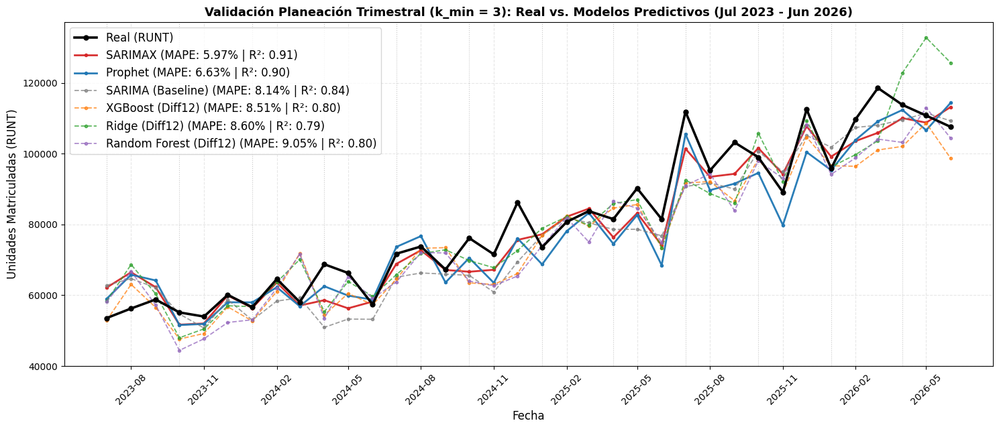

In [55]:
# TRES MESES #

# ==============================================================================
# 1. PREPARACIÓN Y REZAGOS CON HORIZONTE TRIMESTRAL (k_min = 3)
# ==============================================================================
HORIZONTE = 3
df_work = df_datamarket.merge(aux_real, on="Fecha", how="inner").sort_values("Fecha").reset_index(drop=True)
df_work["Var.TRM"] = df_work["Var.TRM"].fillna(0)
df_work["Var.PIB"] = df_work["Var.PIB"].fillna(0)

df_work["Mes"] = df_work["Fecha"].dt.month
df_work["Mes_sin"] = np.sin(2 * np.pi * df_work["Mes"] / 12)
df_work["Mes_cos"] = np.cos(2 * np.pi * df_work["Mes"] / 12)

for lag in [1, 2, 3, 6, 12]:
    df_work[f"Registros_PC_lag{lag}"] = df_work["Registros_PC"].shift(lag)

df_work["Delta12_Registros_PC"] = df_work["Registros_PC"] - df_work["Registros_PC_lag12"]
for lag in [1, 2, 3, 6, 12]:
    df_work[f"Delta12_Reg_lag{lag}"] = df_work["Delta12_Registros_PC"].shift(lag)

col_remesas = "Remesas_PC" if "Remesas_PC" in df_work.columns else "Remesas"
macro_cols = [
    "TasaDesocupacion", "TRM", "Var.TRM", "TasaInteres",
    "InflacionAnual", "InflacionMensual", "ICC",
    "PIB_PC", "Var.PIB", "Exportaciones_PC", "Importaciones_PC",
    col_remesas, "SMMLV_PA"
]

# Solo rezagos >= 3 meses para variables macroeconómicas
for col in macro_cols:
    df_work[f"Diff12_{col}"] = df_work[col] - df_work[col].shift(12)
    for lag in [3, 6, 12]:
        df_work[f"{col}_lag{lag}"] = df_work[col].shift(lag)
        df_work[f"Diff12_{col}_lag{lag}"] = df_work[f"Diff12_{col}"].shift(lag)

df_model = df_work.dropna().reset_index(drop=True)

exog_estadisticos_3m = [
    "DiasHabiles", "COVID", "DificultadesRUNT",
    "TasaInteres_lag3", "Var.TRM_lag3", "ICC_lag3",
    "SMMLV_PA_lag3", "Var.PIB_lag3", "TasaDesocupacion_lag3"
]

features_ml_3m = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "Delta12_Reg_lag1", "Delta12_Reg_lag2", "Delta12_Reg_lag3", "Delta12_Reg_lag12",
    "Diff12_TasaInteres_lag3", "Diff12_TasaInteres_lag6",
    "Diff12_TasaDesocupacion_lag3", "Diff12_TasaDesocupacion_lag6",
    "Diff12_ICC_lag3", "Diff12_ICC_lag6",
    "Diff12_SMMLV_PA_lag3", "Diff12_SMMLV_PA_lag6",
    "Diff12_InflacionAnual_lag3", "Diff12_InflacionAnual_lag6",
    "Diff12_PIB_PC_lag3", "Diff12_TRM_lag3", f"Diff12_{col_remesas}_lag3"
]

# ==============================================================================
# 2. VALIDACIÓN CRUZADA CRONOLÓGICA (12 CORTES DE 3 MESES = 36 MESES)
# ==============================================================================
def predecir_recursivo_diff12(modelo, train_df, test_df, cols_modelo):
    historia_pc = list(train_df["Registros_PC"].values)
    historia_d12 = list(train_df["Delta12_Registros_PC"].values)
    preds_pc = []
    for i in range(len(test_df)):
        fila = test_df.iloc[[i]][cols_modelo].copy()
        for lag in [1, 2, 3, 12]:
            col_lag = f"Delta12_Reg_lag{lag}"
            if col_lag in fila.columns:
                fila[col_lag] = historia_d12[-lag]
        pred_d12 = modelo.predict(fila)[0]
        pred_pc = historia_pc[-12] + pred_d12
        preds_pc.append(pred_pc)
        historia_pc.append(pred_pc)
        historia_d12.append(pred_d12)
    return np.array(preds_pc)

tscv = TimeSeriesSplit(n_splits=12, test_size=HORIZONTE)
nombres_modelos = [
    "SARIMA (Baseline)",
    "SARIMAX",
    "Prophet",
    "Ridge (Diff12)",
    "Random Forest (Diff12)",
    "XGBoost (Diff12)"
]
resultados_folds = {m: [] for m in nombres_modelos}
fechas_globales, y_true_global = [], []
preds_globales = {m: [] for m in nombres_modelos}

for tr_idx, te_idx in tscv.split(df_model):
    tr, te = df_model.iloc[tr_idx].copy(), df_model.iloc[te_idx].copy()
    factor_real = (te["PoblacionTotal"].values * 1000) / 100000
    yt = te["Registros"].values

    fechas_globales.extend(te["Fecha"].values)
    y_true_global.extend(yt)

    # 1. SARIMA
    p_sarima = SARIMAX(tr["Registros_PC"], order=(1,1,1), seasonal_order=(1,1,1,12), trend="c").fit(disp=False).forecast(HORIZONTE).values * factor_real
    # 2. SARIMAX
    p_sarimax = SARIMAX(tr["Registros_PC"], exog=tr[exog_estadisticos_3m], order=(1,1,1), seasonal_order=(1,1,1,12), trend="c").fit(disp=False).forecast(HORIZONTE, exog=te[exog_estadisticos_3m]).values * factor_real
    # 3. Prophet
    m_p = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, seasonality_mode="multiplicative", changepoint_prior_scale=0.15)
    for c in exog_estadisticos_3m: m_p.add_regressor(c)
    m_p.fit(tr[["Fecha", "Registros_PC"] + exog_estadisticos_3m].rename(columns={"Fecha": "ds", "Registros_PC": "y"}))
    p_prophet = m_p.predict(te[["Fecha"] + exog_estadisticos_3m].rename(columns={"Fecha": "ds"}))["yhat"].values * factor_real
    # 4. Ridge
    m_r = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=15.0))]).fit(tr[features_ml_3m], tr["Delta12_Registros_PC"])
    p_ridge = predecir_recursivo_diff12(m_r, tr, te, features_ml_3m) * factor_real
    # 5. Random Forest
    m_rf = RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_leaf=3, random_state=42).fit(tr[features_ml_3m], tr["Delta12_Registros_PC"])
    p_rf = predecir_recursivo_diff12(m_rf, tr, te, features_ml_3m) * factor_real
    # 6. XGBoost
    m_xgb = XGBRegressor(n_estimators=70, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, random_state=42).fit(tr[features_ml_3m], tr["Delta12_Registros_PC"])
    p_xgb = predecir_recursivo_diff12(m_xgb, tr, te, features_ml_3m) * factor_real

    for m, pred in zip(nombres_modelos, [p_sarima, p_sarimax, p_prophet, p_ridge, p_rf, p_xgb]):
        resultados_folds[m].append({
            "MAPE (%)": mean_absolute_percentage_error(yt, pred) * 100,
            "MAE": mean_absolute_error(yt, pred),
            "RMSE": np.sqrt(mean_squared_error(yt, pred))
        })
        preds_globales[m].extend(pred)

tabla_3m = pd.DataFrame({m: pd.DataFrame(met).mean() for m, met in resultados_folds.items()}).T
for m in nombres_modelos:
    tabla_3m.loc[m, "R2_Global_OOS"] = r2_score(y_true_global, preds_globales[m])
tabla_3m = tabla_3m.sort_values("MAPE (%)")

print("=== VALIDACIÓN PLANEACIÓN TRIMESTRAL (k_min = 3 | 12 VENTANAS DE 3 MESES = 36 MESES) ===")
print(tabla_3m.round(3))

# ==============================================================================
# GRÁFICO COMPARATIVO: TRAYECTORIA REAL VS. MODELOS (36 MESES FUERA DE MUESTRA)
# ==============================================================================
df_plot_3m = pd.DataFrame({"Fecha": fechas_globales, "Real": y_true_global})
for m in nombres_modelos:
    df_plot_3m[m] = preds_globales[m]

colores_modelos = {
    "Prophet": "#1f77b4",
    "SARIMAX": "#d62728",
    "Ridge (Diff12)": "#2ca02c",
    "XGBoost (Diff12)": "#ff7f0e",
    "Random Forest (Diff12)": "#9467bd",
    "SARIMA (Baseline)": "#7f7f7f"
}

fig, ax = plt.subplots(figsize=(15, 6.5))

# Serie real observada (RUNT)
ax.plot(df_plot_3m["Fecha"], df_plot_3m["Real"], label="Real (RUNT)", color="black", linewidth=2.6, marker="o", markersize=5, zorder=10)

# Curvas de cada modelo ordenadas según el ranking de MAPE
for m in tabla_3m.index:
    mape_val = tabla_3m.loc[m, "MAPE (%)"]
    r2_val = tabla_3m.loc[m, "R2_Global_OOS"]
    es_top = m in tabla_3m.index[:2]
    ax.plot(
        df_plot_3m["Fecha"],
        df_plot_3m[m],
        label=f"{m} (MAPE: {mape_val:.2f}% | R²: {r2_val:.2f})",
        color=colores_modelos[m],
        linestyle="-" if es_top else "--",
        linewidth=2.0 if es_top else 1.3,
        alpha=0.95 if es_top else 0.75,
        marker="."
    )

# Líneas verticales sutiles indicando el inicio de cada ventana trimestral (cada 3 meses)
for idx in range(0, len(df_plot_3m), HORIZONTE):
    ax.axvline(df_plot_3m["Fecha"].iloc[idx], color="gray", linestyle=":", linewidth=0.8, alpha=0.45)

ax.set_title("Validación Planeación Trimestral (k_min = 3): Real vs. Modelos Predictivos (Jul 2023 - Jun 2026)", fontsize=13, fontweight="bold")
ax.set_xlabel("Fecha", fontsize=12)
ax.set_ylabel("Unidades Matriculadas (RUNT)", fontsize=12)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=45)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="upper left", frameon=True, fontsize=12)
plt.tight_layout()
plt.show()


### SEIS MESES - DIFERENCIADO

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


=== VALIDACIÓN PLANEACIÓN SEMESTRAL (k_min = 6 | 6 VENTANAS DE 6 MESES = 36 MESES) ===
                        MAPE (%)       MAE       RMSE  R2_Global_OOS
Ridge (Diff12)             7.804  6147.442   7252.602          0.863
SARIMAX                    7.882  6411.767   7414.356          0.854
Prophet                    8.817  6745.718   7655.083          0.855
XGBoost (Diff12)           9.244  7494.115   9086.346          0.781
SARIMA (Baseline)          9.395  7591.443   8944.306          0.785
Random Forest (Diff12)    11.576  8908.408  10523.918          0.688


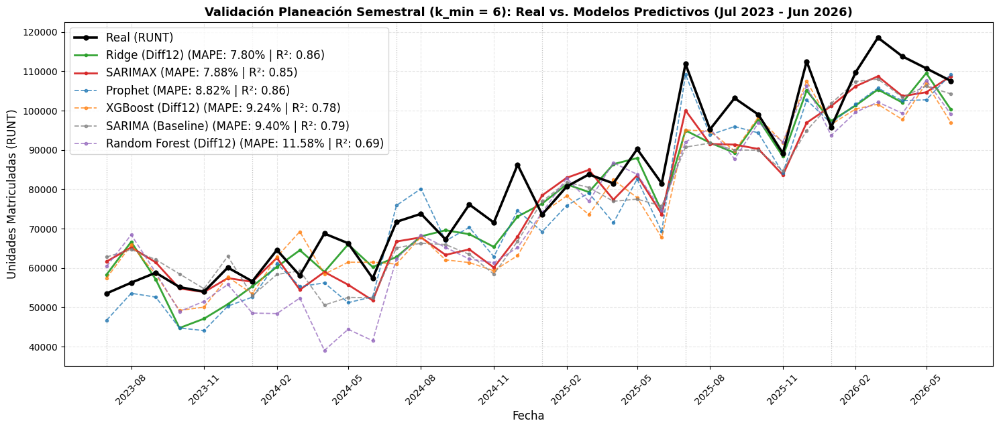

In [56]:
# SEIS MESES #

# ==============================================================================
# 1. PREPARACIÓN Y REZAGOS CON HORIZONTE SEMESTRAL (k_min = 6)
# ==============================================================================
HORIZONTE = 6
df_work = df_datamarket.merge(aux_real, on="Fecha", how="inner").sort_values("Fecha").reset_index(drop=True)
df_work["Var.TRM"] = df_work["Var.TRM"].fillna(0)
df_work["Var.PIB"] = df_work["Var.PIB"].fillna(0)

df_work["Mes"] = df_work["Fecha"].dt.month
df_work["Mes_sin"] = np.sin(2 * np.pi * df_work["Mes"] / 12)
df_work["Mes_cos"] = np.cos(2 * np.pi * df_work["Mes"] / 12)

for lag in [1, 2, 3, 6, 12]:
    df_work[f"Registros_PC_lag{lag}"] = df_work["Registros_PC"].shift(lag)

df_work["Delta12_Registros_PC"] = df_work["Registros_PC"] - df_work["Registros_PC_lag12"]
for lag in [1, 2, 3, 6, 12]:
    df_work[f"Delta12_Reg_lag{lag}"] = df_work["Delta12_Registros_PC"].shift(lag)

col_remesas = "Remesas_PC" if "Remesas_PC" in df_work.columns else "Remesas"
macro_cols = [
    "TasaDesocupacion", "TRM", "Var.TRM", "TasaInteres",
    "InflacionAnual", "InflacionMensual", "ICC",
    "PIB_PC", "Var.PIB", "Exportaciones_PC", "Importaciones_PC",
    col_remesas, "SMMLV_PA"
]

# Solo rezagos >= 6 meses para variables macroeconómicas
for col in macro_cols:
    df_work[f"Diff12_{col}"] = df_work[col] - df_work[col].shift(12)
    for lag in [6, 12]:
        df_work[f"{col}_lag{lag}"] = df_work[col].shift(lag)
        df_work[f"Diff12_{col}_lag{lag}"] = df_work[f"Diff12_{col}"].shift(lag)

df_model = df_work.dropna().reset_index(drop=True)

exog_estadisticos_6m = [
    "DiasHabiles", "COVID", "DificultadesRUNT",
    "TasaInteres_lag6", "Var.TRM_lag6", "ICC_lag6",
    "SMMLV_PA_lag6", "Var.PIB_lag6", "TasaDesocupacion_lag6"
]

features_ml_6m = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "Delta12_Reg_lag1", "Delta12_Reg_lag2", "Delta12_Reg_lag3", "Delta12_Reg_lag12",
    "Diff12_TasaInteres_lag6", "Diff12_TasaInteres_lag12",
    "Diff12_TasaDesocupacion_lag6", "Diff12_TasaDesocupacion_lag12",
    "Diff12_ICC_lag6", "Diff12_ICC_lag12",
    "Diff12_SMMLV_PA_lag6", "Diff12_SMMLV_PA_lag12",
    "Diff12_InflacionAnual_lag6", "Diff12_InflacionAnual_lag12",
    "Diff12_PIB_PC_lag6", "Diff12_TRM_lag6", f"Diff12_{col_remesas}_lag6"
]

# ==============================================================================
# 2. VALIDACIÓN CRUZADA CRONOLÓGICA (6 CORTES DE 6 MESES = 36 MESES)
# ==============================================================================
def predecir_recursivo_diff12(modelo, train_df, test_df, cols_modelo):
    historia_pc = list(train_df["Registros_PC"].values)
    historia_d12 = list(train_df["Delta12_Registros_PC"].values)
    preds_pc = []
    for i in range(len(test_df)):
        fila = test_df.iloc[[i]][cols_modelo].copy()
        for lag in [1, 2, 3, 12]:
            col_lag = f"Delta12_Reg_lag{lag}"
            if col_lag in fila.columns:
                fila[col_lag] = historia_d12[-lag]
        pred_d12 = modelo.predict(fila)[0]
        pred_pc = historia_pc[-12] + pred_d12
        preds_pc.append(pred_pc)
        historia_pc.append(pred_pc)
        historia_d12.append(pred_d12)
    return np.array(preds_pc)

tscv = TimeSeriesSplit(n_splits=6, test_size=HORIZONTE)
nombres_modelos = [
    "SARIMA (Baseline)",
    "SARIMAX",
    "Prophet",
    "Ridge (Diff12)",
    "Random Forest (Diff12)",
    "XGBoost (Diff12)"
]
resultados_folds = {m: [] for m in nombres_modelos}
fechas_globales, y_true_global = [], []
preds_globales = {m: [] for m in nombres_modelos}

for tr_idx, te_idx in tscv.split(df_model):
    tr, te = df_model.iloc[tr_idx].copy(), df_model.iloc[te_idx].copy()
    factor_real = (te["PoblacionTotal"].values * 1000) / 100000
    yt = te["Registros"].values

    fechas_globales.extend(te["Fecha"].values)
    y_true_global.extend(yt)

    p_sarima = SARIMAX(tr["Registros_PC"], order=(1,1,1), seasonal_order=(1,1,1,12), trend="c").fit(disp=False).forecast(HORIZONTE).values * factor_real
    p_sarimax = SARIMAX(tr["Registros_PC"], exog=tr[exog_estadisticos_6m], order=(1,1,1), seasonal_order=(1,1,1,12), trend="c").fit(disp=False).forecast(HORIZONTE, exog=te[exog_estadisticos_6m]).values * factor_real

    m_p = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, seasonality_mode="multiplicative", changepoint_prior_scale=0.15)
    for c in exog_estadisticos_6m: m_p.add_regressor(c)
    m_p.fit(tr[["Fecha", "Registros_PC"] + exog_estadisticos_6m].rename(columns={"Fecha": "ds", "Registros_PC": "y"}))
    p_prophet = m_p.predict(te[["Fecha"] + exog_estadisticos_6m].rename(columns={"Fecha": "ds"}))["yhat"].values * factor_real

    m_r = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=15.0))]).fit(tr[features_ml_6m], tr["Delta12_Registros_PC"])
    p_ridge = predecir_recursivo_diff12(m_r, tr, te, features_ml_6m) * factor_real

    m_rf = RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_leaf=3, random_state=42).fit(tr[features_ml_6m], tr["Delta12_Registros_PC"])
    p_rf = predecir_recursivo_diff12(m_rf, tr, te, features_ml_6m) * factor_real

    m_xgb = XGBRegressor(n_estimators=70, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, random_state=42).fit(tr[features_ml_6m], tr["Delta12_Registros_PC"])
    p_xgb = predecir_recursivo_diff12(m_xgb, tr, te, features_ml_6m) * factor_real

    for m, pred in zip(nombres_modelos, [p_sarima, p_sarimax, p_prophet, p_ridge, p_rf, p_xgb]):
        resultados_folds[m].append({
            "MAPE (%)": mean_absolute_percentage_error(yt, pred) * 100,
            "MAE": mean_absolute_error(yt, pred),
            "RMSE": np.sqrt(mean_squared_error(yt, pred))
        })
        preds_globales[m].extend(pred)

tabla_6m = pd.DataFrame({m: pd.DataFrame(met).mean() for m, met in resultados_folds.items()}).T
for m in nombres_modelos:
    tabla_6m.loc[m, "R2_Global_OOS"] = r2_score(y_true_global, preds_globales[m])
tabla_6m = tabla_6m.sort_values("MAPE (%)")

print("=== VALIDACIÓN PLANEACIÓN SEMESTRAL (k_min = 6 | 6 VENTANAS DE 6 MESES = 36 MESES) ===")
print(tabla_6m.round(3))

# ==============================================================================
# GRÁFICO COMPARATIVO: TRAYECTORIA REAL VS. MODELOS (36 MESES FUERA DE MUESTRA)
# ==============================================================================
df_plot_6m = pd.DataFrame({"Fecha": fechas_globales, "Real": y_true_global})
for m in nombres_modelos:
    df_plot_6m[m] = preds_globales[m]

colores_modelos = {
    "Prophet": "#1f77b4",
    "SARIMAX": "#d62728",
    "Ridge (Diff12)": "#2ca02c",
    "XGBoost (Diff12)": "#ff7f0e",
    "Random Forest (Diff12)": "#9467bd",
    "SARIMA (Baseline)": "#7f7f7f"
}

fig, ax = plt.subplots(figsize=(15, 6.5))

ax.plot(df_plot_6m["Fecha"], df_plot_6m["Real"], label="Real (RUNT)", color="black", linewidth=2.6, marker="o", markersize=5, zorder=10)

for m in tabla_6m.index:
    mape_val = tabla_6m.loc[m, "MAPE (%)"]
    r2_val = tabla_6m.loc[m, "R2_Global_OOS"]
    es_top = m in tabla_6m.index[:2]
    ax.plot(
        df_plot_6m["Fecha"],
        df_plot_6m[m],
        label=f"{m} (MAPE: {mape_val:.2f}% | R²: {r2_val:.2f})",
        color=colores_modelos[m],
        linestyle="-" if es_top else "--",
        linewidth=2.0 if es_top else 1.3,
        alpha=0.95 if es_top else 0.75,
        marker="."
    )

# Marcadores verticales indicando el inicio de cada ventana semestral (cada 6 meses)
for idx in range(0, len(df_plot_6m), HORIZONTE):
    ax.axvline(df_plot_6m["Fecha"].iloc[idx], color="gray", linestyle=":", linewidth=0.9, alpha=0.5)

ax.set_title("Validación Planeación Semestral (k_min = 6): Real vs. Modelos Predictivos (Jul 2023 - Jun 2026)", fontsize=13, fontweight="bold")
ax.set_xlabel("Fecha", fontsize=12)
ax.set_ylabel("Unidades Matriculadas (RUNT)", fontsize=12)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=45)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="upper left", frameon=True, fontsize=12)
plt.tight_layout()
plt.show()

### 12 MESES - DIFERENCIADO

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


=== VALIDACIÓN PLANEACIÓN ANUAL (k_min = 12 | 3 VENTANAS DE 12 MESES = 36 MESES) ===
                        MAPE (%)        MAE       RMSE  R2_Global_OOS
XGBoost (Diff12)          11.186   9233.019  10614.800          0.707
SARIMAX                   12.001  10498.017  11708.626          0.593
Ridge (Diff12)            12.212   9323.869  10723.270          0.718
SARIMA (Baseline)         13.014  11133.519  12617.183          0.572
Random Forest (Diff12)    14.678  11236.727  13295.768          0.562
Prophet                   21.327  16135.807  17577.288          0.224


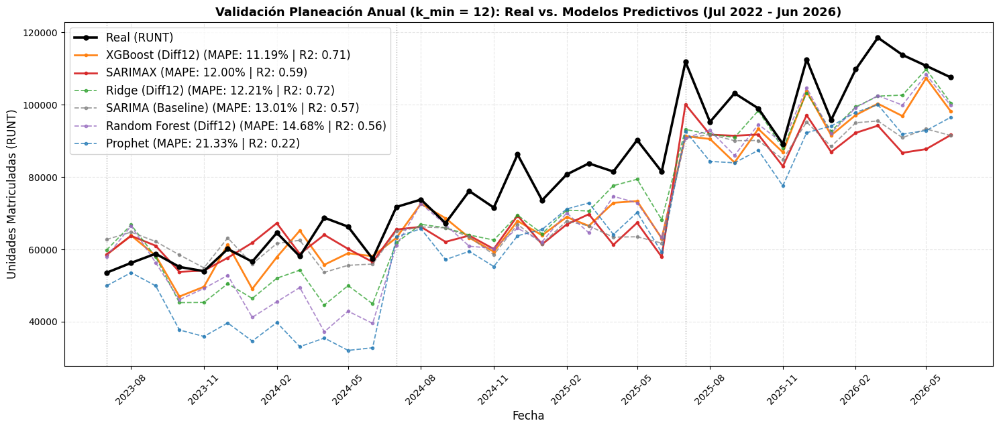

In [57]:
# 12 MESES #

# ==============================================================================
# 1. PREPARACIÓN Y REZAGOS CON HORIZONTE ANUAL (k_min = 12)
# ==============================================================================
HORIZONTE = 12
df_work = df_datamarket.merge(aux_real, on="Fecha", how="inner").sort_values("Fecha").reset_index(drop=True)
df_work["Var.TRM"] = df_work["Var.TRM"].fillna(0)
df_work["Var.PIB"] = df_work["Var.PIB"].fillna(0)

df_work["Mes"] = df_work["Fecha"].dt.month
df_work["Mes_sin"] = np.sin(2 * np.pi * df_work["Mes"] / 12)
df_work["Mes_cos"] = np.cos(2 * np.pi * df_work["Mes"] / 12)

for lag in [1, 2, 3, 6, 12]:
    df_work[f"Registros_PC_lag{lag}"] = df_work["Registros_PC"].shift(lag)

df_work["Delta12_Registros_PC"] = df_work["Registros_PC"] - df_work["Registros_PC_lag12"]
for lag in [1, 2, 3, 6, 12]:
    df_work[f"Delta12_Reg_lag{lag}"] = df_work["Delta12_Registros_PC"].shift(lag)

col_remesas = "Remesas_PC" if "Remesas_PC" in df_work.columns else "Remesas"
macro_cols = [
    "TasaDesocupacion", "TRM", "Var.TRM", "TasaInteres",
    "InflacionAnual", "InflacionMensual", "ICC",
    "PIB_PC", "Var.PIB", "Exportaciones_PC", "Importaciones_PC",
    col_remesas, "SMMLV_PA"
]

# Solo rezagos >= 12 meses para variables macroeconómicas (12 y 18 meses)
for col in macro_cols:
    df_work[f"Diff12_{col}"] = df_work[col] - df_work[col].shift(12)
    for lag in [12, 18]:
        df_work[f"{col}_lag{lag}"] = df_work[col].shift(lag)
        df_work[f"Diff12_{col}_lag{lag}"] = df_work[f"Diff12_{col}"].shift(lag)

df_model = df_work.dropna().reset_index(drop=True)

exog_estadisticos_12m = [
    "DiasHabiles", "COVID", "DificultadesRUNT",
    "TasaInteres_lag12", "Var.TRM_lag12", "ICC_lag12",
    "SMMLV_PA_lag12", "Var.PIB_lag12", "TasaDesocupacion_lag12"
]

features_ml_12m = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "Delta12_Reg_lag1", "Delta12_Reg_lag2", "Delta12_Reg_lag3", "Delta12_Reg_lag12",
    "Diff12_TasaInteres_lag12", "Diff12_TasaInteres_lag18",
    "Diff12_TasaDesocupacion_lag12", "Diff12_TasaDesocupacion_lag18",
    "Diff12_ICC_lag12", "Diff12_ICC_lag18",
    "Diff12_SMMLV_PA_lag12", "Diff12_SMMLV_PA_lag18",
    "Diff12_InflacionAnual_lag12", "Diff12_InflacionAnual_lag18",
    "Diff12_PIB_PC_lag12", "Diff12_TRM_lag12", f"Diff12_{col_remesas}_lag12"
]

# ==============================================================================
# 2. VALIDACIÓN CRUZADA CRONOLÓGICA (4 CORTES DE 12 MESES = 48 MESES)
# ==============================================================================
def predecir_recursivo_diff12(modelo, train_df, test_df, cols_modelo):
    historia_pc = list(train_df["Registros_PC"].values)
    historia_d12 = list(train_df["Delta12_Registros_PC"].values)
    preds_pc = []
    for i in range(len(test_df)):
        fila = test_df.iloc[[i]][cols_modelo].copy()
        for lag in [1, 2, 3, 12]:
            col_lag = f"Delta12_Reg_lag{lag}"
            if col_lag in fila.columns:
                fila[col_lag] = historia_d12[-lag]
        pred_d12 = modelo.predict(fila)[0]
        pred_pc = historia_pc[-12] + pred_d12
        preds_pc.append(pred_pc)
        historia_pc.append(pred_pc)
        historia_d12.append(pred_d12)
    return np.array(preds_pc)

tscv = TimeSeriesSplit(n_splits=3, test_size=HORIZONTE)
nombres_modelos = ["SARIMA (Baseline)", "SARIMAX", "Prophet", "Ridge (Diff12)", "Random Forest (Diff12)", "XGBoost (Diff12)"]
resultados_folds = {m: [] for m in nombres_modelos}
fechas_globales, y_true_global = [], []
preds_globales = {m: [] for m in nombres_modelos}

for tr_idx, te_idx in tscv.split(df_model):
    tr, te = df_model.iloc[tr_idx].copy(), df_model.iloc[te_idx].copy()
    factor_real = (te["PoblacionTotal"].values * 1000) / 100000
    yt = te["Registros"].values

    fechas_globales.extend(te["Fecha"].values)
    y_true_global.extend(yt)

    p_sarima = SARIMAX(tr["Registros_PC"], order=(1,1,1), seasonal_order=(1,1,1,12), trend="c").fit(disp=False).forecast(HORIZONTE).values * factor_real
    p_sarimax = SARIMAX(tr["Registros_PC"], exog=tr[exog_estadisticos_12m], order=(1,1,1), seasonal_order=(1,1,1,12), trend="c").fit(disp=False).forecast(HORIZONTE, exog=te[exog_estadisticos_12m]).values * factor_real

    m_p = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, seasonality_mode="multiplicative", changepoint_prior_scale=0.15)
    for c in exog_estadisticos_12m: m_p.add_regressor(c)
    m_p.fit(tr[["Fecha", "Registros_PC"] + exog_estadisticos_12m].rename(columns={"Fecha": "ds", "Registros_PC": "y"}))
    p_prophet = m_p.predict(te[["Fecha"] + exog_estadisticos_12m].rename(columns={"Fecha": "ds"}))["yhat"].values * factor_real

    m_r = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=15.0))]).fit(tr[features_ml_12m], tr["Delta12_Registros_PC"])
    p_ridge = predecir_recursivo_diff12(m_r, tr, te, features_ml_12m) * factor_real

    m_rf = RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_leaf=3, random_state=42).fit(tr[features_ml_12m], tr["Delta12_Registros_PC"])
    p_rf = predecir_recursivo_diff12(m_rf, tr, te, features_ml_12m) * factor_real

    m_xgb = XGBRegressor(n_estimators=70, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, random_state=42).fit(tr[features_ml_12m], tr["Delta12_Registros_PC"])
    p_xgb = predecir_recursivo_diff12(m_xgb, tr, te, features_ml_12m) * factor_real

    for m, pred in zip(nombres_modelos, [p_sarima, p_sarimax, p_prophet, p_ridge, p_rf, p_xgb]):
        resultados_folds[m].append({"MAPE (%)": mean_absolute_percentage_error(yt, pred)*100, "MAE": mean_absolute_error(yt, pred), "RMSE": np.sqrt(mean_squared_error(yt, pred))})
        preds_globales[m].extend(pred)

tabla_12m = pd.DataFrame({m: pd.DataFrame(met).mean() for m, met in resultados_folds.items()}).T
for m in nombres_modelos:
    tabla_12m.loc[m, "R2_Global_OOS"] = r2_score(y_true_global, preds_globales[m])
tabla_12m = tabla_12m.sort_values("MAPE (%)")

print("=== VALIDACIÓN PLANEACIÓN ANUAL (k_min = 12 | 3 VENTANAS DE 12 MESES = 36 MESES) ===")
print(tabla_12m.round(3))

# ==============================================================================
# GRÁFICO COMPARATIVO: TRAYECTORIA REAL VS. MODELOS (36 MESES FUERA DE MUESTRA)
# ==============================================================================
df_plot_12m = pd.DataFrame({"Fecha": fechas_globales, "Real": y_true_global})
for m in nombres_modelos:
    df_plot_12m[m] = preds_globales[m]

colores_modelos = {
    "Prophet": "#1f77b4",
    "SARIMAX": "#d62728",
    "Ridge (Diff12)": "#2ca02c",
    "XGBoost (Diff12)": "#ff7f0e",
    "Random Forest (Diff12)": "#9467bd",
    "SARIMA (Baseline)": "#7f7f7f"
}

fig, ax = plt.subplots(figsize=(15, 6.5))
ax.plot(df_plot_12m["Fecha"], df_plot_12m["Real"], label="Real (RUNT)", color="black", linewidth=2.6, marker="o", markersize=5, zorder=10)

for m in tabla_12m.index:
    mape_val = tabla_12m.loc[m, "MAPE (%)"]
    r2_val = tabla_12m.loc[m, "R2_Global_OOS"]
    es_top = m in tabla_12m.index[:2]
    etiqueta = f"{m} (MAPE: {mape_val:.2f}% | R2: {r2_val:.2f})"
    ax.plot(df_plot_12m["Fecha"], df_plot_12m[m], label=etiqueta, color=colores_modelos[m], linestyle="-" if es_top else "--", linewidth=2.0 if es_top else 1.3, alpha=0.95 if es_top else 0.75, marker=".")

# Marcadores verticales indicando el inicio de cada ventana anual (cada 12 meses)
for idx in range(0, len(df_plot_12m), HORIZONTE):
    ax.axvline(df_plot_12m["Fecha"].iloc[idx], color="gray", linestyle=":", linewidth=1.0, alpha=0.6)

ax.set_title("Validación Planeación Anual (k_min = 12): Real vs. Modelos Predictivos (Jul 2022 - Jun 2026)", fontsize=13, fontweight="bold")
ax.set_xlabel("Fecha", fontsize=12)
ax.set_ylabel("Unidades Matriculadas (RUNT)", fontsize=12)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=45)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="upper left", frameon=True, fontsize=12)
plt.tight_layout()
plt.show()


### 18 MESES - DIFERENCIADO

Dataset Estacionario listo: 222 meses (2008-01 a 2026-06)


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



=== TABLA COMPARATIVA CON ML DIFERENCIADO (4 VENTANAS DE 18 MESES) ===
                              MAPE (%)        MAE       RMSE           MSE  \
SARIMA (Baseline)               12.789  11343.124  13690.265  2.038348e+08   
SARIMAX (Lags >=18m)            17.475  14408.595  16892.504  2.858730e+08   
XGBoost (Diferenciado)          22.860  20524.938  23135.399  6.809042e+08   
Prophet (Lags >=18m)            23.374  20122.713  22372.930  5.327409e+08   
Random Forest (Diferenciado)    24.676  22256.009  24861.876  7.806116e+08   
Ridge (Diferenciado)            26.939  22960.270  25750.362  7.034762e+08   

                              R2_Global_OOS  
SARIMA (Baseline)                     0.503  
SARIMAX (Lags >=18m)                  0.304  
XGBoost (Diferenciado)               -0.659  
Prophet (Lags >=18m)                 -0.298  
Random Forest (Diferenciado)         -0.902  
Ridge (Diferenciado)                 -0.714  


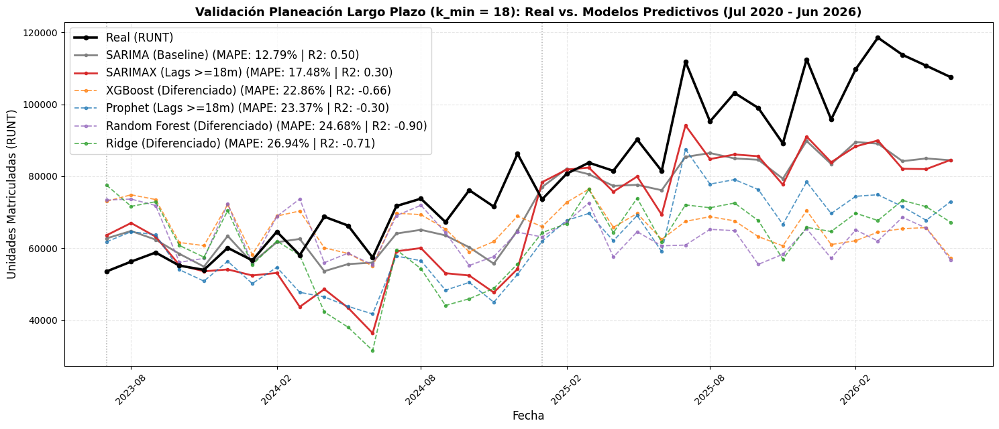

In [58]:
# ==============================================================================
# 1. INGENIERÍA DE CARACTERÍSTICAS CON DIFERENCIACIÓN ESTACIONARIA (LAGS >= 18)
# ==============================================================================
HORIZONTE = 18
df_work = (
    df_datamarket
    .merge(aux_real, on="Fecha", how="inner")
    .sort_values("Fecha")
    .reset_index(drop=True)
)

df_work["Var.TRM"] = df_work["Var.TRM"].fillna(0)
df_work["Var.PIB"] = df_work["Var.PIB"].fillna(0)

# Calendario cíclico
df_work["Mes"] = df_work["Fecha"].dt.month
df_work["Mes_sin"] = np.sin(2 * np.pi * df_work["Mes"] / 12)
df_work["Mes_cos"] = np.cos(2 * np.pi * df_work["Mes"] / 12)

# 1A. Diferenciación de la variable objetivo para Machine Learning:
# Usamos Delta24 (y_t - y_{t-24}) porque en un horizonte directo de 18 meses,
# el valor de t-24 (ej. Dic-2025 para predecir Dic-2027) es 100% REAL y conserva el mismo mes estacional.
df_work["Registros_PC_lag24"] = df_work["Registros_PC"].shift(24)
df_work["Target_Diff24"] = df_work["Registros_PC"] - df_work["Registros_PC_lag24"]

# 1B. Diferenciación interanual (Delta12) de los predictores autorregresivos (rezagados >= 18m)
df_work["Diff12_Reg_lag18"] = df_work["Registros_PC"].shift(18) - df_work["Registros_PC"].shift(30)
df_work["Diff12_Reg_lag24"] = df_work["Registros_PC"].shift(24) - df_work["Registros_PC"].shift(36)

# 1C. Variables macroeconómicas estacionarias / diferenciadas con rezagos >= 18 meses
df_work["Diff12_PIB_PC_lag18"] = df_work["PIB_PC"].shift(18) - df_work["PIB_PC"].shift(30)
df_work["Diff12_SMMLV_PA_lag18"] = df_work["SMMLV_PA"].shift(18) - df_work["SMMLV_PA"].shift(30)
df_work["Diff12_Remesas_PC_lag18"] = df_work["Remesas_PC"].shift(18) - df_work["Remesas_PC"].shift(30)

for col in ["TasaInteres", "Var.TRM", "ICC", "Var.PIB", "TasaDesocupacion", "InflacionAnual", "SMMLV_PA"]:
    df_work[f"{col}_lag18"] = df_work[col].shift(18)
    df_work[f"{col}_lag24"] = df_work[col].shift(24)

# Eliminar primeros 36 meses con NaN por las diferencias rezagadas
df_model = df_work.dropna().reset_index(drop=True)
print(f"Dataset Estacionario listo: {df_model.shape[0]} meses ({df_model['Fecha'].min().strftime('%Y-%m')} a {df_model['Fecha'].max().strftime('%Y-%m')})")

# Variables exógenas para SARIMAX y Prophet
exog_estadisticos_18m = [
    "DiasHabiles", "COVID", "DificultadesRUNT",
    "TasaInteres_lag18", "Var.TRM_lag18", "ICC_lag18",
    "SMMLV_PA_lag18", "Var.PIB_lag18", "TasaDesocupacion_lag18"
]

# Variables 100% diferenciadas/estacionarias para ML
features_ml_diff = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "Diff12_Reg_lag18", "Diff12_Reg_lag24",
    "Diff12_PIB_PC_lag18", "Diff12_SMMLV_PA_lag18", "Diff12_Remesas_PC_lag18",
    "TasaInteres_lag18", "TasaInteres_lag24",
    "Var.TRM_lag18", "Var.TRM_lag24",
    "ICC_lag18", "ICC_lag24",
    "Var.PIB_lag18", "Var.PIB_lag24",
    "TasaDesocupacion_lag18", "TasaDesocupacion_lag24",
    "InflacionAnual_lag18", "InflacionAnual_lag24"
]

# ==============================================================================
# 2. VALIDACIÓN CRUZADA CRONOLÓGICA (2 VENTANAS DE 18 MESES = 36 MESES)
# ==============================================================================
tscv = TimeSeriesSplit(n_splits=2, test_size=HORIZONTE)

nombres_modelos = [
    "SARIMA (Baseline)",
    "SARIMAX (Lags >=18m)",
    "Prophet (Lags >=18m)",
    "Ridge (Diferenciado)",
    "Random Forest (Diferenciado)",
    "XGBoost (Diferenciado)"
]

resultados_folds = {m: [] for m in nombres_modelos}
fechas_globales, y_true_global = [], []
preds_globales = {m: [] for m in nombres_modelos}

def metricas_fold(yt, yp):
    mse = mean_squared_error(yt, yp)
    return {
        "MAPE (%)": mean_absolute_percentage_error(yt, yp) * 100,
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": np.sqrt(mse),
        "MSE": mse
    }

for fold, (train_idx, test_idx) in enumerate(tscv.split(df_model)):
    tr, te = df_model.iloc[train_idx].copy(), df_model.iloc[test_idx].copy()
    factor_real = (te["PoblacionTotal"].values * 1000) / 100000
    y_true_abs = te["Registros"].values

    fechas_globales.extend(te["Fecha"].values)
    y_true_global.extend(y_true_abs)

    # 1. SARIMA
    m_sarima = SARIMAX(tr["Registros_PC"], order=(1,1,1), seasonal_order=(1,1,1,12), trend="c").fit(disp=False)
    p_sarima = m_sarima.forecast(HORIZONTE).values * factor_real
    resultados_folds["SARIMA (Baseline)"].append(metricas_fold(y_true_abs, p_sarima))
    preds_globales["SARIMA (Baseline)"].extend(p_sarima)

    # 2. SARIMAX
    m_sarimax = SARIMAX(tr["Registros_PC"], exog=tr[exog_estadisticos_18m], order=(1,1,1), seasonal_order=(1,1,1,12), trend="c").fit(disp=False)
    p_sarimax = m_sarimax.forecast(HORIZONTE, exog=te[exog_estadisticos_18m]).values * factor_real
    resultados_folds["SARIMAX (Lags >=18m)"].append(metricas_fold(y_true_abs, p_sarimax))
    preds_globales["SARIMAX (Lags >=18m)"].extend(p_sarimax)

    # 3. Prophet
    df_p_tr = tr[["Fecha", "Registros_PC"] + exog_estadisticos_18m].rename(columns={"Fecha": "ds", "Registros_PC": "y"})
    df_p_te = te[["Fecha"] + exog_estadisticos_18m].rename(columns={"Fecha": "ds"})
    m_prophet = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False,
                        seasonality_mode="multiplicative", changepoint_prior_scale=0.15)
    for col in exog_estadisticos_18m:
        m_prophet.add_regressor(col)
    m_prophet.fit(df_p_tr)
    p_prophet = m_prophet.predict(df_p_te)["yhat"].values * factor_real
    resultados_folds["Prophet (Lags >=18m)"].append(metricas_fold(y_true_abs, p_prophet))
    preds_globales["Prophet (Lags >=18m)"].extend(p_prophet)

    # 4. Ridge Diferenciado
    m_ridge = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=15.0))])
    m_ridge.fit(tr[features_ml_diff], tr["Target_Diff24"])
    p_ridge = (te["Registros_PC_lag24"].values + m_ridge.predict(te[features_ml_diff])) * factor_real
    resultados_folds["Ridge (Diferenciado)"].append(metricas_fold(y_true_abs, p_ridge))
    preds_globales["Ridge (Diferenciado)"].extend(p_ridge)

    # 5. Random Forest Diferenciado
    m_rf = RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_leaf=3, random_state=42)
    m_rf.fit(tr[features_ml_diff], tr["Target_Diff24"])
    p_rf = (te["Registros_PC_lag24"].values + m_rf.predict(te[features_ml_diff])) * factor_real
    resultados_folds["Random Forest (Diferenciado)"].append(metricas_fold(y_true_abs, p_rf))
    preds_globales["Random Forest (Diferenciado)"].extend(p_rf)

    # 6. XGBoost Diferenciado
    m_xgb = XGBRegressor(n_estimators=70, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, random_state=42)
    m_xgb.fit(tr[features_ml_diff], tr["Target_Diff24"])
    p_xgb = (te["Registros_PC_lag24"].values + m_xgb.predict(te[features_ml_diff])) * factor_real
    resultados_folds["XGBoost (Diferenciado)"].append(metricas_fold(y_true_abs, p_xgb))
    preds_globales["XGBoost (Diferenciado)"].extend(p_xgb)

tabla_diff = pd.DataFrame({m: pd.DataFrame(met).mean() for m, met in resultados_folds.items()}).T
for m in nombres_modelos:
    tabla_diff.loc[m, "R2_Global_OOS"] = r2_score(y_true_global, preds_globales[m])

tabla_diff = tabla_diff.sort_values("MAPE (%)")
print("\n=== TABLA COMPARATIVA CON ML DIFERENCIADO (4 VENTANAS DE 18 MESES) ===")
print(tabla_diff.round(3))

# ==============================================================================
# GRÁFICO COMPARATIVO: TRAYECTORIA REAL VS. MODELOS (72 MESES FUERA DE MUESTRA)
# ==============================================================================
df_plot_18m = pd.DataFrame({"Fecha": fechas_globales, "Real": y_true_global})
for m in nombres_modelos:
    df_plot_18m[m] = preds_globales[m]

colores_modelos = {
    "Prophet (Lags >=18m)": "#1f77b4",
    "SARIMAX (Lags >=18m)": "#d62728",
    "Ridge (Diferenciado)": "#2ca02c",
    "XGBoost (Diferenciado)": "#ff7f0e",
    "Random Forest (Diferenciado)": "#9467bd",
    "SARIMA (Baseline)": "#7f7f7f"
}

fig, ax = plt.subplots(figsize=(15, 6.5))
ax.plot(df_plot_18m["Fecha"], df_plot_18m["Real"], label="Real (RUNT)", color="black", linewidth=2.6, marker="o", markersize=4.5, zorder=10)

for m in tabla_diff.index:
    mape_val = tabla_diff.loc[m, "MAPE (%)"]
    r2_val = tabla_diff.loc[m, "R2_Global_OOS"]
    es_top = m in tabla_diff.index[:2]
    etiqueta = f"{m} (MAPE: {mape_val:.2f}% | R2: {r2_val:.2f})"
    ax.plot(df_plot_18m["Fecha"], df_plot_18m[m], label=etiqueta, color=colores_modelos[m], linestyle="-" if es_top else "--", linewidth=2.0 if es_top else 1.3, alpha=0.95 if es_top else 0.75, marker=".")

# Marcadores verticales indicando el inicio de cada ventana de 18 meses
for idx in range(0, len(df_plot_18m), HORIZONTE):
    ax.axvline(df_plot_18m["Fecha"].iloc[idx], color="gray", linestyle=":", linewidth=1.1, alpha=0.65)

ax.set_title("Validación Planeación Largo Plazo (k_min = 18): Real vs. Modelos Predictivos (Jul 2020 - Jun 2026)", fontsize=13, fontweight="bold")
ax.set_xlabel("Fecha", fontsize=12)
ax.set_ylabel("Unidades Matriculadas (RUNT)", fontsize=12)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=45)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="upper left", frameon=True, fontsize=12)
plt.tight_layout()
plt.show()

##Evaluación

=== TABLA MAESTRA: EVOLUCIÓN DEL MAPE (%) POR HORIZONTE EX-ANTE ===
                              1m (k=1)  3m (k=3)  6m (k=6)  12m (k=12)  \
Prophet                           9.98      6.63      8.82       21.33   
SARIMAX                          12.21      5.97      7.88       12.00   
Ridge (Diferenciado)               NaN      8.60      7.80       12.21   
XGBoost (Diferenciado)           13.61      8.51      9.24       11.19   
Random Forest (Diferenciado)     15.83      9.05     11.58       14.68   
SARIMA (Baseline)                16.79      8.14      9.40       13.01   

                              18m (k=18)  
Prophet                            23.37  
SARIMAX                            17.48  
Ridge (Diferenciado)               26.94  
XGBoost (Diferenciado)             22.86  
Random Forest (Diferenciado)       24.68  
SARIMA (Baseline)                  12.79  

=== TABLA MAESTRA: EVOLUCIÓN DEL R2 GLOBAL OOS POR HORIZONTE EX-ANTE ===
                              1m (k=1)

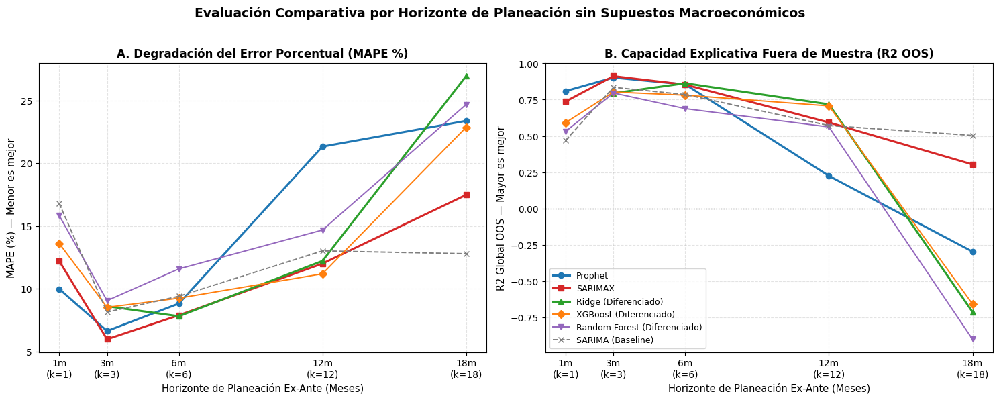

In [ ]:
# ==============================================================================
# 1. HOMOLOGAR NOMBRES DE MODELOS ENTRE TABLAS Y CONSOLIDAR MATRIZ MAESTRA
# ==============================================================================
mapa_nombres = {
    "SARIMA (Baseline)": "SARIMA (Baseline)",
    "SARIMAX": "SARIMAX",
    "SARIMAX (Lags >=18m)": "SARIMAX",
    "Prophet": "Prophet",
    "Prophet (Lags >=18m)": "Prophet",
    "Ridge (Diff12)": "Ridge (Diferenciado)",
    "Ridge (Diferenciado)": "Ridge (Diferenciado)",
    "Random Forest (Diff12)": "Random Forest (Diferenciado)",
    "Random Forest (Diferenciado)": "Random Forest (Diferenciado)",
    "XGBoost (Diff12)": "XGBoost (Diferenciado)",
    "XGBoost (Diferenciado)": "XGBoost (Diferenciado)"
}

# Diccionario con tus tablas ya calculadas (ajusta el nombre si tu tabla de 1m se llama distinto)
tablas_horizontes = {
    "1m (k=1)": tabla_1m_diff.rename(index=mapa_nombres),
    "3m (k=3)": tabla_3m.rename(index=mapa_nombres),
    "6m (k=6)": tabla_6m.rename(index=mapa_nombres),
    "12m (k=12)": tabla_12m.rename(index=mapa_nombres),
    "18m (k=18)": tabla_diff.rename(index=mapa_nombres)
}

modelos_orden = [
    "Prophet", "SARIMAX", "Ridge (Diferenciado)",
    "XGBoost (Diferenciado)", "Random Forest (Diferenciado)", "SARIMA (Baseline)"
]

# Construir Tabla Maestra de MAPE (%) y R2_Global_OOS
df_mape = pd.DataFrame(index=modelos_orden)
df_r2 = pd.DataFrame(index=modelos_orden)

for horiz, df_t in tablas_horizontes.items():
    df_mape[horiz] = df_t.reindex(modelos_orden)["MAPE (%)"]
    df_r2[horiz] = df_t.reindex(modelos_orden)["R2_Global_OOS"]

print("=== TABLA MAESTRA: EVOLUCIÓN DEL MAPE (%) POR HORIZONTE EX-ANTE ===")
print(df_mape.round(2))
print("\n=== TABLA MAESTRA: EVOLUCIÓN DEL R2 GLOBAL OOS POR HORIZONTE EX-ANTE ===")
print(df_r2.round(3))

# ==============================================================================
# 2. GRÁFICA DE DEGRADACIÓN DEL ERROR POR HORIZONTE (ERROR DECAY CURVE)
# ==============================================================================
colores = {
    "Prophet": "#1f77b4",
    "SARIMAX": "#d62728",
    "Ridge (Diferenciado)": "#2ca02c",
    "XGBoost (Diferenciado)": "#ff7f0e",
    "Random Forest (Diferenciado)": "#9467bd",
    "SARIMA (Baseline)": "#7f7f7f"
}
marcadores = {
    "Prophet": "o", "SARIMAX": "s", "Ridge (Diferenciado)": "^",
    "XGBoost (Diferenciado)": "D", "Random Forest (Diferenciado)": "v", "SARIMA (Baseline)": "x"
}

horizontes_num = [1, 3, 6, 12, 18]
etiquetas_x = ["1m\n(k=1)", "3m\n(k=3)", "6m\n(k=6)", "12m\n(k=12)", "18m\n(k=18)"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))

# Panel A: Evolución del MAPE (%)
for m in modelos_orden:
    axes[0].plot(
        horizontes_num, df_mape.loc[m].values,
        label=m, color=colores[m], marker=marcadores[m],
        linewidth=2.2 if m in ["Prophet", "SARIMAX", "Ridge (Diferenciado)"] else 1.4,
        linestyle="-" if m != "SARIMA (Baseline)" else "--"
    )
axes[0].set_title("A. Degradación del Error Porcentual (MAPE %)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Horizonte de Planeación Ex-Ante (Meses)", fontsize=10.5)
axes[0].set_ylabel("MAPE (%) — Menor es mejor", fontsize=10.5)
axes[0].set_xticks(horizontes_num)
axes[0].set_xticklabels(etiquetas_x)
axes[0].grid(True, linestyle="--", alpha=0.35)

# Panel B: Evolución del R2 Global OOS
for m in modelos_orden:
    axes[1].plot(
        horizontes_num, df_r2.loc[m].values,
        label=m, color=colores[m], marker=marcadores[m],
        linewidth=2.2 if m in ["Prophet", "SARIMAX", "Ridge (Diferenciado)"] else 1.4,
        linestyle="-" if m != "SARIMA (Baseline)" else "--"
    )
axes[1].axhline(0, color="black", linestyle=":", linewidth=1.0, alpha=0.6)
axes[1].set_title("B. Capacidad Explicativa Fuera de Muestra (R2 OOS)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Horizonte de Planeación Ex-Ante (Meses)", fontsize=10.5)
axes[1].set_ylabel("R2 Global OOS — Mayor es mejor", fontsize=10.5)
axes[1].set_xticks(horizontes_num)
axes[1].set_xticklabels(etiquetas_x)
axes[1].grid(True, linestyle="--", alpha=0.35)
axes[1].legend(loc="lower left", frameon=True, fontsize=9)

plt.suptitle("Evaluación Comparativa por Horizonte de Planeación sin Supuestos Macroeconómicos", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


=== EVOLUCIÓN DE P-VALORES EN SARIMAX POR HORIZONTE (p < 0.05 = Significativo) ===
                    k=3m    k=6m   k=12m   k=18m
DiasHabiles       0.0000  0.0000  0.0000  0.0000
TasaInteres       0.0880  0.7948  0.9922  0.2891
Var.TRM           0.8629  0.5916  0.9133  0.3255
ICC               0.3566  0.8840  0.7825  0.7361
SMMLV_PA          0.7129  0.2925  0.8557  0.3520
Var.PIB           0.4467  0.4225  0.9692  0.7806
TasaDesocupacion  0.8888  0.7240  0.0683  0.6052

=== DISTRIBUCIÓN DE IMPORTANCIA EXPLICATIVA EN XGBOOST POR HORIZONTE (%) ===
           Bloque Macroeconómico (%)  Inercia Autorregresiva (%)  \
Horizonte                                                          
k = 3m                     40.200001                   41.599998   
k = 6m                     46.099998                   38.200001   
k = 12m                    52.000000                   32.700001   
k = 18m                    73.199997                    6.600000   

           Calendario y Estacionalidad

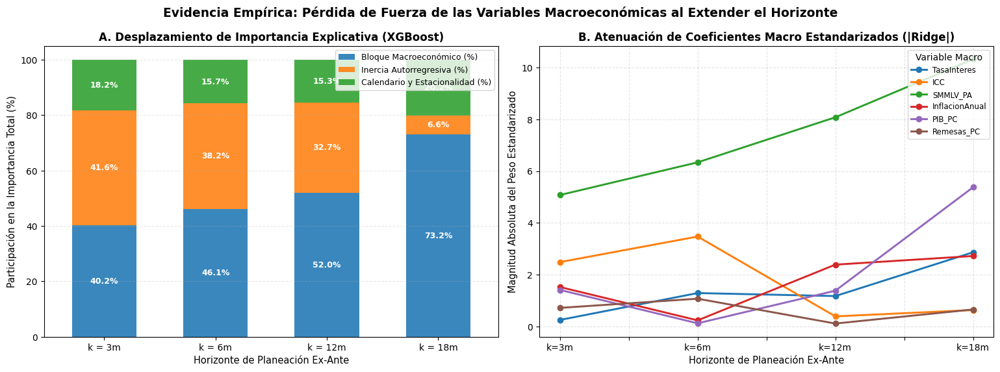

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor

# ==============================================================================
# 1. PREPARACIÓN UNIFICADA DE REZAGOS PARA LOS 4 HORIZONTES (k = 3, 6, 12, 18)
# ==============================================================================
df_exp = (
    df_datamarket
    .merge(aux_real, on="Fecha", how="inner")
    .sort_values("Fecha")
    .reset_index(drop=True)
)

df_exp["Var.TRM"] = df_exp["Var.TRM"].fillna(0)
df_exp["Var.PIB"] = df_exp["Var.PIB"].fillna(0)

df_exp["Mes"] = df_exp["Fecha"].dt.month
df_exp["Mes_sin"] = np.sin(2 * np.pi * df_exp["Mes"] / 12)
df_exp["Mes_cos"] = np.cos(2 * np.pi * df_exp["Mes"] / 12)

# Diferenciación interanual del objetivo y sus rezagos
df_exp["Delta12_Registros_PC"] = df_exp["Registros_PC"] - df_exp["Registros_PC"].shift(12)
for lag in [1, 2, 3, 12, 18, 24]:
    df_exp[f"Delta12_Reg_lag{lag}"] = df_exp["Delta12_Registros_PC"].shift(lag)

col_remesas = "Remesas_PC" if "Remesas_PC" in df_exp.columns else "Remesas"
macro_base = [
    "TasaInteres", "Var.TRM", "ICC", "SMMLV_PA",
    "Var.PIB", "TasaDesocupacion", "InflacionAnual", "PIB_PC", col_remesas
]

# Generar rezagos para k in [3, 6, 12, 18] y sus rezagos secundarios (+6m)
for col in macro_base:
    df_exp[f"Diff12_{col}"] = df_exp[col] - df_exp[col].shift(12)
    for lag in [3, 6, 9, 12, 18, 24]:
        df_exp[f"{col}_lag{lag}"] = df_exp[col].shift(lag)
        df_exp[f"Diff12_{col}_lag{lag}"] = df_exp[f"Diff12_{col}"].shift(lag)

df_exp_clean = df_exp.dropna().reset_index(drop=True)

# ==============================================================================
# 2. EXTRACCIÓN DE SIGNIFICANCIA (SARIMAX) Y PESOS (RIDGE / XGBOOST) POR HORIZONTE
# ==============================================================================
horizontes = [3, 6, 12, 18]
pvals_sarimax = {}
coefs_sarimax = {}
composicion_importancia = []
pesos_ridge_horizonte = {}

vars_macro_nombres = ["TasaInteres", "Var.TRM", "ICC", "SMMLV_PA", "Var.PIB", "TasaDesocupacion"]

for k in horizontes:
    # A. Variables exógenas de SARIMAX en horizonte k
    exog_k = ["DiasHabiles", "COVID", "DificultadesRUNT"] + [f"{v}_lag{k}" for v in vars_macro_nombres]
    m_s = SARIMAX(
        df_exp_clean["Registros_PC"],
        exog=df_exp_clean[exog_k],
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        trend="c"
    ).fit(disp=False, maxiter=200)

    p_serie, c_serie = {}, {}
    p_serie["DiasHabiles"] = m_s.pvalues["DiasHabiles"]
    c_serie["DiasHabiles"] = m_s.params["DiasHabiles"]
    for v in vars_macro_nombres:
        p_serie[v] = m_s.pvalues[f"{v}_lag{k}"]
        c_serie[v] = m_s.params[f"{v}_lag{k}"]

    pvals_sarimax[f"k={k}m"] = pd.Series(p_serie)
    coefs_sarimax[f"k={k}m"] = pd.Series(c_serie)

    # B. Variables de Machine Learning en horizonte k (sin duplicados cuando k=6)
    lag_sec = {3: 6, 6: 12, 12: 18, 18: 24}[k]
    lag_ar1 = 1 if k in [3, 6, 12] else 18
    lag_ar2 = 12 if k in [3, 6, 12] else 24

    feats_k = [
        "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
        f"Delta12_Reg_lag{lag_ar1}", f"Delta12_Reg_lag{lag_ar2}",
        f"Diff12_TasaInteres_lag{k}", f"Diff12_TasaInteres_lag{lag_sec}",
        f"Diff12_TasaDesocupacion_lag{k}", f"Diff12_ICC_lag{k}",
        f"Diff12_SMMLV_PA_lag{k}", f"Diff12_InflacionAnual_lag{k}",
        f"Diff12_PIB_PC_lag{k}", f"Diff12_{col_remesas}_lag{k}", f"Var.TRM_lag{k}"
    ]

    r_mod = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=15.0))])
    r_mod.fit(df_exp_clean[feats_k], df_exp_clean["Delta12_Registros_PC"])

    x_mod = XGBRegressor(n_estimators=70, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, random_state=42)
    x_mod.fit(df_exp_clean[feats_k], df_exp_clean["Delta12_Registros_PC"])

    pesos_ridge_horizonte[k] = pd.Series(r_mod.named_steps["model"].coef_, index=feats_k)

    imp_s = pd.Series(x_mod.feature_importances_, index=feats_k)
    grupo_calendario = imp_s[["DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos"]].sum() * 100
    grupo_inercia = imp_s[[f"Delta12_Reg_lag{lag_ar1}", f"Delta12_Reg_lag{lag_ar2}"]].sum() * 100
    grupo_macro = 100.0 - (grupo_calendario + grupo_inercia)

    composicion_importancia.append({
        "Horizonte": f"k = {k}m",
        "Bloque Macroeconómico (%)": grupo_macro,
        "Inercia Autorregresiva (%)": grupo_inercia,
        "Calendario y Estacionalidad (%)": grupo_calendario
    })

df_pvals = pd.DataFrame(pvals_sarimax)
df_comp = pd.DataFrame(composicion_importancia).set_index("Horizonte")

print("=== EVOLUCIÓN DE P-VALORES EN SARIMAX POR HORIZONTE (p < 0.05 = Significativo) ===")
print(df_pvals.round(4))
print("\n=== DISTRIBUCIÓN DE IMPORTANCIA EXPLICATIVA EN XGBOOST POR HORIZONTE (%) ===")
print(df_comp.round(1))

# ==============================================================================
# 3. GRÁFICO INTEGRADO: PÉRDIDA DE FUERZA MACROECONÓMICA AL AUMENTAR EL HORIZONTE
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8))

df_comp.plot(
    kind="bar", stacked=True, ax=axes[0],
    color=["#1f77b4", "#ff7f0e", "#2ca02c"], alpha=0.88, width=0.58
)
axes[0].set_title("A. Desplazamiento de Importancia Explicativa (XGBoost)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Participación en la Importancia Total (%)", fontsize=10.5)
axes[0].set_xlabel("Horizonte de Planeación Ex-Ante", fontsize=10.5)
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(True, axis="y", linestyle="--", alpha=0.3)
axes[0].legend(loc="upper right", frameon=True, fontsize=9)

for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.1f%%", label_type="center", color="white", fontweight="bold", fontsize=9)

macro_etiquetas = ["TasaInteres", "ICC", "SMMLV_PA", "InflacionAnual", "PIB_PC", col_remesas]
decay_ridge = pd.DataFrame(index=[f"k={k}m" for k in horizontes])
for m_var in macro_etiquetas:
    decay_ridge[m_var] = [abs(pesos_ridge_horizonte[k][f"Diff12_{m_var}_lag{k}"]) for k in horizontes]

decay_ridge.plot(kind="line", marker="o", linewidth=2.1, ax=axes[1])
axes[1].set_title("B. Atenuación de Coeficientes Macro Estandarizados (|Ridge|)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Magnitud Absoluta del Peso Estandarizado", fontsize=10.5)
axes[1].set_xlabel("Horizonte de Planeación Ex-Ante", fontsize=10.5)
axes[1].grid(True, linestyle="--", alpha=0.35)
axes[1].legend(title="Variable Macro", loc="upper right", frameon=True, fontsize=8.5)

plt.suptitle("Evidencia Empírica: Pérdida de Fuerza de las Variables Macroeconómicas al Extender el Horizonte", fontsize=13.5, fontweight="bold")
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


=== EVOLUCIÓN DE P-VALORES EN SARIMAX POR HORIZONTE (p < 0.05 = Significativo) ===
                    k=3m    k=6m   k=12m   k=18m
DiasHabiles       0.0000  0.0000  0.0000  0.0000
TasaInteres       0.0880  0.7948  0.9922  0.2891
Var.TRM           0.8629  0.5916  0.9133  0.3255
ICC               0.3566  0.8840  0.7825  0.7361
SMMLV_PA          0.7129  0.2925  0.8557  0.3520
Var.PIB           0.4467  0.4225  0.9692  0.7806
TasaDesocupacion  0.8888  0.7240  0.0683  0.6052

=== VARIANZA REAL EXPLICADA POR BLOQUE EN XGBOOST (Importancia x R2 OOS %) ===
           Bloque Macroeconómico (%)  Inercia Autorregresiva (%)  \
Horizonte                                                          
k = 3m                     32.279999                   33.430000   
k = 6m                     36.020000                   29.850000   
k = 12m                    36.750000                   23.110001   
k = 18m                     0.000000                    0.000000   

           Calendario y Estacionalid

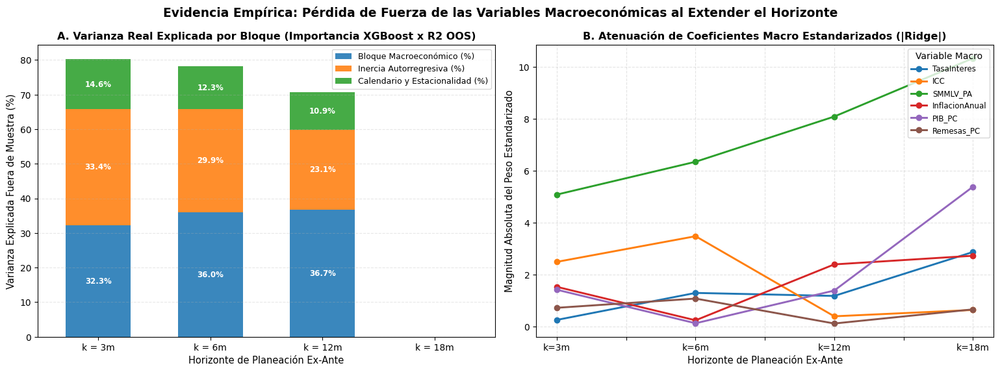

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor

# ==============================================================================
# 1. PREPARACIÓN UNIFICADA DE REZAGOS PARA LOS 4 HORIZONTES (k = 3, 6, 12, 18)
# ==============================================================================
df_exp = (
    df_datamarket
    .merge(aux_real, on="Fecha", how="inner")
    .sort_values("Fecha")
    .reset_index(drop=True)
)

df_exp["Var.TRM"] = df_exp["Var.TRM"].fillna(0)
df_exp["Var.PIB"] = df_exp["Var.PIB"].fillna(0)

df_exp["Mes"] = df_exp["Fecha"].dt.month
df_exp["Mes_sin"] = np.sin(2 * np.pi * df_exp["Mes"] / 12)
df_exp["Mes_cos"] = np.cos(2 * np.pi * df_exp["Mes"] / 12)

# Diferenciación interanual del objetivo y sus rezagos
df_exp["Delta12_Registros_PC"] = df_exp["Registros_PC"] - df_exp["Registros_PC"].shift(12)
for lag in [1, 2, 3, 12, 18, 24]:
    df_exp[f"Delta12_Reg_lag{lag}"] = df_exp["Delta12_Registros_PC"].shift(lag)

col_remesas = "Remesas_PC" if "Remesas_PC" in df_exp.columns else "Remesas"
macro_base = [
    "TasaInteres", "Var.TRM", "ICC", "SMMLV_PA",
    "Var.PIB", "TasaDesocupacion", "InflacionAnual", "PIB_PC", col_remesas
]

# Generar rezagos para k in [3, 6, 12, 18] y sus rezagos secundarios
for col in macro_base:
    df_exp[f"Diff12_{col}"] = df_exp[col] - df_exp[col].shift(12)
    for lag in [3, 6, 9, 12, 18, 24]:
        df_exp[f"{col}_lag{lag}"] = df_exp[col].shift(lag)
        df_exp[f"Diff12_{col}_lag{lag}"] = df_exp[f"Diff12_{col}"].shift(lag)

df_exp_clean = df_exp.dropna().reset_index(drop=True)

# ==============================================================================
# 2. EXTRACCIÓN DE SIGNIFICANCIA (SARIMAX) Y PESOS (RIDGE / XGBOOST) POR HORIZONTE
# ==============================================================================
horizontes = [3, 6, 12, 18]
pvals_sarimax = {}
coefs_sarimax = {}
composicion_importancia = []
pesos_ridge_horizonte = {}

vars_macro_nombres = ["TasaInteres", "Var.TRM", "ICC", "SMMLV_PA", "Var.PIB", "TasaDesocupacion"]

for k in horizontes:
    # A. Variables exógenas de SARIMAX en horizonte k
    exog_k = ["DiasHabiles", "COVID", "DificultadesRUNT"] + [f"{v}_lag{k}" for v in vars_macro_nombres]
    m_s = SARIMAX(
        df_exp_clean["Registros_PC"],
        exog=df_exp_clean[exog_k],
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        trend="c"
    ).fit(disp=False, maxiter=200)

    p_serie, c_serie = {}, {}
    p_serie["DiasHabiles"] = m_s.pvalues["DiasHabiles"]
    c_serie["DiasHabiles"] = m_s.params["DiasHabiles"]
    for v in vars_macro_nombres:
        p_serie[v] = m_s.pvalues[f"{v}_lag{k}"]
        c_serie[v] = m_s.params[f"{v}_lag{k}"]

    pvals_sarimax[f"k={k}m"] = pd.Series(p_serie)
    coefs_sarimax[f"k={k}m"] = pd.Series(c_serie)

    # B. Variables de Machine Learning en horizonte k (sin duplicados)
    lag_sec = {3: 6, 6: 12, 12: 18, 18: 24}[k]
    lag_ar1 = 1 if k in [3, 6, 12] else 18
    lag_ar2 = 12 if k in [3, 6, 12] else 24

    feats_k = [
        "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
        f"Delta12_Reg_lag{lag_ar1}", f"Delta12_Reg_lag{lag_ar2}",
        f"Diff12_TasaInteres_lag{k}", f"Diff12_TasaInteres_lag{lag_sec}",
        f"Diff12_TasaDesocupacion_lag{k}", f"Diff12_ICC_lag{k}",
        f"Diff12_SMMLV_PA_lag{k}", f"Diff12_InflacionAnual_lag{k}",
        f"Diff12_PIB_PC_lag{k}", f"Diff12_{col_remesas}_lag{k}", f"Var.TRM_lag{k}"
    ]

    r_mod = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=15.0))])
    r_mod.fit(df_exp_clean[feats_k], df_exp_clean["Delta12_Registros_PC"])

    x_mod = XGBRegressor(n_estimators=70, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, random_state=42)
    x_mod.fit(df_exp_clean[feats_k], df_exp_clean["Delta12_Registros_PC"])

    pesos_ridge_horizonte[k] = pd.Series(r_mod.named_steps["model"].coef_, index=feats_k)

    imp_s = pd.Series(x_mod.feature_importances_, index=feats_k)
    grupo_calendario = imp_s[["DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos"]].sum() * 100
    grupo_inercia = imp_s[[f"Delta12_Reg_lag{lag_ar1}", f"Delta12_Reg_lag{lag_ar2}"]].sum() * 100
    grupo_macro = 100.0 - (grupo_calendario + grupo_inercia)

    composicion_importancia.append({
        "Horizonte": f"k = {k}m",
        "Bloque Macroeconómico (%)": grupo_macro,
        "Inercia Autorregresiva (%)": grupo_inercia,
        "Calendario y Estacionalidad (%)": grupo_calendario
    })

df_pvals = pd.DataFrame(pvals_sarimax)
df_comp = pd.DataFrame(composicion_importancia).set_index("Horizonte")

# ==============================================================================
# 3. PONDERACIÓN POR CAPACIDAD EXPLICATIVA REAL (R2 OOS DE XGBOOST)
# ==============================================================================
def obtener_r2_xgb(tabla_h):
    for idx in tabla_h.index:
        if "XGBoost" in idx:
            return tabla_h.loc[idx, "R2_Global_OOS"]
    return 0.0

r2_por_horizonte = {
    "k = 3m": obtener_r2_xgb(tabla_3m),
    "k = 6m": obtener_r2_xgb(tabla_6m),
    "k = 12m": obtener_r2_xgb(tabla_12m),
    "k = 18m": obtener_r2_xgb(tabla_diff)
}

df_comp_ponderado = df_comp.copy()
for h, r2_val in r2_por_horizonte.items():
    df_comp_ponderado.loc[h] = (df_comp.loc[h] / 100.0) * max(r2_val, 0) * 100

print("=== EVOLUCIÓN DE P-VALORES EN SARIMAX POR HORIZONTE (p < 0.05 = Significativo) ===")
print(df_pvals.round(4))
print("\n=== VARIANZA REAL EXPLICADA POR BLOQUE EN XGBOOST (Importancia x R2 OOS %) ===")
print(df_comp_ponderado.round(2))

# ==============================================================================
# 4. GRÁFICO INTEGRADO: PÉRDIDA DE FUERZA MACROECONÓMICA AL AUMENTAR EL HORIZONTE
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8))

# Panel A: Barras apiladas ponderadas por el R2 real fuera de muestra
df_comp_ponderado.plot(
    kind="bar", stacked=True, ax=axes[0],
    color=["#1f77b4", "#ff7f0e", "#2ca02c"], alpha=0.88, width=0.58
)
axes[0].set_title("A. Varianza Real Explicada por Bloque (Importancia XGBoost x R2 OOS)", fontsize=11.5, fontweight="bold")
axes[0].set_ylabel("Varianza Explicada Fuera de Muestra (%)", fontsize=10.5)
axes[0].set_xlabel("Horizonte de Planeación Ex-Ante", fontsize=10.5)
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(True, axis="y", linestyle="--", alpha=0.3)
axes[0].legend(loc="upper right", frameon=True, fontsize=9)

for c in axes[0].containers:
    labels = [f"{v:.1f}%" if v >= 3.0 else "" for v in c.datavalues]
    axes[0].bar_label(c, labels=labels, label_type="center", color="white", fontweight="bold", fontsize=8.5)

# Panel B: Decaimiento de la magnitud de coeficientes macro en Ridge
macro_etiquetas = ["TasaInteres", "ICC", "SMMLV_PA", "InflacionAnual", "PIB_PC", col_remesas]
decay_ridge = pd.DataFrame(index=[f"k={k}m" for k in horizontes])
for m_var in macro_etiquetas:
    decay_ridge[m_var] = [abs(pesos_ridge_horizonte[k][f"Diff12_{m_var}_lag{k}"]) for k in horizontes]

decay_ridge.plot(kind="line", marker="o", linewidth=2.1, ax=axes[1])
axes[1].set_title("B. Atenuación de Coeficientes Macro Estandarizados (|Ridge|)", fontsize=11.5, fontweight="bold")
axes[1].set_ylabel("Magnitud Absoluta del Peso Estandarizado", fontsize=10.5)
axes[1].set_xlabel("Horizonte de Planeación Ex-Ante", fontsize=10.5)
axes[1].grid(True, linestyle="--", alpha=0.35)
axes[1].legend(title="Variable Macro", loc="upper right", frameon=True, fontsize=8.5)

plt.suptitle("Evidencia Empírica: Pérdida de Fuerza de las Variables Macroeconómicas al Extender el Horizonte", fontsize=13.5, fontweight="bold")
plt.tight_layout()
plt.show()

**Análisis de Residuos, Interpretabilidad y Sensibilidad**

[VERIFICACIÓN] MAPE Ridge 6m en 6 Ventanas Semestrales (36 meses OOS): 7.80%

=== 1. DIAGNÓSTICO DE RESIDUOS RIDGE 6M (6 VENTANAS DE 6M, N = 36) ===
Sesgo Medio (ME):           +4,115 unidades (+4.52%)
Desviación Estándar (SD):   6,350 unidades
Test t sesgo nulo (p-val):  t = 3.888 | p = 0.0004
Normalidad Shapiro-Wilk:    W = 0.989 | p = 0.9695
Ljung-Box (lag 3):          Q = 0.536 | p = 0.9110
Ljung-Box (lag 6):          Q = 3.609 | p = 0.7294

=== 2. INTERPRETABILIDAD RIDGE 6M (PROMEDIO EN LAS 6 VENTANAS SEMESTRALES) ===
                             Driver  Coef_Promedio_6Ventanas  Desv_Est_Ventanas
     Inercia Interanual (Rezago 1m)                 7.554889           0.152771
               Días Hábiles del Mes                 3.308002           0.352248
    Inercia Interanual (Rezago 12m)                -3.044343           0.242067
Var. Interanual Confianza ICC (t-6)                 2.859360           0.167769
   Var. Interanual SMMLV Real (t-6)                 2.580998           

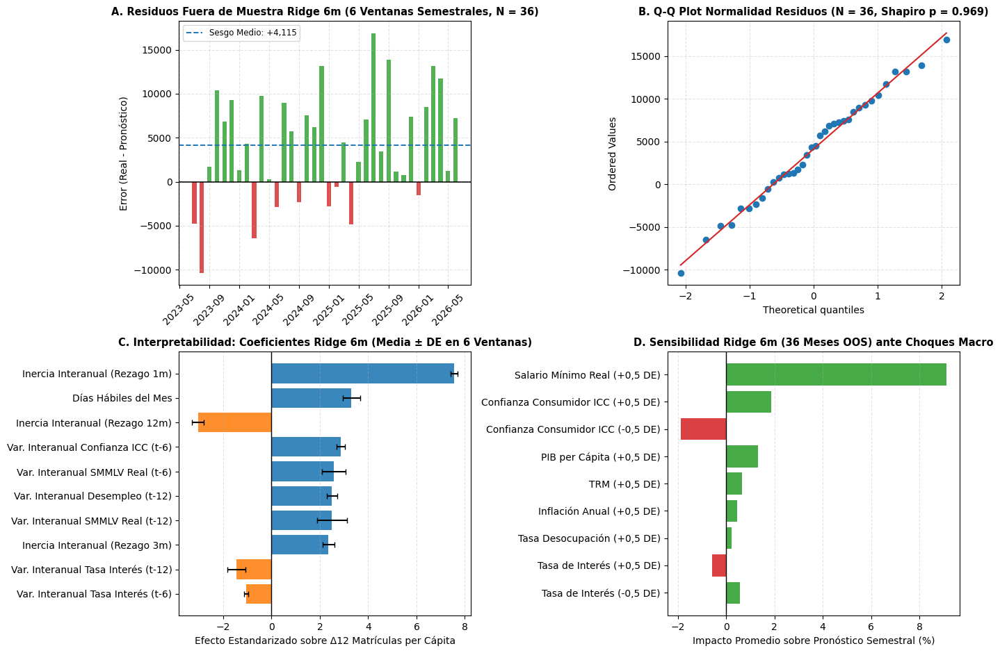

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. PREPARACIÓN DE DATOS (PROTOCOLO DE 36 MESES OOS: JUL 2023 – JUN 2026)
# ==============================================================================
df_base = df_datamarket.merge(aux_real, on="Fecha", how="inner").sort_values("Fecha").reset_index(drop=True)
df_base["Var.TRM"] = df_base["Var.TRM"].fillna(0)
df_base["Var.PIB"] = df_base["Var.PIB"].fillna(0)
df_total = df_base[df_base["Fecha"] <= "2026-06-30"].copy().reset_index(drop=True)

col_remesas = "Remesas_PC" if "Remesas_PC" in df_total.columns else "Remesas"
macro_cols = [
    "TasaDesocupacion", "TRM", "Var.TRM", "TasaInteres",
    "InflacionAnual", "InflacionMensual", "ICC",
    "PIB_PC", "Var.PIB", "Exportaciones_PC", "Importaciones_PC",
    col_remesas, "SMMLV_PA"
]

df_feat = df_total.copy()
df_feat["Mes"] = df_feat["Fecha"].dt.month
df_feat["Mes_sin"] = np.sin(2 * np.pi * df_feat["Mes"] / 12)
df_feat["Mes_cos"] = np.cos(2 * np.pi * df_feat["Mes"] / 12)

for lag in [1, 2, 3, 6, 12]:
    df_feat[f"Registros_PC_lag{lag}"] = df_feat["Registros_PC"].shift(lag)

df_feat["Delta12_Registros_PC"] = df_feat["Registros_PC"] - df_feat["Registros_PC_lag12"]
for lag in [1, 2, 3, 6, 12]:
    df_feat[f"Delta12_Reg_lag{lag}"] = df_feat["Delta12_Registros_PC"].shift(lag)

for col in macro_cols:
    df_feat[f"Diff12_{col}"] = df_feat[col] - df_feat[col].shift(12)
    for lag in [6, 12]:
        df_feat[f"Diff12_{col}_lag{lag}"] = df_feat[f"Diff12_{col}"].shift(lag)

feats_r6 = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "Delta12_Reg_lag1", "Delta12_Reg_lag2", "Delta12_Reg_lag3", "Delta12_Reg_lag12",
    "Diff12_TasaInteres_lag6", "Diff12_TasaInteres_lag12",
    "Diff12_TasaDesocupacion_lag6", "Diff12_TasaDesocupacion_lag12",
    "Diff12_ICC_lag6", "Diff12_ICC_lag12",
    "Diff12_SMMLV_PA_lag6", "Diff12_SMMLV_PA_lag12",
    "Diff12_InflacionAnual_lag6", "Diff12_InflacionAnual_lag12",
    "Diff12_PIB_PC_lag6", "Diff12_TRM_lag6", f"Diff12_{col_remesas}_lag6"
]

def predecir_trayectoria_6m(pipe, df_train_sub, df_fut_sub):
    """Genera los 6 pasos recursivos de Ridge 6m para una ventana semestral."""
    k = len(df_fut_sub)
    factor_fut = (df_fut_sub["PoblacionTotal"].values * 1000) / 100000

    df_u = pd.concat([df_train_sub.tail(30), df_fut_sub], ignore_index=True)
    df_u[macro_cols] = df_u[macro_cols].ffill()
    for col in macro_cols:
        diff_c = df_u[col] - df_u[col].shift(12)
        df_u[f"Diff12_{col}_lag6"]  = diff_c.shift(6)
        df_u[f"Diff12_{col}_lag12"] = diff_c.shift(12)
    df_te = df_u.iloc[30:].reset_index(drop=True)

    hist_pc  = list(df_train_sub["Registros_PC"].values)
    hist_d12 = list(df_train_sub["Delta12_Registros_PC"].dropna().values)
    preds_pc = []
    for step in range(k):
        fila = df_te.iloc[[step]][feats_r6].copy()
        for lag in [1, 2, 3, 12]:
            fila[f"Delta12_Reg_lag{lag}"] = hist_d12[-lag]
        p_d12 = pipe.predict(fila)[0]
        p_pc  = hist_pc[-12] + p_d12
        preds_pc.append(p_pc)
        hist_pc.append(p_pc)
        hist_d12.append(p_d12)

    return np.array(preds_pc) * factor_fut

# ==============================================================================
# 2. AJUSTE SOBRE LAS 6 VENTANAS CONSECUTIVAS DE 6 MESES (36 MESES OOS)
#    Cortes: Jun 2023, Dic 2023, Jun 2024, Dic 2024, Jun 2025, Dic 2025
# ==============================================================================
cortes_6ventanas = [
    "2023-06-01", "2023-12-01", "2024-06-01",
    "2024-12-01", "2025-06-01", "2025-12-01"
]

cache_6w = []
fechas_36m, reales_36m, preds_36m, coefs_6w = [], [], [], []

for f_corte in cortes_6ventanas:
    c_idx = df_feat.index[df_feat["Fecha"] == f_corte][0]
    df_tr = df_feat.iloc[:c_idx + 1].reset_index(drop=True)
    df_fu = df_feat.iloc[c_idx + 1 : c_idx + 7].reset_index(drop=True)

    df_tr_clean = df_tr.dropna(subset=feats_r6 + ["Delta12_Registros_PC"]).reset_index(drop=True)
    pipe_r6 = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=15.0))])
    pipe_r6.fit(df_tr_clean[feats_r6], df_tr_clean["Delta12_Registros_PC"])

    y_hat_6m = predecir_trayectoria_6m(pipe_r6, df_tr, df_fu)

    cache_6w.append((pipe_r6, df_tr, df_fu))
    fechas_36m.append(df_fu["Fecha"].values)
    reales_36m.append(df_fu["Registros"].values)
    preds_36m.append(y_hat_6m)
    coefs_6w.append(pipe_r6.named_steps["model"].coef_)

fechas_36m = np.concatenate(fechas_36m)
reales_36m = np.concatenate(reales_36m)
preds_36m  = np.concatenate(preds_36m)
coefs_6w   = np.array(coefs_6w)

residuos_36m = reales_36m - preds_36m
res_pct_36m  = (residuos_36m / reales_36m) * 100

print(f"[VERIFICACIÓN] MAPE Ridge 6m en 6 Ventanas Semestrales (36 meses OOS): {np.mean(np.abs(res_pct_36m)):.2f}%\n")

# ==============================================================================
# 3. PARTE 1: DIAGNÓSTICO DE RESIDUOS EN 6 VENTANAS DE 6 MESES (N = 36)
# ==============================================================================
lb_test = acorr_ljungbox(residuos_36m, lags=[3, 6], return_df=True)
sw_stat, sw_pval = stats.shapiro(residuos_36m)
t_stat, t_pval   = stats.ttest_1samp(residuos_36m, 0.0)

print("=== 1. DIAGNÓSTICO DE RESIDUOS RIDGE 6M (6 VENTANAS DE 6M, N = 36) ===")
print(f"Sesgo Medio (ME):           {np.mean(residuos_36m):+,.0f} unidades ({np.mean(res_pct_36m):+.2f}%)")
print(f"Desviación Estándar (SD):   {np.std(residuos_36m, ddof=1):,.0f} unidades")
print(f"Test t sesgo nulo (p-val):  t = {t_stat:.3f} | p = {t_pval:.4f}")
print(f"Normalidad Shapiro-Wilk:    W = {sw_stat:.3f} | p = {sw_pval:.4f}")
print(f"Ljung-Box (lag 3):          Q = {lb_test.loc[3, 'lb_stat']:.3f} | p = {lb_test.loc[3, 'lb_pvalue']:.4f}")
print(f"Ljung-Box (lag 6):          Q = {lb_test.loc[6, 'lb_stat']:.3f} | p = {lb_test.loc[6, 'lb_pvalue']:.4f}")

# ==============================================================================
# 4. PARTE 2: INTERPRETABILIDAD RIDGE 6M (PROMEDIO EN LAS 6 VENTANAS)
# ==============================================================================
etiquetas_r6 = {
    "Delta12_Reg_lag1":               "Inercia Interanual (Rezago 1m)",
    "Delta12_Reg_lag2":               "Inercia Interanual (Rezago 2m)",
    "Delta12_Reg_lag3":               "Inercia Interanual (Rezago 3m)",
    "Delta12_Reg_lag12":              "Inercia Interanual (Rezago 12m)",
    "Diff12_TasaInteres_lag6":        "Var. Interanual Tasa Interés (t-6)",
    "Diff12_TasaInteres_lag12":       "Var. Interanual Tasa Interés (t-12)",
    "Diff12_TasaDesocupacion_lag6":   "Var. Interanual Desempleo (t-6)",
    "Diff12_TasaDesocupacion_lag12":  "Var. Interanual Desempleo (t-12)",
    "Diff12_ICC_lag6":                "Var. Interanual Confianza ICC (t-6)",
    "Diff12_ICC_lag12":               "Var. Interanual Confianza ICC (t-12)",
    "Diff12_SMMLV_PA_lag6":           "Var. Interanual SMMLV Real (t-6)",
    "Diff12_SMMLV_PA_lag12":          "Var. Interanual SMMLV Real (t-12)",
    "Diff12_InflacionAnual_lag6":     "Var. Interanual Inflación (t-6)",
    "Diff12_InflacionAnual_lag12":    "Var. Interanual Inflación (t-12)",
    "Diff12_PIB_PC_lag6":             "Var. Interanual PIB per Cápita (t-6)",
    "Diff12_TRM_lag6":                "Var. Interanual TRM (t-6)",
    f"Diff12_{col_remesas}_lag6":     "Var. Interanual Remesas (t-6)",
    "DiasHabiles":                    "Días Hábiles del Mes",
    "Mes_sin":                        "Estacionalidad Mensual (Seno)",
    "Mes_cos":                        "Estacionalidad Mensual (Coseno)",
}

df_imp_r6 = pd.DataFrame({
    "Variable": feats_r6,
    "Driver": [etiquetas_r6.get(f, f) for f in feats_r6],
    "Coef_Promedio_6Ventanas": np.mean(coefs_6w, axis=0),
    "Desv_Est_Ventanas": np.std(coefs_6w, axis=0, ddof=1),
    "Abs_Imp": np.abs(np.mean(coefs_6w, axis=0))
})
df_imp_r6 = df_imp_r6[~df_imp_r6["Variable"].isin(["COVID", "DificultadesRUNT"])].sort_values("Abs_Imp", ascending=True).tail(10)

print("\n=== 2. INTERPRETABILIDAD RIDGE 6M (PROMEDIO EN LAS 6 VENTANAS SEMESTRALES) ===")
print(df_imp_r6[["Driver", "Coef_Promedio_6Ventanas", "Desv_Est_Ventanas"]].iloc[::-1].to_string(index=False))

# ==============================================================================
# 5. PARTE 3: SENSIBILIDAD MACROECONÓMICA EN ESCALA REAL (6 VENTANAS)
# ==============================================================================
stds_macro = df_feat[macro_cols].std()

choques_realistas = [
    ("Salario Mínimo Real (+0,5 DE)",     "SMMLV_PA",         +0.5 * stds_macro["SMMLV_PA"]),
    ("Confianza Consumidor ICC (+0,5 DE)","ICC",              +0.5 * stds_macro["ICC"]),
    ("Confianza Consumidor ICC (-0,5 DE)","ICC",              -0.5 * stds_macro["ICC"]),
    ("PIB per Cápita (+0,5 DE)",          "PIB_PC",           +0.5 * stds_macro["PIB_PC"]),
    ("TRM (+0,5 DE)",                     "TRM",              +0.5 * stds_macro["TRM"]),
    ("Inflación Anual (+0,5 DE)",         "InflacionAnual",   +0.5 * stds_macro["InflacionAnual"]),
    ("Tasa Desocupación (+0,5 DE)",       "TasaDesocupacion", +0.5 * stds_macro["TasaDesocupacion"]),
    ("Tasa de Interés (+0,5 DE)",         "TasaInteres",      +0.5 * stds_macro["TasaInteres"]),
    ("Tasa de Interés (-0,5 DE)",         "TasaInteres",      -0.5 * stds_macro["TasaInteres"]),
]

resultados_sens = []
base_media_36m = np.mean(preds_36m)

for nombre_esc, col_var, delta in choques_realistas:
    preds_esc_list = []
    for pipe_r6, df_tr, df_fu in cache_6w:
        df_tr_m = df_tr.copy()
        df_fu_m = df_fu.copy()
        # Aplicamos el choque en los 6 meses previos al corte (entran por lag6) y en df_fu
        df_tr_m.iloc[-6:, df_tr_m.columns.get_loc(col_var)] += delta
        df_fu_m[col_var] += delta
        preds_esc_list.append(predecir_trayectoria_6m(pipe_r6, df_tr_m, df_fu_m))

    preds_esc_all = np.concatenate(preds_esc_list)
    diff_mensual = np.mean(preds_esc_all - preds_36m)
    diff_pct     = (diff_mensual / base_media_36m) * 100
    resultados_sens.append({
        "Escenario de Choque (Ridge 6m)": nombre_esc,
        "Impacto Mensual Prom. (Unid.)": int(round(diff_mensual, 0)),
        "Variación (%)": round(diff_pct, 2)
    })

df_sens = pd.DataFrame(resultados_sens)
print("\n=== 3. SENSIBILIDAD RIDGE 6M EN 6 VENTANAS SEMESTRALES (36 MESES OOS) ===")
print(df_sens.to_string(index=False))

# ==============================================================================
# 6. PANEL GRÁFICO INTEGRADO DE DIAGNÓSTICO (4 PANELES COMPLETOS)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

# Panel A: Residuos en el tiempo (convertidos a datetime de Pandas)
fechas_plot = pd.to_datetime(fechas_36m)
axes[0, 0].bar(fechas_plot, residuos_36m, width=18, color=np.where(residuos_36m >= 0, "#2ca02c", "#d62728"), alpha=0.82)
axes[0, 0].axhline(0, color="black", linewidth=1.1)
axes[0, 0].axhline(np.mean(residuos_36m), color="#1f77b4", linestyle="--", linewidth=1.4, label=f"Sesgo Medio: {np.mean(residuos_36m):+,.0f}")
axes[0, 0].set_title("A. Residuos Fuera de Muestra Ridge 6m (6 Ventanas Semestrales, N = 36)", fontsize=10.5, fontweight="bold")
axes[0, 0].set_ylabel("Error (Real - Pronóstico)")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(True, linestyle="--", alpha=0.35)
axes[0, 0].legend(fontsize=8.5)

# Panel B: Q-Q Plot Normalidad
stats.probplot(residuos_36m, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title(f"B. Q-Q Plot Normalidad Residuos (N = 36, Shapiro p = {sw_pval:.3f})", fontsize=10.5, fontweight="bold")
axes[0, 1].get_lines()[0].set_color("#1f77b4")
axes[0, 1].get_lines()[1].set_color("#d62728")
axes[0, 1].grid(True, linestyle="--", alpha=0.35)

# Panel C: Interpretabilidad Ridge 6m
colores_imp = np.where(df_imp_r6["Coef_Promedio_6Ventanas"] >= 0, "#1f77b4", "#ff7f0e")
axes[1, 0].barh(df_imp_r6["Driver"], df_imp_r6["Coef_Promedio_6Ventanas"], xerr=df_imp_r6["Desv_Est_Ventanas"], color=colores_imp, alpha=0.88, capsize=3)
axes[1, 0].axvline(0, color="black", linewidth=1.0)
axes[1, 0].set_title("C. Interpretabilidad: Coeficientes Ridge 6m (Media ± DE en 6 Ventanas)", fontsize=10.5, fontweight="bold")
axes[1, 0].set_xlabel("Efecto Estandarizado sobre Δ12 Matrículas per Cápita")
axes[1, 0].grid(True, axis="x", linestyle="--", alpha=0.35)

# Panel D: Sensibilidad Tornado corregida
df_sens_plot = df_sens.iloc[::-1]
colores_sens = np.where(df_sens_plot["Variación (%)"] >= 0, "#2ca02c", "#d62728")
axes[1, 1].barh(df_sens_plot["Escenario de Choque (Ridge 6m)"], df_sens_plot["Variación (%)"], color=colores_sens, alpha=0.88)
axes[1, 1].axvline(0, color="black", linewidth=1.0)
axes[1, 1].set_title("D. Sensibilidad Ridge 6m (36 Meses OOS) ante Choques Macro", fontsize=10.5, fontweight="bold")
axes[1, 1].set_xlabel("Impacto Promedio sobre Pronóstico Semestral (%)")
axes[1, 1].grid(True, axis="x", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

Modelo Ensamblado (k = 18)

Calibrando pesos objetivos (Inverse-MAPE^2) en ventana histórica 2024...
  Horizonte k= 1m -> Pesos [SARIMAX, Ridge6m, Ridge12m, SARIMA]: [0.487 0.194 0.164 0.155]
  Horizonte k= 3m -> Pesos [SARIMAX, Ridge6m, Ridge12m, SARIMA]: [0.386 0.329 0.121 0.164]
  Horizonte k= 6m -> Pesos [SARIMAX, Ridge6m, Ridge12m, SARIMA]: [0.281 0.468 0.104 0.147]
  Horizonte k=12m -> Pesos [SARIMAX, Ridge6m, Ridge12m, SARIMA]: [0.182 0.576 0.107 0.135]
  Horizonte k=18m -> Pesos [SARIMAX, Ridge6m, Ridge12m, SARIMA]: [0.188 0.431 0.167 0.214]

=== EVALUACIÓN A: ROLLING ORIGIN POR HORIZONTE (ENE 2025 – JUN 2026) ===

--- Horizonte k = 1 meses ---
Horizonte (k)                   Modelo  MAPE (%)  MAE  RMSE    R2
           1m     SARIMAX (Individual)      4.82 4850  5795 0.816
           1m Ensamble Multi-Horizonte      4.95 5044  6142 0.793
           1m   Ridge 12m (Individual)      5.67 5714  7025 0.730
           1m    Ridge 6m (Individual)      5.89 5929  7075 0.726
           1m          SARIMA Baselin

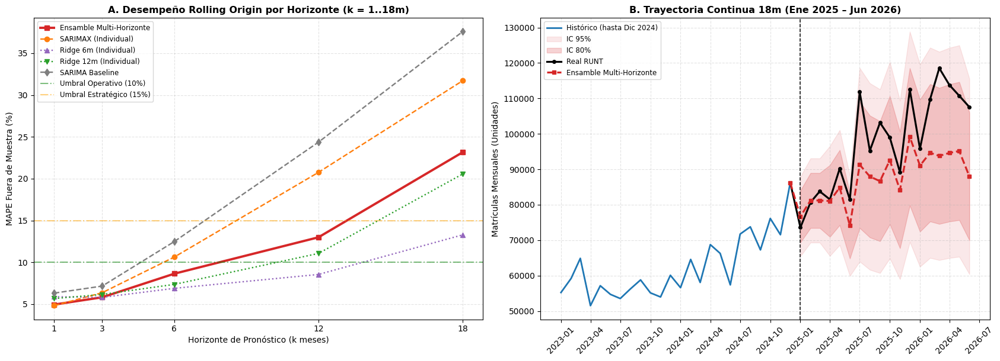

In [100]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. PREPARACIÓN DE DATOS E INGENIERÍA DE CARACTERÍSTICAS
# ==============================================================================
df_base = df_datamarket.merge(aux_real, on="Fecha", how="inner").sort_values("Fecha").reset_index(drop=True)
df_base["Var.TRM"] = df_base["Var.TRM"].fillna(0)
df_base["Var.PIB"] = df_base["Var.PIB"].fillna(0)
df_total = df_base[df_base["Fecha"] <= "2026-06-30"].copy().reset_index(drop=True)

col_remesas = "Remesas_PC" if "Remesas_PC" in df_total.columns else "Remesas"
macro_cols = [
    "TasaDesocupacion", "TRM", "Var.TRM", "TasaInteres",
    "InflacionAnual", "InflacionMensual", "ICC",
    "PIB_PC", "Var.PIB", "Exportaciones_PC", "Importaciones_PC",
    col_remesas, "SMMLV_PA"
]
exog_estadisticos_3m = [
    "DiasHabiles", "COVID", "DificultadesRUNT",
    "TasaInteres_lag3", "Var.TRM_lag3", "ICC_lag3",
    "SMMLV_PA_lag3", "Var.PIB_lag3", "TasaDesocupacion_lag3"
]

df_feat = df_total.copy()
df_feat["Mes"] = df_feat["Fecha"].dt.month
df_feat["Mes_sin"] = np.sin(2 * np.pi * df_feat["Mes"] / 12)
df_feat["Mes_cos"] = np.cos(2 * np.pi * df_feat["Mes"] / 12)

for lag in [1, 2, 3, 6, 12]:
    df_feat[f"Registros_PC_lag{lag}"] = df_feat["Registros_PC"].shift(lag)

df_feat["Delta12_Registros_PC"] = df_feat["Registros_PC"] - df_feat["Registros_PC_lag12"]
for lag in [1, 2, 3, 6, 12]:
    df_feat[f"Delta12_Reg_lag{lag}"] = df_feat["Delta12_Registros_PC"].shift(lag)

for col in macro_cols:
    df_feat[f"Diff12_{col}"] = df_feat[col] - df_feat[col].shift(12)
    df_feat[f"Diff12_{col}_lag18"] = df_feat[f"Diff12_{col}"].shift(18)
    for lag in [3, 6, 12]:
        df_feat[f"{col}_lag{lag}"] = df_feat[col].shift(lag)
        df_feat[f"Diff12_{col}_lag{lag}"] = df_feat[f"Diff12_{col}"].shift(lag)

feats_r6 = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "Delta12_Reg_lag1", "Delta12_Reg_lag2", "Delta12_Reg_lag3", "Delta12_Reg_lag12",
    "Diff12_TasaInteres_lag6", "Diff12_TasaInteres_lag12",
    "Diff12_TasaDesocupacion_lag6", "Diff12_TasaDesocupacion_lag12",
    "Diff12_ICC_lag6", "Diff12_ICC_lag12",
    "Diff12_SMMLV_PA_lag6", "Diff12_SMMLV_PA_lag12",
    "Diff12_InflacionAnual_lag6", "Diff12_InflacionAnual_lag12",
    "Diff12_PIB_PC_lag6", "Diff12_TRM_lag6", f"Diff12_{col_remesas}_lag6"
]

feats_r12 = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "Delta12_Reg_lag1", "Delta12_Reg_lag2", "Delta12_Reg_lag3", "Delta12_Reg_lag12",
    "Diff12_TasaInteres_lag12", "Diff12_TasaInteres_lag18",
    "Diff12_TasaDesocupacion_lag12", "Diff12_TasaDesocupacion_lag18",
    "Diff12_ICC_lag12", "Diff12_ICC_lag18",
    "Diff12_SMMLV_PA_lag12", "Diff12_SMMLV_PA_lag18",
    "Diff12_InflacionAnual_lag12", "Diff12_InflacionAnual_lag18",
    "Diff12_PIB_PC_lag12", "Diff12_TRM_lag12", f"Diff12_{col_remesas}_lag12"
]

def generar_pronosticos_k_pasos(df_train_sub, df_fut_sub, k):
    """Entrena los 4 especialistas hasta el origen y devuelve sus pronósticos completos de 1..k."""
    factor_fut = (df_fut_sub["PoblacionTotal"].values * 1000) / 100000
    df_clean_sar = df_train_sub.dropna(subset=["Registros_PC"] + exog_estadisticos_3m).reset_index(drop=True)

    # 1. SARIMAX (con estacionariedad e invertibilidad estrictas para estabilidad numérica)
    mod_sx = SARIMAX(
        df_clean_sar["Registros_PC"].values,
        exog=df_clean_sar[exog_estadisticos_3m].values,
        order=(1, 1, 1), seasonal_order=(1, 1, 1, 12), trend="c",
        enforce_stationarity=True, enforce_invertibility=True
    ).fit(method="powell", maxiter=150, disp=False)

    df_u_sar = pd.concat([df_train_sub.tail(15), df_fut_sub], ignore_index=True)
    df_u_sar[macro_cols] = df_u_sar[macro_cols].ffill()
    for col in macro_cols:
        df_u_sar[f"{col}_lag3"] = df_u_sar[col].shift(3)
    exog_f = df_u_sar.iloc[15:][exog_estadisticos_3m].values
    traj_sx = mod_sx.forecast(steps=k, exog=exog_f) * factor_fut

    # 2. SARIMA Baseline
    mod_sa = SARIMAX(
        df_clean_sar["Registros_PC"].values,
        order=(1, 1, 1), seasonal_order=(1, 1, 1, 12), trend="c",
        enforce_stationarity=True, enforce_invertibility=True
    ).fit(method="powell", maxiter=150, disp=False)
    traj_sa = mod_sa.forecast(steps=k) * factor_fut

    # 3. Ridge 6m y Ridge 12m
    def roll_ridge(feats_list, k_min):
        df_tr_r = df_train_sub.dropna(subset=feats_list + ["Delta12_Registros_PC"]).reset_index(drop=True)
        pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=15.0))])
        pipe.fit(df_tr_r[feats_list], df_tr_r["Delta12_Registros_PC"])

        df_u = pd.concat([df_train_sub.tail(30), df_fut_sub], ignore_index=True)
        df_u[macro_cols] = df_u[macro_cols].ffill()
        for col in macro_cols:
            diff_c = df_u[col] - df_u[col].shift(12)
            df_u[f"Diff12_{col}_lag{k_min}"] = diff_c.shift(k_min)
            df_u[f"Diff12_{col}_lag{k_min+6}"] = diff_c.shift(k_min + 6)
        df_te = df_u.iloc[30:].reset_index(drop=True)

        hist_pc  = list(df_train_sub["Registros_PC"].values)
        hist_d12 = list(df_train_sub["Delta12_Registros_PC"].dropna().values)
        preds_pc = []
        for step in range(k):
            fila = df_te.iloc[[step]][feats_list].copy()
            for lag in [1, 2, 3, 12]:
                fila[f"Delta12_Reg_lag{lag}"] = hist_d12[-lag]
            p_d12 = pipe.predict(fila)[0]
            p_pc  = hist_pc[-12] + p_d12
            preds_pc.append(p_pc)
            hist_pc.append(p_pc)
            hist_d12.append(p_d12)
        return np.array(preds_pc) * factor_fut

    traj_r6  = roll_ridge(feats_r6, 6)
    traj_r12 = roll_ridge(feats_r12, 12)

    return np.column_stack([traj_sx, traj_r6, traj_r12, traj_sa])

# ==============================================================================
# 2. CALIBRACIÓN OBJETIVA DE PESOS (INVERSE-MAPE^2 EN CV HISTÓRICA PREVIA A 2025)
# ==============================================================================
# Evaluamos 12 cortes históricos previos al corte OOS (targets: Ene 2024 – Dic 2024)
idx_val_ini = df_feat.index[df_feat["Fecha"] == "2024-01-01"][0]
idx_val_fin = df_feat.index[df_feat["Fecha"] == "2024-12-01"][0]

pesos_aprendidos_k = {}
print("Calibrando pesos objetivos (Inverse-MAPE^2) en ventana histórica 2024...", flush=True)

for k in [1, 3, 6, 12, 18]:
    errs = []
    for t_idx in range(idx_val_ini, idx_val_fin + 1):
        o_idx = t_idx - k
        M_k = generar_pronosticos_k_pasos(
            df_feat.iloc[:o_idx + 1].reset_index(drop=True),
            df_feat.iloc[o_idx + 1 : t_idx + 1].reset_index(drop=True),
            k
        )
        y_t = df_feat.loc[t_idx, "Registros"]
        errs.append(np.abs((y_t - M_k[-1]) / y_t))
    mapes_hist = np.mean(errs, axis=0)
    inv_sq = (1.0 / np.maximum(mapes_hist, 1e-4)) ** 2
    w_k = np.round(inv_sq / np.sum(inv_sq), 3)
    w_k[-1] = np.round(1.0 - np.sum(w_k[:-1]), 3)  # Ajuste exacto a suma 1.0
    pesos_aprendidos_k[k] = w_k
    print(f"  Horizonte k={k:2d}m -> Pesos [SARIMAX, Ridge6m, Ridge12m, SARIMA]: {w_k}", flush=True)

# ==============================================================================
# 3. EVALUACIÓN A: ROLLING ORIGIN POR HORIZONTE (ENE 2025 – JUN 2026)
# ==============================================================================
idx_oos_ini = df_feat.index[df_feat["Fecha"] == "2025-01-01"][0]
idx_oos_fin = len(df_feat) - 1  # Jun 2026 (18 cortes)

resultados_rolling = []
for k in [1, 3, 6, 12, 18]:
    y_true_list = []
    preds_mat = []
    for t_idx in range(idx_oos_ini, idx_oos_fin + 1):
        o_idx = t_idx - k
        M_k = generar_pronosticos_k_pasos(
            df_feat.iloc[:o_idx + 1].reset_index(drop=True),
            df_feat.iloc[o_idx + 1 : t_idx + 1].reset_index(drop=True),
            k
        )
        y_true_list.append(df_feat.loc[t_idx, "Registros"])
        preds_mat.append(M_k[-1])

    y_arr = np.array(y_true_list)
    preds_mat = np.array(preds_mat)
    p_ens = preds_mat @ pesos_aprendidos_k[k]

    for nombre, p_vec in [
        ("Ensamble Multi-Horizonte", p_ens),
        ("SARIMAX (Individual)",     preds_mat[:, 0]),
        ("Ridge 6m (Individual)",    preds_mat[:, 1]),
        ("Ridge 12m (Individual)",   preds_mat[:, 2]),
        ("SARIMA Baseline",          preds_mat[:, 3])
    ]:
        resultados_rolling.append({
            "Horizonte (k)": f"{k}m",
            "Modelo": nombre,
            "MAPE (%)": round(np.mean(np.abs((y_arr - p_vec) / y_arr)) * 100, 2),
            "MAE": int(round(mean_absolute_error(y_arr, p_vec), 0)),
            "RMSE": int(round(np.sqrt(mean_squared_error(y_arr, p_vec)), 0)),
            "R2": round(r2_score(y_arr, p_vec), 3)
        })

df_res_rolling = pd.DataFrame(resultados_rolling)
print("\n=== EVALUACIÓN A: ROLLING ORIGIN POR HORIZONTE (ENE 2025 – JUN 2026) ===", flush=True)
for k in [1, 3, 6, 12, 18]:
    print(f"\n--- Horizonte k = {k} meses ---")
    print(df_res_rolling[df_res_rolling["Horizonte (k)"] == f"{k}m"].sort_values("MAPE (%)").to_string(index=False))

# ==============================================================================
# 4. EVALUACIÓN B: BACKTESTING TRAYECTORIA CONTINUA (ENE 2025 – JUN 2026)
# ==============================================================================
corte_idx = df_feat.index[df_feat["Fecha"] == "2024-12-01"][0]
df_tr_bt  = df_feat.iloc[:corte_idx + 1].reset_index(drop=True)
df_te_bt  = df_feat.iloc[corte_idx + 1:].reset_index(drop=True)

M_bt = generar_pronosticos_k_pasos(df_tr_bt, df_te_bt, 18)
y_bt = df_te_bt["Registros"].values

# Asignar los pesos calibrados según el paso del horizonte (1..18)
W_bt = np.vstack([
    np.tile(pesos_aprendidos_k[1],  (2, 1)),  # pasos 1-2
    np.tile(pesos_aprendidos_k[3],  (2, 1)),  # pasos 3-4
    np.tile(pesos_aprendidos_k[6],  (4, 1)),  # pasos 5-8
    np.tile(pesos_aprendidos_k[12], (6, 1)),  # pasos 9-14
    np.tile(pesos_aprendidos_k[18], (4, 1)),  # pasos 15-18
])
pron_bt = np.sum(M_bt * W_bt, axis=1)

# Bandas de Incertidumbre Empíricas
sigma_rel = np.array([0.0597 * 1.25]*3 + [0.0780 * 1.25]*3 + [0.1221 * 1.25]*6 + [0.1279 * 1.25]*6)
sigma_u   = pron_bt * sigma_rel
ic80_inf, ic80_sup = pron_bt - 1.28 * sigma_u, pron_bt + 1.28 * sigma_u
ic95_inf, ic95_sup = pron_bt - 1.96 * sigma_u, pron_bt + 1.96 * sigma_u

df_bt_res = pd.DataFrame([
    {"Modelo": "Ensamble Multi-Horizonte", "MAPE (%)": round(np.mean(np.abs((y_bt - pron_bt)/y_bt))*100, 2), "MAE": int(round(mean_absolute_error(y_bt, pron_bt), 0)), "RMSE": int(round(np.sqrt(mean_squared_error(y_bt, pron_bt)), 0)), "R2 OOS": round(r2_score(y_bt, pron_bt), 3)},
    {"Modelo": "SARIMAX (Individual)",     "MAPE (%)": round(np.mean(np.abs((y_bt - M_bt[:,0])/y_bt))*100, 2), "MAE": int(round(mean_absolute_error(y_bt, M_bt[:,0]), 0)), "RMSE": int(round(np.sqrt(mean_squared_error(y_bt, M_bt[:,0])), 0)), "R2 OOS": round(r2_score(y_bt, M_bt[:,0]), 3)},
    {"Modelo": "Ridge 6m (Individual)",    "MAPE (%)": round(np.mean(np.abs((y_bt - M_bt[:,1])/y_bt))*100, 2), "MAE": int(round(mean_absolute_error(y_bt, M_bt[:,1]), 0)), "RMSE": int(round(np.sqrt(mean_squared_error(y_bt, M_bt[:,1])), 0)), "R2 OOS": round(r2_score(y_bt, M_bt[:,1]), 3)},
    {"Modelo": "Ridge 12m (Individual)",   "MAPE (%)": round(np.mean(np.abs((y_bt - M_bt[:,2])/y_bt))*100, 2), "MAE": int(round(mean_absolute_error(y_bt, M_bt[:,2]), 0)), "RMSE": int(round(np.sqrt(mean_squared_error(y_bt, M_bt[:,2])), 0)), "R2 OOS": round(r2_score(y_bt, M_bt[:,2]), 3)},
    {"Modelo": "SARIMA Baseline",          "MAPE (%)": round(np.mean(np.abs((y_bt - M_bt[:,3])/y_bt))*100, 2), "MAE": int(round(mean_absolute_error(y_bt, M_bt[:,3]), 0)), "RMSE": int(round(np.sqrt(mean_squared_error(y_bt, M_bt[:,3])), 0)), "R2 OOS": round(r2_score(y_bt, M_bt[:,3]), 3)},
]).sort_values("MAPE (%)").reset_index(drop=True)

print("\n=== EVALUACIÓN B: BACKTESTING TRAYECTORIA CONTINUA 18M (ENE 2025 – JUN 2026) ===", flush=True)
print(df_bt_res.to_string(index=False))
print(f"Cobertura IC 80%: {np.mean((y_bt >= ic80_inf) & (y_bt <= ic80_sup))*100:.1f}% | Cobertura IC 95%: {np.mean((y_bt >= ic95_inf) & (y_bt <= ic95_sup))*100:.1f}%", flush=True)

# ==============================================================================
# 5. GRÁFICAS CONJUNTAS (ROLLING POR HORIZONTE + TRAYECTORIA 18M)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(17, 6.2))

# Panel 1: MAPE Rolling Origin por Horizonte
horizontes_num = [1, 3, 6, 12, 18]
estilos = {
    "Ensamble Multi-Horizonte": ("#d62728", "-",  "s", 2.8),
    "SARIMAX (Individual)":     ("#ff7f0e", "--", "o", 1.7),
    "Ridge 6m (Individual)":    ("#9467bd", ":",  "^", 1.7),
    "Ridge 12m (Individual)":   ("#2ca02c", ":",  "v", 1.7),
    "SARIMA Baseline":          ("#7f7f7f", "--", "d", 1.7),
}
for mod, (col, ls, mk, lw) in estilos.items():
    mapes = [df_res_rolling[(df_res_rolling["Horizonte (k)"] == f"{k}m") & (df_res_rolling["Modelo"] == mod)]["MAPE (%)"].values[0] for k in horizontes_num]
    axes[0].plot(horizontes_num, mapes, color=col, linestyle=ls, marker=mk, linewidth=lw, markersize=6, label=mod)
axes[0].axhline(10.0, color="green", linestyle="-.", alpha=0.5, label="Umbral Operativo (10%)")
axes[0].axhline(15.0, color="orange", linestyle="-.", alpha=0.5, label="Umbral Estratégico (15%)")
axes[0].set_title("A. Desempeño Rolling Origin por Horizonte (k = 1..18m)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Horizonte de Pronóstico (k meses)")
axes[0].set_ylabel("MAPE Fuera de Muestra (%)")
axes[0].set_xticks(horizontes_num)
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend(loc="upper left", fontsize=8.5, frameon=True)

# Panel 2: Trayectoria Continua Backtesting 18m
hist_plot = df_tr_bt[df_tr_bt["Fecha"] >= "2023-01-01"]
fechas_te = df_te_bt["Fecha"]
fechas_cn = [hist_plot["Fecha"].iloc[-1]] + list(fechas_te)
u_tr = hist_plot["Registros"].iloc[-1]

axes[1].plot(hist_plot["Fecha"], hist_plot["Registros"], color="#1f77b4", linewidth=2.0, label="Histórico (hasta Dic 2024)")
axes[1].fill_between(fechas_te, ic95_inf, ic95_sup, color="#d62728", alpha=0.10, label="IC 95%")
axes[1].fill_between(fechas_te, ic80_inf, ic80_sup, color="#d62728", alpha=0.20, label="IC 80%")
axes[1].plot(fechas_cn, [u_tr] + list(y_bt),    color="black",   linewidth=2.3, marker="o", markersize=4, label="Real RUNT")
axes[1].plot(fechas_cn, [u_tr] + list(pron_bt), color="#d62728", linestyle="--", linewidth=2.3, marker="s", markersize=4, label="Ensamble Multi-Horizonte")
axes[1].axvline(pd.Timestamp("2024-12-31"), color="black", linestyle="--", linewidth=1.1)
axes[1].set_title("B. Trayectoria Continua 18m (Ene 2025 – Jun 2026)", fontsize=11.5, fontweight="bold")
axes[1].set_ylabel("Matrículas Mensuales (Unidades)")
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(True, linestyle="--", alpha=0.35)
axes[1].legend(loc="upper left", fontsize=8.5, frameon=True)

plt.tight_layout()
plt.show()

In [77]:
df_tabla_detalle = pd.DataFrame({
    "Fecha": df_te_bt["Fecha"].dt.strftime("%Y-%m"),
    "Real_RUNT": np.round(y_bt, 0).astype(int),
    "Ensamble": np.round(pron_bt, 0).astype(int),
    "Error_Abs": np.round(np.abs(y_bt - pron_bt), 0).astype(int),
    "APE (%)": np.round(np.abs((y_bt - pron_bt) / y_bt) * 100, 2),
    "IC80_Inf": np.round(ic80_inf, 0).astype(int),
    "IC80_Sup": np.round(ic80_sup, 0).astype(int),
    "IC95_Inf": np.round(ic95_inf, 0).astype(int),
    "IC95_Sup": np.round(ic95_sup, 0).astype(int),
})

print("=== DETALLE MENSUAL DE VALIDACIÓN OOS (ENERO 2025 – JUNIO 2026) ===")
print(df_tabla_detalle.to_string(index=False))

=== DETALLE MENSUAL DE VALIDACIÓN OOS (ENERO 2025 – JUNIO 2026) ===
  Fecha  Real_RUNT  Ensamble  Error_Abs  APE (%)  IC80_Inf  IC80_Sup  IC95_Inf  IC95_Sup
2025-01      73578     76698       3120     4.24     69372     84025     65480     87917
2025-02      80704     81208        504     0.62     73451     88965     69330     93086
2025-03      83772     81203       2569     3.07     73447     88960     69326     93080
2025-04      81509     81059        450     0.55     70943     91176     65569     96550
2025-05      90212     84860       5352     5.93     74270     95451     68643    101077
2025-06      81477     74070       7407     9.09     64826     83314     59915     88224
2025-07     111861     91283      20578    18.40     73450    109116     63976    118590
2025-08      95242     87974       7268     7.63     70788    105161     61657    114292
2025-09     103166     86648      16518    16.01     69720    103576     60728    112568
2025-10      98990     92585       6405   

=== PRUEBA 2: 2 VENTANAS EXACTAS DE 18M (36 MESES OOS, JUL 2023 – JUN 2026) ===
                  Modelo  MAPE (%)   MAE  RMSE  R2 Global OOS
                Ridge 6m      9.74  7863  9994          0.757
Ensamble Multi-Horizonte     11.18  9449 11804          0.661
                 SARIMAX     12.75 11354 14486          0.489
               Ridge 12m     13.88 10760 13051          0.585
       SARIMA (Baseline)     14.95 13186 16530          0.334


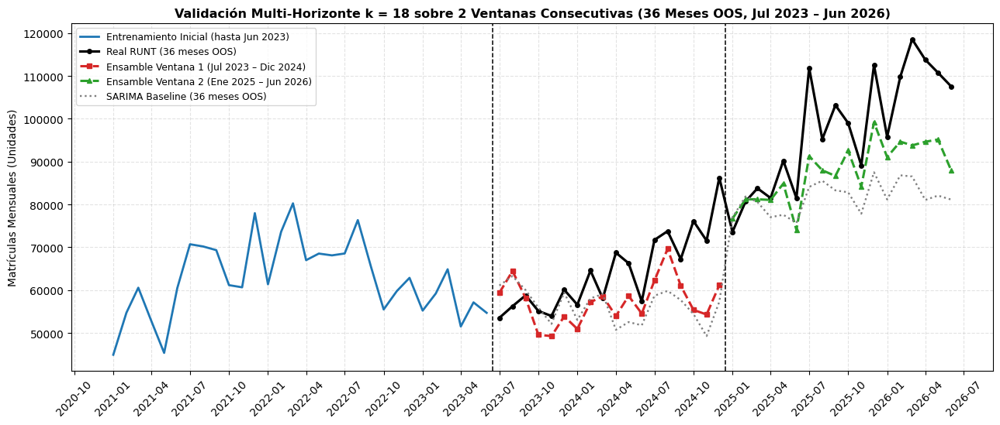

In [79]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. PREPARACIÓN DE DATOS E INGENIERÍA DE CARACTERÍSTICAS (ESPECIFICACIÓN FINAL)
# ==============================================================================
df_base = df_datamarket.merge(aux_real, on="Fecha", how="inner").sort_values("Fecha").reset_index(drop=True)
df_base["Var.TRM"] = df_base["Var.TRM"].fillna(0)
df_base["Var.PIB"] = df_base["Var.PIB"].fillna(0)
df_total = df_base[df_base["Fecha"] <= "2026-06-30"].copy().reset_index(drop=True)

col_remesas = "Remesas_PC" if "Remesas_PC" in df_total.columns else "Remesas"
macro_cols = [
    "TasaDesocupacion", "TRM", "Var.TRM", "TasaInteres",
    "InflacionAnual", "InflacionMensual", "ICC",
    "PIB_PC", "Var.PIB", "Exportaciones_PC", "Importaciones_PC",
    col_remesas, "SMMLV_PA"
]
exog_estadisticos_3m = [
    "DiasHabiles", "COVID", "DificultadesRUNT",
    "TasaInteres_lag3", "Var.TRM_lag3", "ICC_lag3",
    "SMMLV_PA_lag3", "Var.PIB_lag3", "TasaDesocupacion_lag3"
]

df_feat = df_total.copy()
df_feat["Mes"] = df_feat["Fecha"].dt.month
df_feat["Mes_sin"] = np.sin(2 * np.pi * df_feat["Mes"] / 12)
df_feat["Mes_cos"] = np.cos(2 * np.pi * df_feat["Mes"] / 12)

for lag in [1, 2, 3, 6, 12]:
    df_feat[f"Registros_PC_lag{lag}"] = df_feat["Registros_PC"].shift(lag)

df_feat["Delta12_Registros_PC"] = df_feat["Registros_PC"] - df_feat["Registros_PC_lag12"]
for lag in [1, 2, 3, 6, 12]:
    df_feat[f"Delta12_Reg_lag{lag}"] = df_feat["Delta12_Registros_PC"].shift(lag)

for col in macro_cols:
    df_feat[f"Diff12_{col}"] = df_feat[col] - df_feat[col].shift(12)
    df_feat[f"Diff12_{col}_lag18"] = df_feat[f"Diff12_{col}"].shift(18)
    for lag in [3, 6, 12]:
        df_feat[f"{col}_lag{lag}"] = df_feat[col].shift(lag)
        df_feat[f"Diff12_{col}_lag{lag}"] = df_feat[f"Diff12_{col}"].shift(lag)

feats_r6 = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "Delta12_Reg_lag1", "Delta12_Reg_lag2", "Delta12_Reg_lag3", "Delta12_Reg_lag12",
    "Diff12_TasaInteres_lag6", "Diff12_TasaInteres_lag12",
    "Diff12_TasaDesocupacion_lag6", "Diff12_TasaDesocupacion_lag12",
    "Diff12_ICC_lag6", "Diff12_ICC_lag12",
    "Diff12_SMMLV_PA_lag6", "Diff12_SMMLV_PA_lag12",
    "Diff12_InflacionAnual_lag6", "Diff12_InflacionAnual_lag12",
    "Diff12_PIB_PC_lag6", "Diff12_TRM_lag6", f"Diff12_{col_remesas}_lag6"
]

feats_r12 = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "Delta12_Reg_lag1", "Delta12_Reg_lag2", "Delta12_Reg_lag3", "Delta12_Reg_lag12",
    "Diff12_TasaInteres_lag12", "Diff12_TasaInteres_lag18",
    "Diff12_TasaDesocupacion_lag12", "Diff12_TasaDesocupacion_lag18",
    "Diff12_ICC_lag12", "Diff12_ICC_lag18",
    "Diff12_SMMLV_PA_lag12", "Diff12_SMMLV_PA_lag18",
    "Diff12_InflacionAnual_lag12", "Diff12_InflacionAnual_lag18",
    "Diff12_PIB_PC_lag12", "Diff12_TRM_lag12", f"Diff12_{col_remesas}_lag12"
]

def generar_pronosticos_k_pasos(df_train_sub, df_fut_sub, k):
    """Especificación definitiva (enforce_stationarity=True, enforce_invertibility=True)."""
    factor_fut = (df_fut_sub["PoblacionTotal"].values * 1000) / 100000
    df_clean_sar = df_train_sub.dropna(subset=["Registros_PC"] + exog_estadisticos_3m).reset_index(drop=True)

    # 1. SARIMAX
    mod_sx = SARIMAX(
        df_clean_sar["Registros_PC"].values,
        exog=df_clean_sar[exog_estadisticos_3m].values,
        order=(1, 1, 1), seasonal_order=(1, 1, 1, 12), trend="c",
        enforce_stationarity=True, enforce_invertibility=True
    ).fit(method="powell", maxiter=150, disp=False)

    df_u_sar = pd.concat([df_train_sub.tail(15), df_fut_sub], ignore_index=True)
    df_u_sar[macro_cols] = df_u_sar[macro_cols].ffill()
    for col in macro_cols:
        df_u_sar[f"{col}_lag3"] = df_u_sar[col].shift(3)
    exog_f = df_u_sar.iloc[15:][exog_estadisticos_3m].values
    traj_sx = mod_sx.forecast(steps=k, exog=exog_f) * factor_fut

    # 2. SARIMA Baseline
    mod_sa = SARIMAX(
        df_clean_sar["Registros_PC"].values,
        order=(1, 1, 1), seasonal_order=(1, 1, 1, 12), trend="c",
        enforce_stationarity=True, enforce_invertibility=True
    ).fit(method="powell", maxiter=150, disp=False)
    traj_sa = mod_sa.forecast(steps=k) * factor_fut

    # 3. Ridge 6m y Ridge 12m
    def roll_ridge(feats_list, k_min):
        df_tr_r = df_train_sub.dropna(subset=feats_list + ["Delta12_Registros_PC"]).reset_index(drop=True)
        pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=15.0))])
        pipe.fit(df_tr_r[feats_list], df_tr_r["Delta12_Registros_PC"])

        df_u = pd.concat([df_train_sub.tail(30), df_fut_sub], ignore_index=True)
        df_u[macro_cols] = df_u[macro_cols].ffill()
        for col in macro_cols:
            diff_c = df_u[col] - df_u[col].shift(12)
            df_u[f"Diff12_{col}_lag{k_min}"] = diff_c.shift(k_min)
            df_u[f"Diff12_{col}_lag{k_min+6}"] = diff_c.shift(k_min + 6)
        df_te = df_u.iloc[30:].reset_index(drop=True)

        hist_pc  = list(df_train_sub["Registros_PC"].values)
        hist_d12 = list(df_train_sub["Delta12_Registros_PC"].dropna().values)
        preds_pc = []
        for step in range(k):
            fila = df_te.iloc[[step]][feats_list].copy()
            for lag in [1, 2, 3, 12]:
                fila[f"Delta12_Reg_lag{lag}"] = hist_d12[-lag]
            p_d12 = pipe.predict(fila)[0]
            p_pc  = hist_pc[-12] + p_d12
            preds_pc.append(p_pc)
            hist_pc.append(p_pc)
            hist_d12.append(p_d12)
        return np.array(preds_pc) * factor_fut

    traj_r6  = roll_ridge(feats_r6, 6)
    traj_r12 = roll_ridge(feats_r12, 12)

    return np.column_stack([traj_sx, traj_r6, traj_r12, traj_sa])

# ==============================================================================
# 2. PESOS INVERSE-MAPE^2 DEL MODELO DEFINITIVO (CALIBRADOS EN 2024)
# ==============================================================================
pesos_definitivos_k = {
    1:  np.array([0.487, 0.194, 0.164, 0.155]),
    3:  np.array([0.386, 0.329, 0.121, 0.164]),
    6:  np.array([0.281, 0.468, 0.104, 0.147]),
    12: np.array([0.182, 0.576, 0.107, 0.135]),
    18: np.array([0.188, 0.431, 0.167, 0.214]),
}

W_18 = np.vstack([
    np.tile(pesos_definitivos_k[1],  (2, 1)),  # pasos 1-2
    np.tile(pesos_definitivos_k[3],  (2, 1)),  # pasos 3-4
    np.tile(pesos_definitivos_k[6],  (4, 1)),  # pasos 5-8
    np.tile(pesos_definitivos_k[12], (6, 1)),  # pasos 9-14
    np.tile(pesos_definitivos_k[18], (4, 1)),  # pasos 15-18
])

# ==============================================================================
# 3. PRUEBA 2: EVALUACIÓN SOBRE LAS 2 VENTANAS EXACTAS DE 18M (36 MESES OOS)
#    Ventana 1: Jul 2023 – Dic 2024 (corte Jun 2023)
#    Ventana 2: Ene 2025 – Jun 2026 (corte Dic 2024)
# ==============================================================================
cortes_36m = ["2023-06-01", "2024-12-01"]
y_all_36, M_all_36, ens_all_36, fechas_all_36 = [], [], [], []

for fecha_corte in cortes_36m:
    c_idx = df_feat.index[df_feat["Fecha"] == fecha_corte][0]
    df_tr = df_feat.iloc[:c_idx + 1].reset_index(drop=True)
    df_te = df_feat.iloc[c_idx + 1 : c_idx + 19].reset_index(drop=True)

    M_win   = generar_pronosticos_k_pasos(df_tr, df_te, 18)
    ens_win = np.sum(M_win * W_18, axis=1)

    y_all_36.append(df_te["Registros"].values)
    M_all_36.append(M_win)
    ens_all_36.append(ens_win)
    fechas_all_36.append(df_te["Fecha"].values)

y_36   = np.concatenate(y_all_36)
M_36   = np.vstack(M_all_36)
ens_36 = np.concatenate(ens_all_36)
fec_36 = np.concatenate(fechas_all_36)

tabla_36m = pd.DataFrame([
    {"Modelo": "Ensamble Multi-Horizonte", "MAPE (%)": round(np.mean(np.abs((y_36 - ens_36)/y_36))*100, 2), "MAE": int(round(mean_absolute_error(y_36, ens_36), 0)), "RMSE": int(round(np.sqrt(mean_squared_error(y_36, ens_36)), 0)), "R2 Global OOS": round(r2_score(y_36, ens_36), 3)},
    {"Modelo": "Ridge 6m",                 "MAPE (%)": round(np.mean(np.abs((y_36 - M_36[:,1])/y_36))*100, 2), "MAE": int(round(mean_absolute_error(y_36, M_36[:,1]), 0)), "RMSE": int(round(np.sqrt(mean_squared_error(y_36, M_36[:,1])), 0)), "R2 Global OOS": round(r2_score(y_36, M_36[:,1]), 3)},
    {"Modelo": "Ridge 12m",                "MAPE (%)": round(np.mean(np.abs((y_36 - M_36[:,2])/y_36))*100, 2), "MAE": int(round(mean_absolute_error(y_36, M_36[:,2]), 0)), "RMSE": int(round(np.sqrt(mean_squared_error(y_36, M_36[:,2])), 0)), "R2 Global OOS": round(r2_score(y_36, M_36[:,2]), 3)},
    {"Modelo": "SARIMAX",                  "MAPE (%)": round(np.mean(np.abs((y_36 - M_36[:,0])/y_36))*100, 2), "MAE": int(round(mean_absolute_error(y_36, M_36[:,0]), 0)), "RMSE": int(round(np.sqrt(mean_squared_error(y_36, M_36[:,0])), 0)), "R2 Global OOS": round(r2_score(y_36, M_36[:,0]), 3)},
    {"Modelo": "SARIMA (Baseline)",        "MAPE (%)": round(np.mean(np.abs((y_36 - M_36[:,3])/y_36))*100, 2), "MAE": int(round(mean_absolute_error(y_36, M_36[:,3]), 0)), "RMSE": int(round(np.sqrt(mean_squared_error(y_36, M_36[:,3])), 0)), "R2 Global OOS": round(r2_score(y_36, M_36[:,3]), 3)},
]).sort_values("MAPE (%)").reset_index(drop=True)

print("=== PRUEBA 2: 2 VENTANAS EXACTAS DE 18M (36 MESES OOS, JUL 2023 – JUN 2026) ===", flush=True)
print(tabla_36m.to_string(index=False))

# Gráfica de las 2 ventanas bajo la especificación definitiva
fig, ax = plt.subplots(figsize=(13, 5.6))
hist_ini = df_feat[(df_feat["Fecha"] >= "2021-01-01") & (df_feat["Fecha"] <= "2023-06-01")]

ax.plot(hist_ini["Fecha"], hist_ini["Registros"], color="#1f77b4", linewidth=2.0, label="Entrenamiento Inicial (hasta Jun 2023)")
ax.plot(fec_36, y_36, color="black", linewidth=2.3, marker="o", markersize=4, label="Real RUNT (36 meses OOS)")
ax.plot(fec_36[:18], ens_36[:18], color="#d62728", linestyle="--", linewidth=2.2, marker="s", markersize=4, label="Ensamble Ventana 1 (Jul 2023 – Dic 2024)")
ax.plot(fec_36[18:], ens_36[18:], color="#2ca02c", linestyle="--", linewidth=2.2, marker="^", markersize=4, label="Ensamble Ventana 2 (Ene 2025 – Jun 2026)")
ax.plot(fec_36, M_36[:, 3], color="#7f7f7f", linestyle=":", linewidth=1.7, label="SARIMA Baseline (36 meses OOS)")

ax.axvline(pd.Timestamp("2023-06-15"), color="black", linestyle="--", linewidth=1.1)
ax.axvline(pd.Timestamp("2024-12-15"), color="black", linestyle="--", linewidth=1.1)
ax.set_title("Validación Multi-Horizonte k = 18 sobre 2 Ventanas Consecutivas (36 Meses OOS, Jul 2023 – Jun 2026)", fontsize=11.5, fontweight="bold")
ax.set_ylabel("Matrículas Mensuales (Unidades)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.tick_params(axis="x", rotation=45)
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", fontsize=8.8, frameon=True)
plt.tight_layout()
plt.show()

## Resultado - Modelo Final

Calibrando pesos objetivos (Inverse-MAPE^2) en ventana Jul 2025 – Jun 2026...
  Horizonte k= 1m -> Pesos [SARIMAX, Ridge6m, Ridge12m, SARIMA]: [0.331 0.232 0.253 0.184]
  Horizonte k= 3m -> Pesos [SARIMAX, Ridge6m, Ridge12m, SARIMA]: [0.251 0.262 0.263 0.224]
  Horizonte k= 6m -> Pesos [SARIMAX, Ridge6m, Ridge12m, SARIMA]: [0.163 0.332 0.37  0.135]
  Horizonte k=12m -> Pesos [SARIMAX, Ridge6m, Ridge12m, SARIMA]: [0.086 0.416 0.429 0.069]
  Horizonte k=18m -> Pesos [SARIMAX, Ridge6m, Ridge12m, SARIMA]: [0.096 0.488 0.343 0.073]

=== PROYECCIÓN MENSUAL DE MATRÍCULAS (JULIO 2026 – DICIEMBRE 2027) ===
     Fecha  Escenario_Pesimista  Escenario_Base  Escenario_Optimista  IC80_Inf_Base  IC80_Sup_Base  IC95_Inf_Base  IC95_Sup_Base  Base_SARIMAX  Base_Ridge6m  Base_Ridge12m  Base_SARIMA
2026-07-01               125838          125838               125838         113818         137858         107432         144243        111638        146079         129174       121273
2026-08-01               

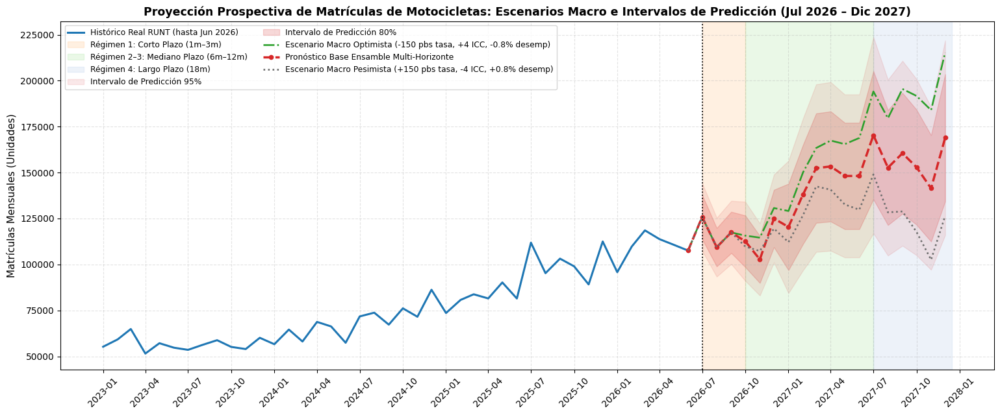


Archivo exportado: 'Proyeccion_Motos_Jul2026_Dic2027.xlsx'


In [109]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. PREPARACIÓN DE DATOS E INGENIERÍA DE CARACTERÍSTICAS (HASTA JUNIO 2026)
# ==============================================================================
df_base = df_datamarket.merge(aux_real, on="Fecha", how="inner").sort_values("Fecha").reset_index(drop=True)
df_base["Var.TRM"] = df_base["Var.TRM"].fillna(0)
df_base["Var.PIB"] = df_base["Var.PIB"].fillna(0)

# Datos históricos reales hasta junio 2026
df_total = df_base[df_base["Fecha"] <= "2026-06-30"].copy().reset_index(drop=True)

col_remesas = "Remesas_PC" if "Remesas_PC" in df_total.columns else "Remesas"
macro_cols = [
    "TasaDesocupacion", "TRM", "Var.TRM", "TasaInteres",
    "InflacionAnual", "InflacionMensual", "ICC",
    "PIB_PC", "Var.PIB", "Exportaciones_PC", "Importaciones_PC",
    col_remesas, "SMMLV_PA"
]
exog_estadisticos_3m = [
    "DiasHabiles", "COVID", "DificultadesRUNT",
    "TasaInteres_lag3", "Var.TRM_lag3", "ICC_lag3",
    "SMMLV_PA_lag3", "Var.PIB_lag3", "TasaDesocupacion_lag3"
]

df_feat = df_total.copy()
df_feat["Mes"] = df_feat["Fecha"].dt.month
df_feat["Mes_sin"] = np.sin(2 * np.pi * df_feat["Mes"] / 12)
df_feat["Mes_cos"] = np.cos(2 * np.pi * df_feat["Mes"] / 12)

for lag in [1, 2, 3, 6, 12]:
    df_feat[f"Registros_PC_lag{lag}"] = df_feat["Registros_PC"].shift(lag)

df_feat["Delta12_Registros_PC"] = df_feat["Registros_PC"] - df_feat["Registros_PC_lag12"]
for lag in [1, 2, 3, 6, 12]:
    df_feat[f"Delta12_Reg_lag{lag}"] = df_feat["Delta12_Registros_PC"].shift(lag)

for col in macro_cols:
    df_feat[f"Diff12_{col}"] = df_feat[col] - df_feat[col].shift(12)
    df_feat[f"Diff12_{col}_lag18"] = df_feat[f"Diff12_{col}"].shift(18)
    for lag in [3, 6, 12]:
        df_feat[f"{col}_lag{lag}"] = df_feat[col].shift(lag)
        df_feat[f"Diff12_{col}_lag{lag}"] = df_feat[f"Diff12_{col}"].shift(lag)

feats_r6 = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "Delta12_Reg_lag1", "Delta12_Reg_lag2", "Delta12_Reg_lag3", "Delta12_Reg_lag12",
    "Diff12_TasaInteres_lag6", "Diff12_TasaInteres_lag12",
    "Diff12_TasaDesocupacion_lag6", "Diff12_TasaDesocupacion_lag12",
    "Diff12_ICC_lag6", "Diff12_ICC_lag12",
    "Diff12_SMMLV_PA_lag6", "Diff12_SMMLV_PA_lag12",
    "Diff12_InflacionAnual_lag6", "Diff12_InflacionAnual_lag12",
    "Diff12_PIB_PC_lag6", "Diff12_TRM_lag6", f"Diff12_{col_remesas}_lag6"
]

feats_r12 = [
    "DiasHabiles", "COVID", "DificultadesRUNT", "Mes_sin", "Mes_cos",
    "Delta12_Reg_lag1", "Delta12_Reg_lag2", "Delta12_Reg_lag3", "Delta12_Reg_lag12",
    "Diff12_TasaInteres_lag12", "Diff12_TasaInteres_lag18",
    "Diff12_TasaDesocupacion_lag12", "Diff12_TasaDesocupacion_lag18",
    "Diff12_ICC_lag12", "Diff12_ICC_lag18",
    "Diff12_SMMLV_PA_lag12", "Diff12_SMMLV_PA_lag18",
    "Diff12_InflacionAnual_lag12", "Diff12_InflacionAnual_lag18",
    "Diff12_PIB_PC_lag12", "Diff12_TRM_lag12", f"Diff12_{col_remesas}_lag12"
]

def generar_pronosticos_k_pasos(df_train_sub, df_fut_sub, k):
    """Exactamente la misma función de los 4 especialistas del modelo validado."""
    factor_fut = (df_fut_sub["PoblacionTotal"].values * 1000) / 100000
    df_clean_sar = df_train_sub.dropna(subset=["Registros_PC"] + exog_estadisticos_3m).reset_index(drop=True)

    # 1. SARIMAX
    mod_sx = SARIMAX(
        df_clean_sar["Registros_PC"].values,
        exog=df_clean_sar[exog_estadisticos_3m].values,
        order=(1, 1, 1), seasonal_order=(1, 1, 1, 12), trend="c",
        enforce_stationarity=True, enforce_invertibility=True
    ).fit(method="powell", maxiter=150, disp=False)

    df_u_sar = pd.concat([df_train_sub.tail(15), df_fut_sub], ignore_index=True)
    df_u_sar[macro_cols] = df_u_sar[macro_cols].ffill()
    for col in macro_cols:
        df_u_sar[f"{col}_lag3"] = df_u_sar[col].shift(3)
    exog_f = df_u_sar.iloc[15:][exog_estadisticos_3m].values
    traj_sx = mod_sx.forecast(steps=k, exog=exog_f) * factor_fut

    # 2. SARIMA Baseline
    mod_sa = SARIMAX(
        df_clean_sar["Registros_PC"].values,
        order=(1, 1, 1), seasonal_order=(1, 1, 1, 12), trend="c",
        enforce_stationarity=True, enforce_invertibility=True
    ).fit(method="powell", maxiter=150, disp=False)
    traj_sa = mod_sa.forecast(steps=k) * factor_fut

    # 3. Ridge 6m y Ridge 12m
    def roll_ridge(feats_list, k_min):
        df_tr_r = df_train_sub.dropna(subset=feats_list + ["Delta12_Registros_PC"]).reset_index(drop=True)
        pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=15.0))])
        pipe.fit(df_tr_r[feats_list], df_tr_r["Delta12_Registros_PC"])

        df_u = pd.concat([df_train_sub.tail(30), df_fut_sub], ignore_index=True)
        df_u[macro_cols] = df_u[macro_cols].ffill()
        for col in macro_cols:
            diff_c = df_u[col] - df_u[col].shift(12)
            df_u[f"Diff12_{col}_lag{k_min}"] = diff_c.shift(k_min)
            df_u[f"Diff12_{col}_lag{k_min+6}"] = diff_c.shift(k_min + 6)
        df_te = df_u.iloc[30:].reset_index(drop=True)

        hist_pc  = list(df_train_sub["Registros_PC"].values)
        hist_d12 = list(df_train_sub["Delta12_Registros_PC"].dropna().values)
        preds_pc = []
        for step in range(k):
            fila = df_te.iloc[[step]][feats_list].copy()
            for lag in [1, 2, 3, 12]:
                fila[f"Delta12_Reg_lag{lag}"] = hist_d12[-lag]
            p_d12 = pipe.predict(fila)[0]
            p_pc  = hist_pc[-12] + p_d12
            preds_pc.append(p_pc)
            hist_pc.append(p_pc)
            hist_d12.append(p_d12)
        return np.array(preds_pc) * factor_fut

    traj_r6  = roll_ridge(feats_r6, 6)
    traj_r12 = roll_ridge(feats_r12, 12)

    return np.column_stack([traj_sx, traj_r6, traj_r12, traj_sa])

# ==============================================================================
# 2. CALIBRACIÓN DE PESOS (INVERSE-MAPE^2 SOBRE ÚLTIMOS 12M: JUL 2025 – JUN 2026)
# ==============================================================================
idx_val_ini = df_feat.index[df_feat["Fecha"] == "2025-07-01"][0]
idx_val_fin = df_feat.index[df_feat["Fecha"] == "2026-06-01"][0]

pesos_aprendidos_k = {}
print("Calibrando pesos objetivos (Inverse-MAPE^2) en ventana Jul 2025 – Jun 2026...", flush=True)

for k in [1, 3, 6, 12, 18]:
    errs = []
    for t_idx in range(idx_val_ini, idx_val_fin + 1):
        o_idx = t_idx - k
        M_k = generar_pronosticos_k_pasos(
            df_feat.iloc[:o_idx + 1].reset_index(drop=True),
            df_feat.iloc[o_idx + 1 : t_idx + 1].reset_index(drop=True),
            k
        )
        y_t = df_feat.loc[t_idx, "Registros"]
        errs.append(np.abs((y_t - M_k[-1]) / y_t))
    mapes_hist = np.mean(errs, axis=0)
    inv_sq = (1.0 / np.maximum(mapes_hist, 1e-4)) ** 2
    w_k = np.round(inv_sq / np.sum(inv_sq), 3)
    w_k[-1] = np.round(1.0 - np.sum(w_k[:-1]), 3)
    pesos_aprendidos_k[k] = w_k
    print(f"  Horizonte k={k:2d}m -> Pesos [SARIMAX, Ridge6m, Ridge12m, SARIMA]: {w_k}", flush=True)

W_18 = np.vstack([
    np.tile(pesos_aprendidos_k[1],  (2, 1)),  # pasos 1-2   (Jul-Ago 2026)
    np.tile(pesos_aprendidos_k[3],  (2, 1)),  # pasos 3-4   (Sep-Oct 2026)
    np.tile(pesos_aprendidos_k[6],  (4, 1)),  # pasos 5-8   (Nov 2026-Feb 2027)
    np.tile(pesos_aprendidos_k[12], (6, 1)),  # pasos 9-14  (Mar-Ago 2027)
    np.tile(pesos_aprendidos_k[18], (4, 1)),  # pasos 15-18 (Sep-Dic 2027)
])

# ==============================================================================
# 3. CONSTRUCCIÓN DE MATRIZ FUTURA (JULIO 2026 – DICIEMBRE 2027) Y ESCENARIOS
# ==============================================================================
K_PROY = 18
fechas_fut = pd.date_range(start="2026-07-01", end="2027-12-01", freq="MS")

# Días hábiles exactos de Colombia (calendario L-V descontando festivos oficiales)
festivos_col = {
    "2026-07-20", "2026-08-07", "2026-08-17", "2026-10-12", "2026-11-02", "2026-11-16", "2026-12-08", "2026-12-25",
    "2027-01-01", "2027-01-11", "2027-03-22", "2027-03-25", "2027-03-26", "2027-05-01", "2027-05-10", "2027-05-31",
    "2027-06-07", "2027-07-05", "2027-07-20", "2027-08-07", "2027-08-16", "2027-10-18", "2027-11-01", "2027-11-15",
    "2027-12-08", "2027-12-25"
}
dias_hab_fut = []
for f in fechas_fut:
    dias_mes = pd.date_range(f, f + pd.offsets.MonthEnd(1), freq="D")
    hab = sum(1 for d in dias_mes if d.weekday() < 5 and d.strftime("%Y-%m-%d") not in festivos_col)
    dias_hab_fut.append(hab)

# Proyección demográfica consistente con el crecimiento mensual del último año
tasa_pob_m = (df_feat["PoblacionTotal"].iloc[-1] / df_feat["PoblacionTotal"].iloc[-13]) ** (1 / 12) - 1
pob_fut = [df_feat["PoblacionTotal"].iloc[-1] * ((1 + tasa_pob_m) ** (i + 1)) for i in range(K_PROY)]

def construir_df_escenario(tipo_escenario="Base"):
    df_f = pd.DataFrame({
        "Fecha": fechas_fut,
        "PoblacionTotal": pob_fut,
        "DiasHabiles": dias_hab_fut,
        "COVID": 0.0,
        "DificultadesRUNT": 0.0,
        "Mes": fechas_fut.month,
        "Mes_sin": np.sin(2 * np.pi * fechas_fut.month / 12),
        "Mes_cos": np.cos(2 * np.pi * fechas_fut.month / 12),
    })

    # Si df_base ya contiene valores cargados para Jul 2026 - Dic 2027, tomarlos como referencia
    df_ext = df_base[df_base["Fecha"].isin(fechas_fut)].set_index("Fecha")
    if len(df_ext) > 0:
        if "PoblacionTotal" in df_ext.columns:
            p_map = df_ext["PoblacionTotal"].dropna()
            df_f.loc[df_f["Fecha"].isin(p_map.index), "PoblacionTotal"] = df_f["Fecha"].map(p_map)
        if "DiasHabiles" in df_ext.columns:
            d_map = df_ext["DiasHabiles"].dropna()
            df_f.loc[df_f["Fecha"].isin(d_map.index), "DiasHabiles"] = df_f["Fecha"].map(d_map)

    # Inicializar variables macro con persistencia del cierre Jun 2026 (o datos futuros si existen en df_base)
    for col in macro_cols:
        val_cierre = df_feat[col].dropna().iloc[-1]
        df_f[col] = val_cierre
        if len(df_ext) > 0 and col in df_ext.columns:
            c_map = df_ext[col].dropna()
            df_f.loc[df_f["Fecha"].isin(c_map.index), col] = df_f["Fecha"].map(c_map)

    # Trayectoria gradual de 18 pasos (0 -> 1) para modelar shocks macro realistas
    rampa = np.linspace(1 / K_PROY, 1.0, K_PROY)

    if tipo_escenario == "Optimista":
        # Escenario Optimista: alivio monetario (-150 pbs), mayor confianza (+4 pts ICC),
        # expansión del PIB pc (+1.2%), salario real (+1.0%), menor desempleo (-0.8 pp) y TRM (-2.5%)
        df_f["TasaInteres"]      = df_f["TasaInteres"] - 1.50 * rampa
        df_f["InflacionAnual"]   = df_f["InflacionAnual"] - 0.80 * rampa
        df_f["ICC"]              = df_f["ICC"] + 4.00 * rampa
        df_f["TasaDesocupacion"] = df_f["TasaDesocupacion"] - 0.80 * rampa
        df_f["PIB_PC"]           = df_f["PIB_PC"] * (1.0 + 0.012 * rampa)
        df_f["Var.PIB"]          = df_f["Var.PIB"] + 0.80 * rampa
        df_f["SMMLV_PA"]         = df_f["SMMLV_PA"] * (1.0 + 0.010 * rampa)
        df_f["TRM"]              = df_f["TRM"] * (1.0 - 0.025 * rampa)
        df_f["Var.TRM"]          = df_f["TRM"].pct_change().fillna(0) * 100
        if col_remesas in df_f.columns:
            df_f[col_remesas]    = df_f[col_remesas] * (1.0 + 0.015 * rampa)

    elif tipo_escenario == "Pesimista":
        # Escenario Pesimista: repunte inflacionario (+1.2 pp), tasas restrictivas (+150 pbs),
        # caída en confianza (-4 pts ICC), menor PIB pc (-1.2%), erosión salario real (-1.0%),
        # mayor desempleo (+0.8 pp) y depreciación cambiaria (+4.0% TRM)
        df_f["TasaInteres"]      = df_f["TasaInteres"] + 1.50 * rampa
        df_f["InflacionAnual"]   = df_f["InflacionAnual"] + 1.20 * rampa
        df_f["ICC"]              = df_f["ICC"] - 4.00 * rampa
        df_f["TasaDesocupacion"] = df_f["TasaDesocupacion"] + 0.80 * rampa
        df_f["PIB_PC"]           = df_f["PIB_PC"] * (1.0 - 0.012 * rampa)
        df_f["Var.PIB"]          = df_f["Var.PIB"] - 0.80 * rampa
        df_f["SMMLV_PA"]         = df_f["SMMLV_PA"] * (1.0 - 0.010 * rampa)
        df_f["TRM"]              = df_f["TRM"] * (1.0 + 0.040 * rampa)
        df_f["Var.TRM"]          = df_f["TRM"].pct_change().fillna(0) * 100
        if col_remesas in df_f.columns:
            df_f[col_remesas]    = df_f[col_remesas] * (1.0 - 0.015 * rampa)

    return df_f

# ==============================================================================
# 4. EJECUCIÓN DE PROYECCIÓN (JUL 2026 – DIC 2027) EN LOS 3 ESCENARIOS
# ==============================================================================
escenarios = {}
for nombre_esc in ["Base", "Optimista", "Pesimista"]:
    df_fut_esc = construir_df_escenario(nombre_esc)
    M_esc = generar_pronosticos_k_pasos(df_feat, df_fut_esc, K_PROY)
    pron_esc = np.sum(M_esc * W_18, axis=1)
    escenarios[nombre_esc] = {"M": M_esc, "pron": pron_esc}

pron_base = escenarios["Base"]["pron"]
pron_opt  = escenarios["Optimista"]["pron"]
pron_pes  = escenarios["Pesimista"]["pron"]

# Bandas de Incertidumbre Empíricas del modelo validado sobre el Escenario Base
sigma_rel = np.array([0.0597 * 1.25]*3 + [0.0780 * 1.25]*3 + [0.1221 * 1.25]*6 + [0.1279 * 1.25]*6)
sigma_u   = pron_base * sigma_rel
ic80_inf, ic80_sup = np.maximum(0, pron_base - 1.28 * sigma_u), pron_base + 1.28 * sigma_u
ic95_inf, ic95_sup = np.maximum(0, pron_base - 1.96 * sigma_u), pron_base + 1.96 * sigma_u

# Tabla consolidada mensual
df_proy_final = pd.DataFrame({
    "Fecha": fechas_fut.strftime("%Y-%m-%d"),
    "Escenario_Pesimista": np.round(pron_pes).astype(int),
    "Escenario_Base":      np.round(pron_base).astype(int),
    "Escenario_Optimista": np.round(pron_opt).astype(int),
    "IC80_Inf_Base":       np.round(ic80_inf).astype(int),
    "IC80_Sup_Base":       np.round(ic80_sup).astype(int),
    "IC95_Inf_Base":       np.round(ic95_inf).astype(int),
    "IC95_Sup_Base":       np.round(ic95_sup).astype(int),
    "Base_SARIMAX":        np.round(escenarios["Base"]["M"][:, 0]).astype(int),
    "Base_Ridge6m":        np.round(escenarios["Base"]["M"][:, 1]).astype(int),
    "Base_Ridge12m":       np.round(escenarios["Base"]["M"][:, 2]).astype(int),
    "Base_SARIMA":         np.round(escenarios["Base"]["M"][:, 3]).astype(int),
})

print("\n=== PROYECCIÓN MENSUAL DE MATRÍCULAS (JULIO 2026 – DICIEMBRE 2027) ===", flush=True)
print(df_proy_final.to_string(index=False))

# Resumen acumulado por semestre y año completo 2027
df_proy_final["Periodo"] = pd.to_datetime(df_proy_final["Fecha"]).dt.year.astype(str)
resumen_anual = pd.DataFrame({
    "Periodo": ["2026-S2 (Jul-Dic 2026)", "2027 Completo (Ene-Dic 2027)", "Total 18 Meses (Jul 26 - Dic 27)"],
    "Pesimista": [
        df_proy_final.iloc[:6]["Escenario_Pesimista"].sum(),
        df_proy_final.iloc[6:]["Escenario_Pesimista"].sum(),
        df_proy_final["Escenario_Pesimista"].sum(),
    ],
    "Base": [
        df_proy_final.iloc[:6]["Escenario_Base"].sum(),
        df_proy_final.iloc[6:]["Escenario_Base"].sum(),
        df_proy_final["Escenario_Base"].sum(),
    ],
    "Optimista": [
        df_proy_final.iloc[:6]["Escenario_Optimista"].sum(),
        df_proy_final.iloc[6:]["Escenario_Optimista"].sum(),
        df_proy_final["Escenario_Optimista"].sum(),
    ],
    "IC80_Base": [
        f"[{df_proy_final.iloc[:6]['IC80_Inf_Base'].sum():,} – {df_proy_final.iloc[:6]['IC80_Sup_Base'].sum():,}]",
        f"[{df_proy_final.iloc[6:]['IC80_Inf_Base'].sum():,} – {df_proy_final.iloc[6:]['IC80_Sup_Base'].sum():,}]",
        f"[{df_proy_final['IC80_Inf_Base'].sum():,} – {df_proy_final['IC80_Sup_Base'].sum():,}]",
    ],
    "IC95_Base": [
        f"[{df_proy_final.iloc[:6]['IC95_Inf_Base'].sum():,} – {df_proy_final.iloc[:6]['IC95_Sup_Base'].sum():,}]",
        f"[{df_proy_final.iloc[6:]['IC95_Inf_Base'].sum():,} – {df_proy_final.iloc[6:]['IC95_Sup_Base'].sum():,}]",
        f"[{df_proy_final['IC95_Inf_Base'].sum():,} – {df_proy_final['IC95_Sup_Base'].sum():,}]",
    ],
})

print("\n=== RESUMEN ACUMULADO POR PERIODO ===", flush=True)
print(resumen_anual.to_string(index=False))

# ==============================================================================
# 5. GRÁFICA CON FRANJAS VERTICALES POR RÉGIMEN DE HORIZONTE E INTERVALOS
# ==============================================================================
fig, ax = plt.subplots(figsize=(15.5, 6.5))

hist_plot = df_feat[df_feat["Fecha"] >= "2023-01-01"]
fechas_cn = [hist_plot["Fecha"].iloc[-1]] + list(fechas_fut)
u_hist = hist_plot["Registros"].iloc[-1]

# 1. Histórico real hasta Jun 2026
ax.plot(
    hist_plot["Fecha"], hist_plot["Registros"],
    color="#1f77b4", linewidth=2.2,
    label="Histórico Real RUNT (hasta Jun 2026)"
)

# 2. Franjas verticales de fondo por Régimen / Horizonte
ax.axvspan(
    pd.Timestamp("2026-07-01"), pd.Timestamp("2026-10-01"),
    color="#ffbb78", alpha=0.22,
    label="Régimen 1: Corto Plazo (1m–3m)"
)
ax.axvspan(
    pd.Timestamp("2026-10-01"), pd.Timestamp("2027-07-01"),
    color="#98df8a", alpha=0.20,
    label="Régimen 2–3: Mediano Plazo (6m–12m)"
)
ax.axvspan(
    pd.Timestamp("2027-07-01"), pd.Timestamp("2027-12-15"),
    color="#aec7e8", alpha=0.22,
    label="Régimen 4: Largo Plazo (18m)"
)

# 3. Bandas de Incertidumbre (Intervalos de Predicción 80% y 95%)
ax.fill_between(
    fechas_fut, ic95_inf, ic95_sup,
    color="#d62728", alpha=0.10,
    label="Intervalo de Predicción 95%"
)
ax.fill_between(
    fechas_fut, ic80_inf, ic80_sup,
    color="#d62728", alpha=0.18,
    label="Intervalo de Predicción 80%"
)

# 4. Trayectorias de Escenarios (Optimista, Base, Pesimista)
ax.plot(
    fechas_cn, [u_hist] + list(pron_opt),
    color="#2ca02c", linestyle="-.", linewidth=1.9,
    label="Escenario Macro Optimista (-150 pbs tasa, +4 ICC, -0.8% desemp)"
)
ax.plot(
    fechas_cn, [u_hist] + list(pron_base),
    color="#d62728", linestyle="--", linewidth=2.5, marker="o", markersize=4.5,
    label="Pronóstico Base Ensamble Multi-Horizonte"
)
ax.plot(
    fechas_cn, [u_hist] + list(pron_pes),
    color="#6e6e6e", linestyle=":", linewidth=1.9,
    label="Escenario Macro Pesimista (+150 pbs tasa, -4 ICC, +0.8% desemp)"
)

# Línea vertical de corte en Jul 2026
ax.axvline(pd.Timestamp("2026-07-01"), color="black", linestyle=":", linewidth=1.3)

ax.set_title(
    "Proyección Prospectiva de Matrículas de Motocicletas: Escenarios Macro e Intervalos de Predicción (Jul 2026 – Dic 2027)",
    fontsize=12.5, fontweight="bold"
)
ax.set_ylabel("Matrículas Mensuales (Unidades)", fontsize=11)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.tick_params(axis="x", rotation=45)
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="upper left", fontsize=8.8, ncol=2, frameon=True)

plt.tight_layout()
plt.show()

# Exportar resultados a Excel
df_proy_final.drop(columns=["Periodo"]).to_excel("Proyeccion_Motos_Jul2026_Dic2027.xlsx", index=False)
print("\nArchivo exportado: 'Proyeccion_Motos_Jul2026_Dic2027.xlsx'", flush=True)